In [ ]:

# ============================================================
# MODULE 4: OLIST REPEAT-PURCHASE PREDICTION
# STEP 1: ENVIRONMENT SETUP AND DATA INSPECTION
# ============================================================

# 1. Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# 2. Define project and dataset paths
PROJECT_DIR = Path(
    r"C:\Users\HP\PycharmProjects\Learning\Nex_Project"
)

DELIVERED_FILE = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "delivered_order_level.csv"
)

# 3. Load the Module 3 delivered-order dataset
df = pd.read_csv(DELIVERED_FILE)

# 4. Convert relevant date columns to datetime
date_columns = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in date_columns:
    if column in df.columns:
        df[column] = pd.to_datetime(
            df[column],
            errors="coerce"
        )

# 5. Inspect the dataset
print("DATASET OVERVIEW")
print("-" * 50)

print("Dataset shape:", df.shape)

print(
    "Unique customers:",
    df["customer_unique_id"].nunique()
)

print(
    "Unique orders:",
    df["order_id"].nunique()
)

print("\nCOLUMN NAMES")
print(df.columns.tolist())

print("\nDATA TYPES")
print(df.dtypes)

print("\nMISSING VALUES")
print(
    df.isnull().sum()
    .sort_values(ascending=False)
    .head(15)
)

print("\nPURCHASE DATE RANGE")
print("Earliest:", df["order_purchase_timestamp"].min())
print("Latest:", df["order_purchase_timestamp"].max())

print("\nSAMPLE RECORDS")
display(df.head())


In [ ]:

# ============================================================
# STEP 2: DEFINE THE REPEAT-PURCHASE PREDICTION TARGET
# ============================================================

# 1. Define the observation and prediction periods
LOOKBACK_DAYS = 180
PREDICTION_DAYS = 90

# Use the latest purchase date to determine the prediction cutoff.
# This ensures that the future window is covered by the dataset.
latest_purchase_date = df["order_purchase_timestamp"].max()

prediction_date = (
    latest_purchase_date
    - pd.Timedelta(days=PREDICTION_DAYS)
)

observation_start = (
    prediction_date
    - pd.Timedelta(days=LOOKBACK_DAYS)
)

prediction_end = prediction_date + pd.Timedelta(
    days=PREDICTION_DAYS
)

print("PREDICTION WINDOW")
print("-" * 50)
print("Observation starts:", observation_start)
print("Prediction date:", prediction_date)
print("Prediction ends:", prediction_end)

# 2. Separate historical purchases from future purchases.
# Historical purchases are used to create customer features.
# Future purchases are used ONLY to create the target.

historical_orders = df[
    (df["order_purchase_timestamp"] >= observation_start) &
    (df["order_purchase_timestamp"] < prediction_date)
].copy()

future_orders = df[
    (df["order_purchase_timestamp"] >= prediction_date) &
    (df["order_purchase_timestamp"] <= prediction_end)
].copy()

print("\nORDER COUNTS")
print("-" * 50)
print("Historical orders:", len(historical_orders))
print("Future orders:", len(future_orders))

# 3. Identify customers eligible for prediction.
# A customer must have at least one historical delivered purchase.

eligible_customers = (
    historical_orders["customer_unique_id"]
    .dropna()
    .unique()
)

print("\nELIGIBLE CUSTOMERS:", len(eligible_customers))

# 4. Count future purchases for each eligible customer.
future_purchase_counts = (
    future_orders[
        future_orders["customer_unique_id"].isin(eligible_customers)
    ]
    .groupby("customer_unique_id")["order_id"]
    .nunique()
)

# 5. Create the customer-level target.
# 1 = At least one future delivered purchase.
# 0 = No future delivered purchase within the prediction window.

target = pd.DataFrame({
    "customer_unique_id": eligible_customers
})

target["future_order_count"] = (
    target["customer_unique_id"]
    .map(future_purchase_counts)
    .fillna(0)
    .astype(int)
)

target["repeat_purchase"] = (
    target["future_order_count"] > 0
).astype(int)

# 6. Inspect the target distribution.
target_distribution = (
    target["repeat_purchase"]
    .value_counts()
    .sort_index()
    .rename(index={
        0: "No repeat purchase",
        1: "Repeat purchase"
    })
)

target_percentages = (
    target["repeat_purchase"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .rename(index={
        0: "No repeat purchase",
        1: "Repeat purchase"
    })
)

print("\nTARGET DISTRIBUTION")
print("-" * 50)
print(pd.DataFrame({
    "Customers": target_distribution,
    "Percentage": target_percentages.round(2)
}))

# 7. Visualize the target distribution.
plt.figure(figsize=(7, 5))

sns.countplot(
    data=target,
    x="repeat_purchase"
)

plt.title("Customer Repeat-Purchase Distribution")
plt.xlabel("Repeat Purchase (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.xticks([0, 1], ["No Repeat", "Repeat"])
plt.tight_layout()
plt.show()

# 8. Basic validation checks.
assert target["customer_unique_id"].is_unique
assert target["repeat_purchase"].notna().all()
assert set(target["repeat_purchase"].unique()).issubset({0, 1})

print("\nTARGET VALIDATION: PASSED")
print("Unique customer records:", target["customer_unique_id"].nunique())


In [ ]:

# ============================================================
# STEP 3: COMPARE REPEAT-PURCHASE PREDICTION HORIZONS
# ============================================================

LOOKBACK_DAYS = 180
HORIZONS = [90, 120, 180]

latest_purchase_date = df["order_purchase_timestamp"].max()

horizon_results = []

for horizon in HORIZONS:

    # Set prediction date so the complete future window
    # is covered by the available dataset.
    cutoff_date = (
        latest_purchase_date
        - pd.Timedelta(days=horizon)
    )

    observation_start = (
        cutoff_date
        - pd.Timedelta(days=LOOKBACK_DAYS)
    )

    # Historical customer population
    historical = df[
        (df["order_purchase_timestamp"] >= observation_start) &
        (df["order_purchase_timestamp"] < cutoff_date)
    ].copy()

    eligible = historical["customer_unique_id"].dropna().unique()

    # Future delivered purchases
    future = df[
        (df["order_purchase_timestamp"] >= cutoff_date) &
        (df["order_purchase_timestamp"] <= latest_purchase_date)
    ].copy()

    future_counts = (
        future[
            future["customer_unique_id"].isin(eligible)
        ]
        .groupby("customer_unique_id")["order_id"]
        .nunique()
    )

    repeat_customers = future_counts[
        future_counts > 0
    ].index.nunique()

    eligible_count = len(eligible)
    non_repeat_customers = eligible_count - repeat_customers

    repeat_rate = (
        repeat_customers / eligible_count * 100
        if eligible_count > 0 else 0
    )

    horizon_results.append({
        "Prediction Horizon (Days)": horizon,
        "Prediction Date": cutoff_date,
        "Observation Start": observation_start,
        "Eligible Customers": eligible_count,
        "Repeat Customers": repeat_customers,
        "Non-Repeat Customers": non_repeat_customers,
        "Repeat Rate (%)": round(repeat_rate, 2)
    })

# Display comparison
horizon_comparison = pd.DataFrame(horizon_results)

display(horizon_comparison)

# Visualize repeat-purchase rates
plt.figure(figsize=(8, 5))

sns.barplot(
    data=horizon_comparison,
    x="Prediction Horizon (Days)",
    y="Repeat Rate (%)"
)

plt.title("Repeat-Purchase Rate by Prediction Horizon")
plt.xlabel("Prediction Horizon (Days)")
plt.ylabel("Repeat-Purchase Rate (%)")
plt.tight_layout()
plt.show()


In [ ]:

# ============================================================
# INVESTIGATE CUSTOMER SATISFACTION PREDICTION
# ============================================================

# Review score distribution
review_distribution = (
    df["average_review_score"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("Review Score")
    .reset_index(name="Number of Orders")
)

review_distribution["Percentage"] = (
    review_distribution["Number of Orders"]
    / len(df) * 100
).round(2)

display(review_distribution)

# Define low satisfaction as review scores of 1 or 2
df["low_satisfaction"] = np.where(
    df["average_review_score"].isna(),
    np.nan,
    (df["average_review_score"] <= 2).astype(int)
)

print("\nLOW SATISFACTION TARGET")
print("-" * 45)
print(df["low_satisfaction"].value_counts(dropna=False))

print("\nTARGET PERCENTAGES")
print(
    df["low_satisfaction"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

# Visualise review scores
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="average_review_score",
    order=[1, 2, 3, 4, 5]
)

plt.title("Olist Customer Review Score Distribution")
plt.xlabel("Review Score")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()


In [ ]:
# ============================================================
# PREPARE THE LOW-SATISFACTION MODELLING DATASET
# ============================================================

# 1. Keep only orders with an available review score
model_df = df.dropna(subset=["average_review_score"]).copy()

# 2. Create the binary classification target
# 1 = Low satisfaction (review score <= 2)
# 0 = Not low satisfaction (review score > 2)
model_df["low_satisfaction"] = (
    model_df["average_review_score"] <= 2
).astype(int)

# 3. Check dataset size
print("MODELLING DATASET")
print("Shape:", model_df.shape)
print("Unique orders:", model_df["order_id"].nunique())
print("Unique customers:", model_df["customer_unique_id"].nunique())

# 4. Check target distribution
target_distribution = (
    model_df["low_satisfaction"]
    .value_counts()
    .sort_index()
    .rename(index={
        0: "Not Low Satisfaction",
        1: "Low Satisfaction"
    })
    .to_frame("Number of Orders")
)

target_distribution["Percentage"] = (
    target_distribution["Number of Orders"]
    / len(model_df) * 100
).round(2)

display(target_distribution)

# 5. Confirm there are no missing target values
assert model_df["low_satisfaction"].isna().sum() == 0

print("Target validation: PASSED")

In [ ]:

# ============================================================
# INSPECT CANDIDATE FEATURES FOR LOW-SATISFACTION PREDICTION
# ============================================================

# Candidate features that may be available at or shortly
# after order placement.
candidate_features = [
    "order_purchase_timestamp",
    "customer_state",
    "customer_zip_code_prefix",
    "item_spending",
    "freight_spending",
    "total_items",
    "distinct_products",
    "category_diversity",
    "total_payment_value",
    "payment_record_count",
    "preferred_payment_type"
]

# Check which candidate columns exist
available_features = [
    col for col in candidate_features
    if col in model_df.columns
]

# Create a feature inspection table
feature_check = pd.DataFrame({
    "Data Type": model_df[available_features].dtypes.astype(str),
    "Missing Values": model_df[available_features].isna().sum(),
    "Missing Percentage": (
        model_df[available_features].isna().mean() * 100
    ).round(2),
    "Unique Values": model_df[available_features].nunique()
})

display(feature_check)

print("\nCANDIDATE FEATURE SUMMARY")
print("Available candidate features:", len(available_features))
print(available_features)

# Inspect sample records
display(model_df[available_features + ["low_satisfaction"]].head())


In [ ]:

# ============================================================
# CREATE INITIAL MODELLING FEATURES
# ============================================================

# Work with a copy of the prepared modeling dataset
feature_df = model_df.copy()

# ------------------------------------------------------------
# 1. Extract time-based features from purchase timestamp
# ------------------------------------------------------------

feature_df["purchase_year"] = (
    feature_df["order_purchase_timestamp"].dt.year
)

feature_df["purchase_month"] = (
    feature_df["order_purchase_timestamp"].dt.month
)

feature_df["purchase_day_of_week"] = (
    feature_df["order_purchase_timestamp"].dt.dayofweek
)

feature_df["purchase_hour"] = (
    feature_df["order_purchase_timestamp"].dt.hour
)

# ------------------------------------------------------------
# 2. Select initial predictors
# ------------------------------------------------------------

# Payment record count is excluded because it may reflect
# payment processing after the prediction point.
# Total payment value is excluded initially until its timing
# and availability at checkout are confirmed.
# ZIP code is excluded initially due to high cardinality.

feature_columns = [
    "customer_state",
    "item_spending",
    "freight_spending",
    "total_items",
    "distinct_products",
    "category_diversity",
    "preferred_payment_type",
    "purchase_year",
    "purchase_month",
    "purchase_day_of_week",
    "purchase_hour"
]

X = feature_df[feature_columns].copy()
y = feature_df["low_satisfaction"].copy()

# ------------------------------------------------------------
# 3. Check missing values
# ------------------------------------------------------------

print("FEATURE MATRIX")
print("Shape:", X.shape)

print("\nTARGET VECTOR")
print("Shape:", y.shape)

print("\nMISSING VALUES")
display(X.isnull().sum())

print("\nFEATURE DATA TYPES")
display(X.dtypes)

print("\nTARGET DISTRIBUTION")
display(y.value_counts(normalize=True).mul(100).round(2))

# ------------------------------------------------------------
# 4. Confirm no identifiers or target leakage fields
# ------------------------------------------------------------

assert "order_id" not in X.columns
assert "customer_id" not in X.columns
assert "customer_unique_id" not in X.columns
assert "average_review_score" not in X.columns
assert "low_satisfaction" not in X.columns
assert "order_delivered_customer_date" not in X.columns

print("\nInitial feature selection: PASSED")


In [ ]:

# ============================================================
# HANDLE MISSING VALUES AND CREATE CHRONOLOGICAL TRAIN/TEST SPLIT
# ============================================================

# 1. Replace the single missing payment type
X = X.copy()
X["preferred_payment_type"] = (
    X["preferred_payment_type"].fillna("Unknown")
)

# 2. Sort observations by purchase timestamp
# Keep the timestamp separately for splitting; it is not a predictor.
split_dates = feature_df.loc[X.index, "order_purchase_timestamp"]

sorted_indices = split_dates.sort_values().index

X_sorted = X.loc[sorted_indices].copy()
y_sorted = y.loc[sorted_indices].copy()
dates_sorted = split_dates.loc[sorted_indices].copy()

# 3. Use the 80th percentile purchase date as the cutoff
split_position = int(len(X_sorted) * 0.80)
cutoff_date = dates_sorted.iloc[split_position]

# 4. Create chronological training and testing sets
train_mask = dates_sorted < cutoff_date
test_mask = dates_sorted >= cutoff_date

X_train = X_sorted.loc[train_mask].copy()
X_test = X_sorted.loc[test_mask].copy()

y_train = y_sorted.loc[train_mask].copy()
y_test = y_sorted.loc[test_mask].copy()

# 5. Display split information
print("CHRONOLOGICAL DATA SPLIT")
print("Cutoff date:", cutoff_date)

print("\nTraining set")
print("Rows:", len(X_train))
print("Start:", dates_sorted.loc[train_mask].min())
print("End:", dates_sorted.loc[train_mask].max())

print("\nTesting set")
print("Rows:", len(X_test))
print("Start:", dates_sorted.loc[test_mask].min())
print("End:", dates_sorted.loc[test_mask].max())

# 6. Compare target distributions
split_summary = pd.DataFrame({
    "Training": y_train.value_counts(normalize=True),
    "Testing": y_test.value_counts(normalize=True)
}).fillna(0).mul(100).round(2)

split_summary.index = [
    "Not Low Satisfaction" if value == 0
    else "Low Satisfaction"
    for value in split_summary.index
]

print("\nTARGET DISTRIBUTION BY SPLIT (%)")
display(split_summary)

# 7. Validate the split
assert len(X_train) + len(X_test) == len(X)
assert X_train.index.intersection(X_test.index).empty
assert dates_sorted.loc[train_mask].max() < dates_sorted.loc[test_mask].min()
assert X_train.isna().sum().sum() == 0
assert X_test.isna().sum().sum() == 0

print("\nChronological split validation: PASSED")


In [ ]:

# ============================================================
# BASELINE MODEL: MAJORITY-CLASS PREDICTION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Predict the majority class for every test observation
baseline_predictions = np.zeros(len(y_test), dtype=int)

# Calculate baseline metrics
baseline_accuracy = accuracy_score(
    y_test, baseline_predictions
)

baseline_precision = precision_score(
    y_test, baseline_predictions, zero_division=0
)

baseline_recall = recall_score(
    y_test, baseline_predictions, zero_division=0
)

baseline_f1 = f1_score(
    y_test, baseline_predictions, zero_division=0
)

# Display results
baseline_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score"
    ],
    "Score": [
        baseline_accuracy,
        baseline_precision,
        baseline_recall,
        baseline_f1
    ]
})

baseline_results["Score"] = (
    baseline_results["Score"] * 100
).round(2)

display(baseline_results)

# Confusion matrix
baseline_cm = confusion_matrix(
    y_test, baseline_predictions
)

print("BASELINE CONFUSION MATRIX")
print(baseline_cm)

print("\nBASELINE CLASSIFICATION REPORT")
print(
    classification_report(
        y_test,
        baseline_predictions,
        target_names=[
            "Not Low Satisfaction",
            "Low Satisfaction"
        ],
        zero_division=0
    )
)


In [ ]:

# ============================================================
# INITIALISE MLFLOW USING SQLITE DATABASE
# ============================================================

import mlflow
from pathlib import Path

# Define the project directory
PROJECT_DIR = Path(
    r"C:\Users\HP\PycharmProjects\Learning\Nex_Project"
)

# Create the MLflow database path
MLFLOW_DB = PROJECT_DIR / "mlflow.db"

# Configure SQLite tracking backend
tracking_uri = f"sqlite:///{MLFLOW_DB.as_posix()}"

mlflow.set_tracking_uri(tracking_uri)

# Create or select the experiment
EXPERIMENT_NAME = "Olist_Low_Satisfaction_Prediction"

mlflow.set_experiment(EXPERIMENT_NAME)

# Retrieve experiment details
experiment = mlflow.get_experiment_by_name(
    EXPERIMENT_NAME
)

# Display tracking information
print("MLflow tracking initialised successfully")
print("Tracking URI:", mlflow.get_tracking_uri())
print("Experiment name:", experiment.name)
print("Experiment ID:", experiment.experiment_id)
print("Experiment status:", experiment.lifecycle_stage)
print("Database file:", MLFLOW_DB)


In [ ]:

# ============================================================
# LOGISTIC REGRESSION: TRAINING AND VALIDATION
# WITH MLFLOW EXPERIMENT TRACKING
# ============================================================

import mlflow
import mlflow.sklearn

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# 1. Create a chronological validation split from training data
# ------------------------------------------------------------

train_dates = feature_df.loc[
    X_train.index, "order_purchase_timestamp"
]

sorted_train_indices = train_dates.sort_values().index

X_train_sorted = X_train.loc[sorted_train_indices].copy()
y_train_sorted = y_train.loc[sorted_train_indices].copy()
train_dates_sorted = train_dates.loc[sorted_train_indices].copy()

# Use the earliest 80% for model fitting
validation_position = int(len(X_train_sorted) * 0.80)
validation_cutoff = train_dates_sorted.iloc[validation_position]

fit_mask = train_dates_sorted < validation_cutoff
validation_mask = train_dates_sorted >= validation_cutoff

X_fit = X_train_sorted.loc[fit_mask].copy()
X_validation = X_train_sorted.loc[validation_mask].copy()

y_fit = y_train_sorted.loc[fit_mask].copy()
y_validation = y_train_sorted.loc[validation_mask].copy()

print("TRAINING AND VALIDATION SPLIT")
print("Model fitting rows:", len(X_fit))
print("Validation rows:", len(X_validation))
print("Validation cutoff:", validation_cutoff)

print("\nLow-satisfaction rate")
print("Model fitting:", round(y_fit.mean() * 100, 2), "%")
print("Validation:", round(y_validation.mean() * 100, 2), "%")

# ------------------------------------------------------------
# 2. Identify numerical and categorical features
# ------------------------------------------------------------

categorical_features = [
    "customer_state",
    "preferred_payment_type"
]

numerical_features = [
    "item_spending",
    "freight_spending",
    "total_items",
    "distinct_products",
    "category_diversity",
    "purchase_year",
    "purchase_month",
    "purchase_day_of_week",
    "purchase_hour"
]

# ------------------------------------------------------------
# 3. Build preprocessing pipeline
# ------------------------------------------------------------

numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# ------------------------------------------------------------
# 4. Build Logistic Regression pipeline
# ------------------------------------------------------------

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

# ------------------------------------------------------------
# 5. Train and evaluate using the validation set
# ------------------------------------------------------------

with mlflow.start_run(run_name="Logistic_Regression_Baseline"):

    # Record experiment parameters
    mlflow.log_param("model", "Logistic Regression")
    mlflow.log_param("class_weight", "balanced")
    mlflow.log_param("max_iter", 2000)
    mlflow.log_param("random_state", 42)
    mlflow.log_param("validation_method", "Chronological")
    mlflow.log_param("validation_threshold", 0.5)

    # Fit only on the model-fitting period
    logistic_model.fit(X_fit, y_fit)

    # Generate validation predictions
    validation_predictions = logistic_model.predict(X_validation)

    validation_probabilities = (
        logistic_model.predict_proba(X_validation)[:, 1]
    )

    # Calculate validation metrics
    logistic_metrics = {
        "accuracy": accuracy_score(
            y_validation, validation_predictions
        ),
        "precision": precision_score(
            y_validation, validation_predictions, zero_division=0
        ),
        "recall": recall_score(
            y_validation, validation_predictions, zero_division=0
        ),
        "f1_score": f1_score(
            y_validation, validation_predictions, zero_division=0
        ),
        "roc_auc": roc_auc_score(
            y_validation, validation_probabilities
        ),
        "pr_auc": average_precision_score(
            y_validation, validation_probabilities
        )
    }

    # Log validation metrics in MLflow
    mlflow.log_metrics(logistic_metrics)

    # Log the fitted model.
    # numpy.dtype is explicitly trusted for skops serialization.
    mlflow.sklearn.log_model(
        sk_model=logistic_model,
        name="logistic_regression_model",
        skops_trusted_types=["numpy.dtype"]
    )

    # Capture the run ID before the run closes
    logistic_run_id = mlflow.active_run().info.run_id

# ------------------------------------------------------------
# 6. Display validation results
# ------------------------------------------------------------

print("\nLOGISTIC REGRESSION VALIDATION RESULTS")

logistic_results = pd.DataFrame({
    "Metric": list(logistic_metrics.keys()),
    "Score": list(logistic_metrics.values())
})

logistic_results["Score (%)"] = (
    logistic_results["Score"] * 100
).round(2)

display(logistic_results)

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_validation, validation_predictions))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_validation,
    validation_predictions,
    target_names=[
        "Not Low Satisfaction",
        "Low Satisfaction"
    ],
    zero_division=0
))

print("\nMLflow run ID:", logistic_run_id)


In [ ]:

# ============================================================
# CLASSIFICATION THRESHOLD ANALYSIS
# ============================================================

import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Test different probability thresholds
thresholds = [0.50, 0.60, 0.70, 0.80, 0.90]

threshold_results = []

for threshold in thresholds:

    # Convert predicted probabilities into class predictions
    threshold_predictions = (
        validation_probabilities >= threshold
    ).astype(int)

    # Calculate classification metrics
    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            y_validation, threshold_predictions
        ),
        "Precision": precision_score(
            y_validation, threshold_predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_validation, threshold_predictions,
            zero_division=0
        ),
        "F1 Score": f1_score(
            y_validation, threshold_predictions,
            zero_division=0
        ),
        "Predicted Low-Satisfaction Orders": int(
            threshold_predictions.sum()
        )
    })

threshold_results_df = pd.DataFrame(threshold_results)

print("CLASSIFICATION THRESHOLD COMPARISON")

display(
    threshold_results_df.style.format({
        "Threshold": "{:.2f}",
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1 Score": "{:.2%}"
    })
)

# Display confusion matrix for each threshold
for threshold in thresholds:

    threshold_predictions = (
        validation_probabilities >= threshold
    ).astype(int)

    print(f"\nCONFUSION MATRIX — THRESHOLD {threshold:.2f}")
    print(confusion_matrix(
        y_validation,
        threshold_predictions
    ))


In [ ]:

# ============================================================
# FIND CANDIDATE CLASSIFICATION THRESHOLDS
# ============================================================



from sklearn.metrics import precision_recall_curve

# Calculate precision and recall across possible thresholds
precision_values, recall_values, threshold_values = (
    precision_recall_curve(
        y_validation,
        validation_probabilities
    )
)

# Calculate F1-score for each threshold
f1_values = (
    2 * precision_values[:-1] * recall_values[:-1]
    / (
        precision_values[:-1] + recall_values[:-1] + 1e-10
    )
)

# Identify the threshold with the highest F1-score
best_f1_index = np.argmax(f1_values)

best_f1_threshold = threshold_values[best_f1_index]

# Identify the best F1-score among thresholds with recall >= 50%
eligible_indices = np.where(recall_values[:-1] >= 0.50)[0]

if len(eligible_indices) > 0:
    best_recall_index = eligible_indices[
        np.argmax(f1_values[eligible_indices])
    ]

    best_recall_threshold = threshold_values[best_recall_index]
else:
    best_recall_threshold = None

# Display candidate thresholds
print("BEST F1-SCORE THRESHOLD")
print("Threshold:", round(best_f1_threshold, 4))
print("Precision:", round(precision_values[best_f1_index], 4))
print("Recall:", round(recall_values[best_f1_index], 4))
print("F1-score:", round(f1_values[best_f1_index], 4))

print("\nBEST F1-SCORE WITH AT LEAST 50% RECALL")

if best_recall_threshold is not None:
    print("Threshold:", round(best_recall_threshold, 4))
    print("Precision:", round(precision_values[best_recall_index], 4))
    print("Recall:", round(recall_values[best_recall_index], 4))
    print("F1-score:", round(f1_values[best_recall_index], 4))
else:
    print("No threshold achieved the required recall.")

# Compare the selected candidates
candidate_thresholds = [0.50, 0.60, 0.70, best_f1_threshold]

if best_recall_threshold is not None:
    candidate_thresholds.append(best_recall_threshold)

candidate_thresholds = sorted(set(candidate_thresholds))

comparison = []

for threshold in candidate_thresholds:
    predictions = (
        validation_probabilities >= threshold
    ).astype(int)

    comparison.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_validation, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_validation, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_validation, predictions, zero_division=0
        ),
        "Flagged Orders": int(predictions.sum())
    })

threshold_comparison = pd.DataFrame(comparison)

display(
    threshold_comparison.style.format({
        "Threshold": "{:.4f}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1 Score": "{:.2%}"
    })
)


In [ ]:

# ============================================================
# LOG THRESHOLD ANALYSIS IN MLFLOW
# ============================================================


with mlflow.start_run(run_name="Logistic_Regression_Threshold_Analysis"):

    mlflow.log_param("model", "Logistic Regression")
    mlflow.log_param("analysis", "Classification threshold selection")

    # Maximum F1-score threshold
    mlflow.log_param("best_f1_threshold", float(best_f1_threshold))

    mlflow.log_metric(
        "best_f1_precision",
        float(precision_values[best_f1_index])
    )
    mlflow.log_metric(
        "best_f1_recall",
        float(recall_values[best_f1_index])
    )
    mlflow.log_metric(
        "best_f1_score",
        float(f1_values[best_f1_index])
    )

    # Best F1-score threshold subject to at least 50% recall
    mlflow.log_param(
        "minimum_recall_threshold",
        float(best_recall_threshold)
    )

    mlflow.log_metric(
        "minimum_recall_precision",
        float(precision_values[best_recall_index])
    )
    mlflow.log_metric(
        "minimum_recall_actual_recall",
        float(recall_values[best_recall_index])
    )
    mlflow.log_metric(
        "minimum_recall_f1_score",
        float(f1_values[best_recall_index])
    )

    mlflow.log_param(
        "provisional_operating_threshold",
        float(best_recall_threshold)
    )

    threshold_run_id = mlflow.active_run().info.run_id

print("Threshold analysis recorded in MLflow.")
print("Threshold analysis run ID:", threshold_run_id)


In [ ]:

# ============================================================
# RANDOM FOREST: TRAINING AND VALIDATION
# WITH MLFLOW EXPERIMENT TRACKING
# ============================================================

import mlflow
import mlflow.sklearn

from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# 1. Build preprocessing pipeline
# ------------------------------------------------------------

# Numerical features do not require scaling for Random Forest.
numerical_pipeline_rf = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Encode categorical features into numeric columns.
categorical_pipeline_rf = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_rf = ColumnTransformer(transformers=[
    ("numerical", numerical_pipeline_rf, numerical_features),
    ("categorical", categorical_pipeline_rf, categorical_features)
])

# ------------------------------------------------------------
# 2. Build Random Forest pipeline
# ------------------------------------------------------------

random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor_rf),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_split=10,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# ------------------------------------------------------------
# 3. Train and evaluate using the same validation set
# ------------------------------------------------------------

with mlflow.start_run(run_name="Random_Forest_Baseline"):

    # Record model parameters
    mlflow.log_param("model", "Random Forest")
    mlflow.log_param("n_estimators", 200)
    mlflow.log_param("max_depth", 15)
    mlflow.log_param("min_samples_split", 10)
    mlflow.log_param("min_samples_leaf", 5)
    mlflow.log_param("class_weight", "balanced")
    mlflow.log_param("random_state", 42)
    mlflow.log_param("validation_method", "Chronological")

    # Fit only on the model-fitting period
    random_forest_model.fit(X_fit, y_fit)

    # Generate validation predictions
    rf_validation_predictions = (
        random_forest_model.predict(X_validation)
    )

    rf_validation_probabilities = (
        random_forest_model.predict_proba(X_validation)[:, 1]
    )

    # Calculate validation metrics
    rf_metrics = {
        "accuracy": accuracy_score(
            y_validation, rf_validation_predictions
        ),
        "precision": precision_score(
            y_validation, rf_validation_predictions,
            zero_division=0
        ),
        "recall": recall_score(
            y_validation, rf_validation_predictions,
            zero_division=0
        ),
        "f1_score": f1_score(
            y_validation, rf_validation_predictions,
            zero_division=0
        ),
        "roc_auc": roc_auc_score(
            y_validation, rf_validation_probabilities
        ),
        "pr_auc": average_precision_score(
            y_validation, rf_validation_probabilities
        )
    }

    # Log validation metrics
    mlflow.log_metrics(rf_metrics)

    # Log fitted Random Forest model using skops serialization
    # These types are trusted because this is our own locally
    # trained model and its scikit-learn components.

    mlflow.sklearn.log_model(
        sk_model=random_forest_model,
        name="random_forest_model",
        skops_trusted_types=[
            "numpy.dtype",
            "sklearn.tree._tree.Tree"
        ]
    )

    # Capture MLflow run ID
    rf_run_id = mlflow.active_run().info.run_id


# ------------------------------------------------------------
# 4. Display validation results
# ------------------------------------------------------------

print("\nRANDOM FOREST VALIDATION RESULTS")

rf_results = pd.DataFrame({
    "Metric": list(rf_metrics.keys()),
    "Score": list(rf_metrics.values())
})

rf_results["Score (%)"] = (
    rf_results["Score"] * 100
).round(2)

display(rf_results)

print("\nCONFUSION MATRIX")
print(confusion_matrix(
    y_validation,
    rf_validation_predictions
))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_validation,
    rf_validation_predictions,
    target_names=[
        "Not Low Satisfaction",
        "Low Satisfaction"
    ],
    zero_division=0
))

print("\nMLflow run ID:", rf_run_id)


In [ ]:
from sklearn.metrics import precision_recall_curve
import numpy as np
import pandas as pd

# Obtain predicted probabilities for the positive class
rf_validation_probabilities = random_forest_model.predict_proba(
    X_validation
)[:, 1]

# Calculate precision and recall across possible thresholds
rf_precision, rf_recall, rf_thresholds = precision_recall_curve(
    y_validation,
    rf_validation_probabilities
)

# Calculate F1-score for each threshold
rf_f1_scores = (
    2 * rf_precision[:-1] * rf_recall[:-1]
    / (rf_precision[:-1] + rf_recall[:-1] + 1e-10)
)

# Find the threshold that produces the highest F1-score
best_f1_index = np.argmax(rf_f1_scores)

# Find the best F1-score while maintaining at least 50% recall
eligible_indices = np.where(rf_recall[:-1] >= 0.50)[0]

if len(eligible_indices) > 0:
    best_recall_index = eligible_indices[
        np.argmax(rf_f1_scores[eligible_indices])
    ]
else:
    best_recall_index = None

# Build threshold comparison results
threshold_results = [
    {
        "Selection": "Default threshold",
        "Threshold": 0.50
    },
    {
        "Selection": "Highest F1-score",
        "Threshold": rf_thresholds[best_f1_index]
    }
]

if best_recall_index is not None:
    threshold_results.append({
        "Selection": "Best F1 with recall >= 50%",
        "Threshold": rf_thresholds[best_recall_index]
    })

# Calculate the metrics for each selected threshold
results = []

for item in threshold_results:
    threshold = item["Threshold"]

    predictions = (
        rf_validation_probabilities >= threshold
    ).astype(int)

    from sklearn.metrics import (
        precision_score,
        recall_score,
        f1_score
    )

    results.append({
        "Selection": item["Selection"],
        "Threshold": round(threshold, 4),
        "Precision": precision_score(
            y_validation, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_validation, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_validation, predictions, zero_division=0
        ),
        "Predicted positives": predictions.sum()
    })

rf_threshold_comparison = pd.DataFrame(results)

display(
    rf_threshold_comparison.style.format({
        "Threshold": "{:.4f}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1-score": "{:.2%}"
    })
)

In [ ]:
# Record the selected Random Forest threshold in MLflow

rf_selected_threshold = 0.5291

# Apply the selected threshold to validation probabilities
rf_selected_predictions = (
    rf_validation_probabilities >= rf_selected_threshold
).astype(int)

# Calculate metrics at the selected threshold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

rf_threshold_metrics = {
    "accuracy": accuracy_score(
        y_validation, rf_selected_predictions
    ),
    "precision": precision_score(
        y_validation, rf_selected_predictions, zero_division=0
    ),
    "recall": recall_score(
        y_validation, rf_selected_predictions, zero_division=0
    ),
    "f1_score": f1_score(
        y_validation, rf_selected_predictions, zero_division=0
    ),
    "predicted_positives": int(
        rf_selected_predictions.sum()
    )
}

with mlflow.start_run(run_name="Random_Forest_Threshold_Selection"):

    mlflow.log_param("model", "Random Forest")
    mlflow.log_param("selected_threshold", rf_selected_threshold)
    mlflow.log_param("threshold_selection_method",
                     "Best F1-score with recall >= 50%")
    mlflow.log_param("validation_method", "Chronological")

    mlflow.log_metrics(rf_threshold_metrics)

    rf_threshold_run_id = mlflow.active_run().info.run_id

print("Random Forest threshold analysis logged.")
print("Threshold:", rf_selected_threshold)
print("MLflow Run ID:", rf_threshold_run_id)

display(
    pd.DataFrame(
        list(rf_threshold_metrics.items()),
        columns=["Metric", "Score"]
    )
)

In [ ]:
# Inspect the steps in the trained Random Forest pipeline

print("Random Forest pipeline steps:")

for step_name, step_object in random_forest_model.named_steps.items():
    print(f"{step_name}: {type(step_object).__name__}")

In [ ]:
# ============================================================
# RANDOM FOREST HYPERPARAMETER TUNING
# Configure chronological cross-validation and search space
# ============================================================

from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from scipy.stats import randint

# ------------------------------------------------------------
# 1. Define chronological cross-validation
# ------------------------------------------------------------
# The training data is already sorted chronologically.
# TimeSeriesSplit ensures each validation fold occurs after
# the observations used to train that fold.

time_cv = TimeSeriesSplit(n_splits=3)

# ------------------------------------------------------------
# 2. Define the Random Forest parameter search space
# ------------------------------------------------------------
# The "classifier__" prefix refers to the classifier step
# inside the existing pipeline.

rf_parameter_distributions = {
    "classifier__n_estimators": randint(100, 401),
    "classifier__max_depth": [10, 15, 20, 25, None],
    "classifier__min_samples_split": randint(5, 21),
    "classifier__min_samples_leaf": randint(2, 11),
    "classifier__max_features": ["sqrt", "log2"],
    "classifier__class_weight": [
        "balanced",
        "balanced_subsample"
    ]
}

# ------------------------------------------------------------
# 3. Configure randomized search
# ------------------------------------------------------------
# Average precision evaluates the model's precision-recall
# performance and is useful for imbalanced classification.

rf_random_search = RandomizedSearchCV(
    estimator=random_forest_model,
    param_distributions=rf_parameter_distributions,
    n_iter=20,
    scoring="average_precision",
    cv=time_cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

print("Chronological cross-validation configured.")
print("Number of parameter combinations:", 20)
print("Number of CV folds:", 3)
print("Scoring metric: Average Precision")

In [ ]:
# ============================================================
# RANDOM FOREST HYPERPARAMETER TUNING
# Execute randomized search using chronological cross-validation
# ============================================================

import time

# ------------------------------------------------------------
# 1. Start the tuning process
# ------------------------------------------------------------

tuning_start_time = time.time()

print("Starting Random Forest hyperparameter tuning...")
print("This may take several minutes.")

rf_random_search.fit(X_fit, y_fit)

# ------------------------------------------------------------
# 2. Calculate tuning duration
# ------------------------------------------------------------

tuning_duration = time.time() - tuning_start_time

# ------------------------------------------------------------
# 3. Display the best hyperparameters and validation score
# ------------------------------------------------------------

print("\nHYPERPARAMETER TUNING COMPLETED")
print("-" * 50)

print("Best Average Precision:", round(
    rf_random_search.best_score_, 4
))

print("\nBest Hyperparameters:")

for parameter, value in rf_random_search.best_params_.items():
    print(f"{parameter}: {value}")

print("\nTuning duration:", round(tuning_duration / 60, 2), "minutes")

In [ ]:
# ============================================================
# TUNED RANDOM FOREST MODEL
# Evaluate the best model on the chronological validation set
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)
import pandas as pd
import mlflow

# ------------------------------------------------------------
# 1. Retrieve the best model from randomized search
# ------------------------------------------------------------

tuned_random_forest = rf_random_search.best_estimator_

# ------------------------------------------------------------
# 2. Generate validation predictions at threshold 0.50
# ------------------------------------------------------------

tuned_rf_probabilities = tuned_random_forest.predict_proba(
    X_validation
)[:, 1]

tuned_rf_predictions = (
    tuned_rf_probabilities >= 0.50
).astype(int)

# ------------------------------------------------------------
# 3. Calculate validation performance metrics
# ------------------------------------------------------------

tuned_rf_metrics = {
    "accuracy": accuracy_score(
        y_validation, tuned_rf_predictions
    ),
    "precision": precision_score(
        y_validation, tuned_rf_predictions, zero_division=0
    ),
    "recall": recall_score(
        y_validation, tuned_rf_predictions, zero_division=0
    ),
    "f1_score": f1_score(
        y_validation, tuned_rf_predictions, zero_division=0
    ),
    "roc_auc": roc_auc_score(
        y_validation, tuned_rf_probabilities
    ),
    "pr_auc": average_precision_score(
        y_validation, tuned_rf_probabilities
    )
}

# ------------------------------------------------------------
# 4. Display evaluation results
# ------------------------------------------------------------

print("TUNED RANDOM FOREST VALIDATION RESULTS")
print("-" * 50)

display(
    pd.DataFrame(
        list(tuned_rf_metrics.items()),
        columns=["Metric", "Score"]
    )
)

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_validation, tuned_rf_predictions))

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y_validation,
        tuned_rf_predictions,
        target_names=["Not Low Satisfaction", "Low Satisfaction"],
        zero_division=0
    )
)

# ------------------------------------------------------------
# 5. Record tuned model results in MLflow
# ------------------------------------------------------------

with mlflow.start_run(run_name="Tuned_Random_Forest_Validation"):

    mlflow.log_param("model", "Tuned Random Forest")
    mlflow.log_param("search_method", "RandomizedSearchCV")
    mlflow.log_param("cv_folds", 3)
    mlflow.log_param("scoring", "average_precision")
    mlflow.log_param("validation_threshold", 0.50)

    # Record the selected hyperparameters
    for parameter, value in rf_random_search.best_params_.items():
        mlflow.log_param(parameter, value)

    # Record cross-validation and validation performance
    mlflow.log_metric(
        "best_cv_average_precision",
        rf_random_search.best_score_
    )

    mlflow.log_metrics(tuned_rf_metrics)

    tuned_rf_run_id = mlflow.active_run().info.run_id

print("\nMLflow validation run ID:", tuned_rf_run_id)

In [ ]:
# ============================================================
# TUNED RANDOM FOREST
# Analyze decision thresholds using validation probabilities
# ============================================================

from sklearn.metrics import precision_recall_curve


# ------------------------------------------------------------
# 1. Calculate precision and recall at different thresholds
# ------------------------------------------------------------

tuned_precision, tuned_recall, tuned_thresholds = (
    precision_recall_curve(
        y_validation,
        tuned_rf_probabilities
    )
)

# ------------------------------------------------------------
# 2. Calculate F1-score for each threshold
# ------------------------------------------------------------

tuned_f1_scores = (
    2 * tuned_precision[:-1] * tuned_recall[:-1]
    / (
        tuned_precision[:-1]
        + tuned_recall[:-1]
        + 1e-10
    )
)

# ------------------------------------------------------------
# 3. Identify the threshold with the highest F1-score
# ------------------------------------------------------------

best_f1_index = np.argmax(tuned_f1_scores)

# ------------------------------------------------------------
# 4. Identify the best F1-score while maintaining at least
#    50% recall
# ------------------------------------------------------------

eligible_indices = np.where(
    tuned_recall[:-1] >= 0.50
)[0]

if len(eligible_indices) > 0:
    best_recall_index = eligible_indices[
        np.argmax(tuned_f1_scores[eligible_indices])
    ]
else:
    best_recall_index = None

# ------------------------------------------------------------
# 5. Display the selected threshold results
# ------------------------------------------------------------

threshold_results = [
    {
        "Selection": "Highest F1-score",
        "Threshold": tuned_thresholds[best_f1_index],
        "Precision": tuned_precision[best_f1_index],
        "Recall": tuned_recall[best_f1_index],
        "F1-score": tuned_f1_scores[best_f1_index]
    }
]

if best_recall_index is not None:
    threshold_results.append({
        "Selection": "Best F1 with recall >= 50%",
        "Threshold": tuned_thresholds[best_recall_index],
        "Precision": tuned_precision[best_recall_index],
        "Recall": tuned_recall[best_recall_index],
        "F1-score": tuned_f1_scores[best_recall_index]
    })

display(
    pd.DataFrame(threshold_results).style.format({
        "Threshold": "{:.4f}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1-score": "{:.2%}"
    })
)

In [ ]:
# ============================================================
# TUNED RANDOM FOREST
# Log selected classification threshold in MLflow
# ============================================================

import mlflow
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ------------------------------------------------------------
# 1. Define the selected threshold
# ------------------------------------------------------------

tuned_rf_selected_threshold = 0.5453

# ------------------------------------------------------------
# 2. Generate validation predictions
# ------------------------------------------------------------

tuned_rf_selected_predictions = (
    tuned_rf_probabilities >= tuned_rf_selected_threshold
).astype(int)

# ------------------------------------------------------------
# 3. Calculate validation metrics
# ------------------------------------------------------------

tuned_rf_threshold_metrics = {
    "accuracy": accuracy_score(
        y_validation, tuned_rf_selected_predictions
    ),
    "precision": precision_score(
        y_validation, tuned_rf_selected_predictions,
        zero_division=0
    ),
    "recall": recall_score(
        y_validation, tuned_rf_selected_predictions,
        zero_division=0
    ),
    "f1_score": f1_score(
        y_validation, tuned_rf_selected_predictions,
        zero_division=0
    )
}

# ------------------------------------------------------------
# 4. Record threshold and metrics in MLflow
# ------------------------------------------------------------

with mlflow.start_run(
    run_name="Tuned_RF_Threshold_Selection"
):

    mlflow.log_param(
        "model", "Tuned Random Forest"
    )

    mlflow.log_param(
        "selected_threshold",
        tuned_rf_selected_threshold
    )

    mlflow.log_param(
        "selection_method",
        "Highest F1-score with recall >= 50%"
    )

    mlflow.log_metrics(tuned_rf_threshold_metrics)

    tuned_rf_threshold_run_id = (
        mlflow.active_run().info.run_id
    )

print("Threshold analysis successfully logged.")
print("Selected threshold:", tuned_rf_selected_threshold)
print("MLflow Run ID:", tuned_rf_threshold_run_id)

display(
    pd.DataFrame(
        list(tuned_rf_threshold_metrics.items()),
        columns=["Metric", "Score"]
    )
)

In [ ]:
# ============================================================
# FINAL RANDOM FOREST MODEL
# Refit on complete training data and evaluate on test data
# ============================================================

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)
import pandas as pd
import mlflow

# ------------------------------------------------------------
# 1. Create a fresh copy of the tuned pipeline
# ------------------------------------------------------------
# This uses the best hyperparameters found during tuning.
# The original tuned pipeline remains unchanged.

final_model = clone(rf_random_search.best_estimator_)

# ------------------------------------------------------------
# 2. Refit the model on the complete training dataset
# ------------------------------------------------------------

print("Training final Random Forest model...")

final_model.fit(X_train, y_train)

print("Final model training completed.")

# ------------------------------------------------------------
# 3. Generate probabilities for the untouched test dataset
# ------------------------------------------------------------

final_test_probabilities = final_model.predict_proba(
    X_test
)[:, 1]

# Apply the threshold selected using validation data
FINAL_THRESHOLD = 0.5453

final_test_predictions = (
    final_test_probabilities >= FINAL_THRESHOLD
).astype(int)

# ------------------------------------------------------------
# 4. Calculate final test metrics
# ------------------------------------------------------------

final_test_metrics = {
    "accuracy": accuracy_score(
        y_test, final_test_predictions
    ),
    "precision": precision_score(
        y_test, final_test_predictions,
        zero_division=0
    ),
    "recall": recall_score(
        y_test, final_test_predictions,
        zero_division=0
    ),
    "f1_score": f1_score(
        y_test, final_test_predictions,
        zero_division=0
    ),
    "roc_auc": roc_auc_score(
        y_test, final_test_probabilities
    ),
    "pr_auc": average_precision_score(
        y_test, final_test_probabilities
    )
}

# ------------------------------------------------------------
# 5. Display the final test results
# ------------------------------------------------------------

print("\nFINAL RANDOM FOREST TEST RESULTS")
print("-" * 55)

display(
    pd.DataFrame(
        list(final_test_metrics.items()),
        columns=["Metric", "Score"]
    )
)

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_test, final_test_predictions))

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y_test,
        final_test_predictions,
        target_names=[
            "Not Low Satisfaction",
            "Low Satisfaction"
        ],
        zero_division=0
    )
)

# ------------------------------------------------------------
# 6. Record final test results in MLflow
# ------------------------------------------------------------
# These metrics are the final holdout evaluation.
# Do not use this test result to adjust the threshold.

with mlflow.start_run(
    run_name="Final_Random_Forest_Test_Evaluation"
):

    mlflow.log_param(
        "model", "Tuned Random Forest"
    )

    mlflow.log_param(
        "selected_threshold", FINAL_THRESHOLD
    )

    mlflow.log_param(
        "evaluation_dataset", "Chronological holdout test set"
    )

    mlflow.log_metrics(final_test_metrics)

    final_test_run_id = mlflow.active_run().info.run_id

print("\nFinal test results logged in MLflow.")
print("MLflow Run ID:", final_test_run_id)

In [ ]:

# ============================================================
# FINAL RANDOM FOREST MODEL
# Visualize performance on the untouched test set
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

# Create three evaluation plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_test_predictions,
    display_labels=["Not Low Satisfaction", "Low Satisfaction"],
    cmap="Blues",
    ax=axes[0],
    colorbar=False
)
axes[0].set_title("Confusion Matrix")

# 2. ROC curve
RocCurveDisplay.from_predictions(
    y_test,
    final_test_probabilities,
    ax=axes[1]
)
axes[1].set_title("ROC Curve")

# 3. Precision-recall curve
PrecisionRecallDisplay.from_predictions(
    y_test,
    final_test_probabilities,
    ax=axes[2]
)
axes[2].set_title("Precision-Recall Curve")

plt.tight_layout()
plt.show()

plt.savefig("final_model_evaluation.png", dpi=300, bbox_inches="tight")
plt.show()


In [ ]:

# ============================================================
# SHAP EXPLAINABILITY
# Check whether the SHAP package is installed
# ============================================================

import importlib.util

if importlib.util.find_spec("shap") is not None:
    print("SHAP is already installed.")
else:
    print("SHAP is not installed.")
    print("Run this command in a separate notebook cell:")
    print("%pip install shap")


In [ ]:
%pip install shap

In [ ]:

# ============================================================
# SHAP EXPLAINABILITY
# Calculate feature contributions for the Random Forest model
# ============================================================

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Select a manageable sample from the validation dataset
X_shap = X_validation.sample(
    n=min(300, len(X_validation)),
    random_state=42
)

# 2. Extract the preprocessing and fitted Random Forest components
preprocessor = final_model.named_steps["preprocessor"]
rf_classifier = final_model.named_steps["classifier"]

# 3. Apply the fitted preprocessing transformations
X_shap_transformed = preprocessor.transform(X_shap)

# Convert sparse output to a dense array for SHAP
if hasattr(X_shap_transformed, "toarray"):
    X_shap_transformed = X_shap_transformed.toarray()

# 4. Retrieve the transformed feature names
feature_names = preprocessor.get_feature_names_out()

# 5. Calculate SHAP values
explainer = shap.TreeExplainer(rf_classifier)
shap_values = explainer.shap_values(X_shap_transformed)

# 6. Select SHAP values for the positive class:
#    Class 1 represents Low Satisfaction
if isinstance(shap_values, list):
    positive_shap_values = shap_values[1]
elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    positive_shap_values = shap_values[:, :, 1]
else:
    positive_shap_values = shap_values

print("SHAP calculation completed.")
print("Sample size:", len(X_shap))
print("Number of model features:", len(feature_names))
print("SHAP values shape:", positive_shap_values.shape)


In [ ]:

# ============================================================
# SHAP GLOBAL FEATURE IMPORTANCE
# Identify the features with the greatest model influence
# ============================================================

# 1. Calculate mean absolute SHAP values
mean_abs_shap = np.abs(positive_shap_values).mean(axis=0)

# 2. Create a ranked feature-importance table
shap_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Absolute_SHAP": mean_abs_shap
})

shap_importance = shap_importance.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

# 3. Display the 15 most influential features
print("TOP 15 SHAP FEATURES")
display(shap_importance.head(15).round(5))

# 4. Plot the top 15 features
top_features = shap_importance.head(15).sort_values(
    by="Mean_Absolute_SHAP",
    ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["Feature"],
    top_features["Mean_Absolute_SHAP"]
)

plt.title("Top 15 Features Influencing Low-Satisfaction Predictions")
plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Model Feature")
plt.tight_layout()
plt.show()


In [ ]:

# ============================================================
# SHAP SUMMARY PLOT
# Examine the direction and distribution of feature effects
# ============================================================

# Convert transformed validation sample into a DataFrame
X_shap_display = pd.DataFrame(
    X_shap_transformed,
    columns=feature_names
)

# Generate SHAP summary plot
shap.summary_plot(
    positive_shap_values,
    X_shap_display,
    max_display=15,
    show=False
)

plt.title("SHAP Summary: Factors Influencing Low-Satisfaction Predictions")
plt.tight_layout()
plt.show()


In [ ]:

# ============================================================
# SHAP LOCAL EXPLAINABILITY
# Select one correctly identified and one missed low-satisfaction order
# ============================================================

# 1. Generate predictions for the validation sample
validation_probabilities = final_model.predict_proba(X_shap)[:, 1]
validation_predictions = (
    validation_probabilities >= FINAL_THRESHOLD
).astype(int)

# Actual labels for the sampled validation orders
actual_labels = y_validation.loc[X_shap.index].to_numpy()

# 2. Identify correctly identified low-satisfaction orders
true_positive_indices = np.where(
    (actual_labels == 1) & (validation_predictions == 1)
)[0]

# 3. Identify missed low-satisfaction orders
false_negative_indices = np.where(
    (actual_labels == 1) & (validation_predictions == 0)
)[0]

print("Correctly identified low-satisfaction orders:", len(true_positive_indices))
print("Missed low-satisfaction orders:", len(false_negative_indices))

# 4. Select one example of each, if available
if len(true_positive_indices) > 0 and len(false_negative_indices) > 0:

    selected_indices = [
        true_positive_indices[0],
        false_negative_indices[0]
    ]

    for position, sample_index in enumerate(selected_indices):

        print("\nExample:",
              "Correctly identified" if position == 0 else "Missed order")
        print("Actual class:", actual_labels[sample_index])
        print("Predicted probability:", round(
            validation_probabilities[sample_index], 4
        ))
        print("Predicted class:", validation_predictions[sample_index])

else:
    print("One or both example types were not found in this sample.")


In [ ]:

# ============================================================
# SHAP LOCAL EXPLAINABILITY
# Compare one correctly identified and one missed order
# ============================================================

# Helper to obtain the SHAP base value for the positive class
expected_value = explainer.expected_value

if isinstance(expected_value, (list, np.ndarray)):
    base_value = expected_value[1]
else:
    base_value = expected_value

# Create a waterfall plot for each selected order
example_titles = [
    "Correctly Identified Low-Satisfaction Order",
    "Missed Low-Satisfaction Order"
]

for position, sample_index in enumerate(selected_indices):

    # Build a SHAP explanation for this individual order
    explanation = shap.Explanation(
        values=positive_shap_values[sample_index],
        base_values=base_value,
        data=X_shap_display.iloc[sample_index].values,
        feature_names=feature_names
    )

    print("\n" + example_titles[position])

    # Display the five most influential contributions
    shap.plots.waterfall(
        explanation,
        max_display=10,
        show=True
    )


In [ ]:

# ============================================================
# SHAP LOCAL EXPLAINABILITY
# Print the strongest feature contributions for two orders
# ============================================================

for position, sample_index in enumerate(selected_indices):

    print("\n" + "=" * 65)
    print(example_titles[position])
    print("=" * 65)

    # Get SHAP contributions for this order
    contributions = pd.DataFrame({
        "Feature": feature_names,
        "SHAP_Contribution": positive_shap_values[sample_index]
    })

    # Sort by absolute contribution
    contributions["Absolute_Contribution"] = (
        contributions["SHAP_Contribution"].abs()
    )

    contributions = contributions.sort_values(
        by="Absolute_Contribution",
        ascending=False
    )

    # Display the 10 strongest contributions
    display(
        contributions[
            ["Feature", "SHAP_Contribution"]
        ].head(10).round(5)
    )

    print("Base value:", round(float(base_value), 5))
    print(
        "Predicted probability:",
        round(float(validation_probabilities[sample_index]), 4)
    )


In [ ]:

# ============================================================
# FAIRNESS ANALYSIS
# Compare model performance across customer states
# ============================================================

from sklearn.metrics import (
    precision_score,
    recall_score,
    confusion_matrix
)

# 1. Generate predictions for the full validation set
fairness_probabilities = final_model.predict_proba(X_validation)[:, 1]

fairness_predictions = (
    fairness_probabilities >= FINAL_THRESHOLD
).astype(int)

fairness_actual = y_validation.loc[X_validation.index]

# 2. Attach actual outcomes and predictions to customer states
fairness_df = pd.DataFrame({
    "customer_state": X_validation["customer_state"].values,
    "actual": fairness_actual.values,
    "predicted": fairness_predictions
})

# 3. Calculate performance indicators for each state
state_results = []

for state, group in fairness_df.groupby("customer_state"):

    tn, fp, fn, tp = confusion_matrix(
        group["actual"],
        group["predicted"],
        labels=[0, 1]
    ).ravel()

    state_results.append({
        "State": state,
        "Orders": len(group),
        "Low_Satisfaction_Orders": int(group["actual"].sum()),
        "Positive_Prediction_Rate": group["predicted"].mean(),
        "Precision": precision_score(
            group["actual"],
            group["predicted"],
            zero_division=0
        ),
        "Recall_TPR": recall_score(
            group["actual"],
            group["predicted"],
            zero_division=0
        ),
        "False_Positive_Rate": (
            fp / (fp + tn) if (fp + tn) > 0 else np.nan
        )
    })

state_fairness = pd.DataFrame(state_results)

# 4. Retain states with at least 100 validation orders
state_fairness = state_fairness[
    state_fairness["Orders"] >= 100
].sort_values("Orders", ascending=False)

# 5. Display the geographic subgroup results
print("GEOGRAPHIC SUBGROUP PERFORMANCE")
display(state_fairness.round(4))

print("\nNumber of states included:", len(state_fairness))
print("Minimum group size: 100 validation orders")


In [ ]:

# ============================================================
# FAIRNESS ANALYSIS
# Calculate geographic disparity indicators
# ============================================================

# 1. Calculate the range of each fairness-related measure
metrics_to_compare = [
    "Positive_Prediction_Rate",
    "Recall_TPR",
    "False_Positive_Rate"
]

disparity_results = []

for metric in metrics_to_compare:

    minimum_value = state_fairness[metric].min()
    maximum_value = state_fairness[metric].max()

    disparity_results.append({
        "Metric": metric,
        "Minimum": minimum_value,
        "Maximum": maximum_value,
        "Absolute_Gap": maximum_value - minimum_value,
        "Maximum_to_Minimum_Ratio": (
            maximum_value / minimum_value
            if minimum_value > 0 else np.nan
        )
    })

disparity_summary = pd.DataFrame(disparity_results)

# 2. Display results
print("GEOGRAPHIC FAIRNESS DISPARITY SUMMARY")
display(disparity_summary.round(4))

# 3. Identify states with the highest and lowest positive prediction rates
print("\nPOSITIVE PREDICTION RATE COMPARISON")

highest_rate_state = state_fairness.loc[
    state_fairness["Positive_Prediction_Rate"].idxmax()
]

lowest_rate_state = state_fairness.loc[
    state_fairness["Positive_Prediction_Rate"].idxmin()
]

print(
    f"Highest: {highest_rate_state['State']} "
    f"({highest_rate_state['Positive_Prediction_Rate']:.2%})"
)

print(
    f"Lowest: {lowest_rate_state['State']} "
    f"({lowest_rate_state['Positive_Prediction_Rate']:.2%})"
)


In [ ]:

# ============================================================
# SENSITIVITY ANALYSIS
# Evaluate Random Forest performance at different thresholds
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# 1. Define thresholds to compare
thresholds = [0.30, 0.40, 0.50, 0.5453, 0.60, 0.70, 0.80]

sensitivity_results = []

# 2. Evaluate the model at each threshold
for threshold in thresholds:

    # Convert predicted probabilities into class predictions
    threshold_predictions = (
        validation_probabilities >= threshold
    ).astype(int)

    # Calculate confusion matrix values
    tn, fp, fn, tp = confusion_matrix(
        actual_labels,
        threshold_predictions,
        labels=[0, 1]
    ).ravel()

    # Calculate evaluation metrics
    sensitivity_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            actual_labels, threshold_predictions
        ),
        "Precision": precision_score(
            actual_labels, threshold_predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            actual_labels, threshold_predictions,
            zero_division=0
        ),
        "F1_Score": f1_score(
            actual_labels, threshold_predictions,
            zero_division=0
        ),
        "False_Positive_Rate": (
            fp / (fp + tn) if (fp + tn) > 0 else 0
        ),
        "Orders_Flagged": int(threshold_predictions.sum()),
        "Missed_Low_Satisfaction": int(fn)
    })

# 3. Display the sensitivity results
sensitivity_df = pd.DataFrame(sensitivity_results)

print("THRESHOLD SENSITIVITY ANALYSIS")
display(sensitivity_df.round(4))


In [ ]:

# ============================================================
# SENSITIVITY ANALYSIS
# Evaluate thresholds using the FULL validation dataset
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# 1. Use the full validation probabilities and actual labels
full_validation_probabilities = fairness_probabilities
full_validation_actual = y_validation.loc[
    X_validation.index
].to_numpy()

# 2. Define thresholds for comparison
thresholds = [0.30, 0.40, 0.50, 0.5453, 0.60, 0.70, 0.80]

sensitivity_results = []

# 3. Calculate performance at each threshold
for threshold in thresholds:

    predictions = (
        full_validation_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        full_validation_actual,
        predictions,
        labels=[0, 1]
    ).ravel()

    sensitivity_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            full_validation_actual, predictions
        ),
        "Precision": precision_score(
            full_validation_actual, predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            full_validation_actual, predictions,
            zero_division=0
        ),
        "F1_Score": f1_score(
            full_validation_actual, predictions,
            zero_division=0
        ),
        "False_Positive_Rate": (
            fp / (fp + tn) if (fp + tn) > 0 else 0
        ),
        "Orders_Flagged": int(predictions.sum()),
        "Missed_Low_Satisfaction": int(fn)
    })

# 4. Display a clearly formatted table without row indices
sensitivity_df = pd.DataFrame(sensitivity_results)

print("FULL VALIDATION SET THRESHOLD SENSITIVITY")
print("Validation orders:", len(full_validation_actual))
print("Actual low-satisfaction orders:", int(full_validation_actual.sum()))

display(
    sensitivity_df.style.format({
        "Threshold": "{:.4f}",
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1_Score": "{:.2%}",
        "False_Positive_Rate": "{:.2%}",
        "Orders_Flagged": "{:,.0f}",
        "Missed_Low_Satisfaction": "{:,.0f}"
    })
)


In [ ]:
# ============================================================
# SAVE THE FINAL TUNED RANDOM FOREST MODEL
# ============================================================

import joblib
from pathlib import Path

# Define the model output directory
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Define the model file path
MODEL_FILE = MODEL_DIR / "olist_low_satisfaction_model.joblib"

# Save the complete fitted pipeline
joblib.dump(final_model, MODEL_FILE)

# Confirm that the model file was saved
print("Model saved successfully.")
print("File location:", MODEL_FILE)
print("File size (MB):", round(MODEL_FILE.stat().st_size / (1024 ** 2), 2))

In [ ]:
# ============================================================
# VERIFY THE SAVED MODEL
# ============================================================

# Reload the saved model
loaded_model = joblib.load(MODEL_FILE)

# Generate probabilities using the saved model
saved_probabilities = loaded_model.predict_proba(X_test)[:, 1]

# Apply the same threshold used in the final evaluation
saved_predictions = (
    saved_probabilities >= FINAL_THRESHOLD
).astype(int)

# Compare predictions and probabilities with the original model
predictions_match = np.array_equal(
    saved_predictions,
    final_test_predictions
)

probabilities_match = np.allclose(
    saved_probabilities,
    final_test_probabilities
)

print("Saved model loaded successfully.")
print("Test predictions generated:", len(saved_predictions))
print("Prediction probabilities generated:", len(saved_probabilities))
print("Classification threshold:", FINAL_THRESHOLD)
print("Predictions match original model:", predictions_match)
print("Probabilities match original model:", probabilities_match)

# Confirm that the probabilities are valid
print(
    "Probability range:",
    round(saved_probabilities.min(), 4),
    "to",
    round(saved_probabilities.max(), 4)
)

# Verification checks
assert predictions_match, "Predictions do not match."
assert probabilities_match, "Probabilities do not match."
assert np.isfinite(saved_probabilities).all()

print("\nModel verification: PASSED")

In [ ]:
# ============================================================
# SAVE MODEL CONFIGURATION
# ============================================================

import json

# Define the configuration file
CONFIG_FILE = MODEL_DIR / "model_config.json"

# Store the model's prediction threshold and target definition
model_config = {
    "model_name": "Olist Low Satisfaction Prediction",
    "model_type": "Tuned Random Forest",
    "classification_threshold": FINAL_THRESHOLD,
    "positive_class": 1,
    "positive_class_definition": "Average review score <= 2",
    "prediction_unit": "Order"
}

# Save configuration as JSON
with open(CONFIG_FILE, "w", encoding="utf-8") as file:
    json.dump(model_config, file, indent=4)

print("Model configuration saved successfully.")
print("Configuration file:", CONFIG_FILE)
print(json.dumps(model_config, indent=4))

In [ ]:
# ============================================================
# STEP 4: INSTALL FASTAPI DEPENDENCIES
# ============================================================

%pip install fastapi uvicorn

In [ ]:
# ============================================================
# INSPECT THE MODEL INPUT FEATURES
# ============================================================

# Display the features expected by the fitted pipeline
expected_features = loaded_model.feature_names_in_

print("Number of expected input features:", len(expected_features))
print("\nExpected API input features:")

for position, feature in enumerate(expected_features, start=1):
    print(f"{position}. {feature}")

In [ ]:
# ============================================================
# CREATE THE FASTAPI APPLICATION
# ============================================================

api_code = '''
# ============================================================
# OLIST LOW CUSTOMER SATISFACTION PREDICTION API
# ============================================================

from pathlib import Path
import json
import joblib

from fastapi import FastAPI
from pydantic import BaseModel, Field


# ------------------------------------------------------------
# 1. LOAD THE SAVED MODEL AND CONFIGURATION
# ------------------------------------------------------------

PROJECT_DIR = Path(__file__).resolve().parent
MODEL_DIR = PROJECT_DIR / "models"

MODEL_FILE = MODEL_DIR / "olist_low_satisfaction_model.joblib"
CONFIG_FILE = MODEL_DIR / "model_config.json"

model = joblib.load(MODEL_FILE)

with open(CONFIG_FILE, "r", encoding="utf-8") as file:
    config = json.load(file)

THRESHOLD = config["classification_threshold"]


# ------------------------------------------------------------
# 2. INITIALISE FASTAPI
# ------------------------------------------------------------

app = FastAPI(
    title="Olist Customer Satisfaction Prediction API",
    description="Predicts the likelihood of low customer satisfaction for an order.",
    version="1.0.0"
)


# ------------------------------------------------------------
# 3. DEFINE THE INPUT DATA STRUCTURE
# ------------------------------------------------------------

class OrderFeatures(BaseModel):

    customer_state: str

    item_spending: float = Field(ge=0)
    freight_spending: float = Field(ge=0)

    total_items: float = Field(ge=0)
    distinct_products: float = Field(ge=0)
    category_diversity: float = Field(ge=0)

    preferred_payment_type: str

    purchase_year: int
    purchase_month: int = Field(ge=1, le=12)
    purchase_day_of_week: int = Field(ge=0, le=6)
    purchase_hour: int = Field(ge=0, le=23)


# ------------------------------------------------------------
# 4. CREATE A BASIC HEALTH-CHECK ENDPOINT
# ------------------------------------------------------------

@app.get("/")
def home():
    return {
        "message": "Olist Low Satisfaction Prediction API is running",
        "model": config["model_name"],
        "threshold": THRESHOLD
    }


# ------------------------------------------------------------
# 5. CREATE THE PREDICTION ENDPOINT
# ------------------------------------------------------------

@app.post("/predict")
def predict_order(features: OrderFeatures):

    input_data = features.model_dump()

    probability = float(
        model.predict_proba(
            __import__("pandas").DataFrame([input_data])
        )[0, 1]
    )

    prediction = int(probability >= THRESHOLD)

    return {
        "low_satisfaction_prediction": prediction,
        "low_satisfaction_probability": round(probability, 4),
        "classification_threshold": THRESHOLD,
        "risk_category": (
            "High risk" if prediction == 1 else "Lower risk"
        ),
        "interpretation": (
            "The order is predicted to have low customer satisfaction."
            if prediction == 1
            else "The order is not predicted to have low customer satisfaction."
        )
    }
'''

# Save the API source code
API_FILE = PROJECT_DIR / "api.py"

with open(API_FILE, "w", encoding="utf-8") as file:
    file.write(api_code)

print("FastAPI application created successfully.")
print("API file:", API_FILE)

In [ ]:
# ============================================================
# STEP 7A: VERIFY THE PROJECT DIRECTORY
# ============================================================

print("Project directory exists:", PROJECT_DIR.exists())
print("Project directory:", PROJECT_DIR)
print("API file exists:", API_FILE.exists())
print("API file:", API_FILE)

In [ ]:
# ============================================================
# REVIEW MLFLOW EXPERIMENT RUNS
# ============================================================

import mlflow

# Connect to the existing MLflow tracking database
mlflow.set_tracking_uri(
    f"sqlite:///{(PROJECT_DIR / 'mlflow.db').as_posix()}"
)

# Retrieve the Olist experiment
experiment = mlflow.get_experiment_by_name(
    "Olist_Low_Satisfaction_Prediction"
)

# Retrieve all recorded runs
runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    order_by=["start_time DESC"]
)

# Display experiment information
print("Experiment:", experiment.name)
print("Experiment ID:", experiment.experiment_id)
print("Total recorded runs:", len(runs))

# Display the main tracking information
display_columns = [
    column for column in [
        "run_id",
        "status",
        "tags.mlflow.runName",
        "metrics.accuracy",
        "metrics.precision",
        "metrics.recall",
        "metrics.f1",
        "metrics.roc_auc",
        "metrics.pr_auc"
    ]
    if column in runs.columns
]

display(runs[display_columns])

In [ ]:
# ============================================================
# INSPECT KEY MLFLOW RUNS AND ARTIFACTS
# ============================================================

from mlflow.tracking import MlflowClient

# Connect to the existing MLflow tracking database
client = MlflowClient()

# Identify the two most important runs
key_runs = {
    "Tuned Random Forest Validation": "28627614598341d79e410cffa8f67f14",
    "Final Random Forest Test Evaluation": "b7ea5460d9bf423d98c99203e5ba4ddc"
}

# Inspect each run
for run_name, run_id in key_runs.items():

    run = client.get_run(run_id)

    print("\n" + "=" * 65)
    print(run_name)
    print("=" * 65)

    print("Run ID:", run.info.run_id)
    print("Status:", run.info.status)

    print("\nParameters:")
    for parameter, value in run.data.params.items():
        print(f"{parameter}: {value}")

    print("\nMetrics:")
    for metric, value in run.data.metrics.items():
        print(f"{metric}: {value}")

    print("\nSaved artifacts:")
    artifacts = client.list_artifacts(run_id)

    if artifacts:
        for artifact in artifacts:
            print(artifact.path)
    else:
        print("No artifacts recorded for this run.")

In [ ]:
# ============================================================
# SAVE FINAL EVALUATION ARTIFACTS TO MLFLOW
# ============================================================

import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

# Create a temporary folder for evaluation artifacts
ARTIFACT_DIR = MODEL_DIR / "mlflow_artifacts"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. GENERATE THE CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(y_test, final_test_predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Low Satisfaction", "Low Satisfaction"],
    yticklabels=["Not Low Satisfaction", "Low Satisfaction"]
)

plt.title("Final Random Forest Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()

confusion_matrix_file = ARTIFACT_DIR / "confusion_matrix.png"
plt.savefig(confusion_matrix_file, dpi=300, bbox_inches="tight")
plt.close()

# ------------------------------------------------------------
# 2. SAVE THE CLASSIFICATION REPORT
# ------------------------------------------------------------

report = classification_report(
    y_test,
    final_test_predictions,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

classification_file = ARTIFACT_DIR / "classification_report.csv"
report_df.to_csv(classification_file)

# ------------------------------------------------------------
# 3. SAVE THE FINAL TEST METRICS
# ------------------------------------------------------------

test_metrics = {
    "accuracy": 0.8641936661971096,
    "precision": 0.24610169491525424,
    "recall": 0.19579288025889968,
    "f1_score": 0.21808350856112946,
    "roc_auc": 0.5817478444809947,
    "pr_auc": 0.1697818287038106,
    "classification_threshold": FINAL_THRESHOLD
}

metrics_file = ARTIFACT_DIR / "final_test_metrics.json"

with open(metrics_file, "w", encoding="utf-8") as file:
    json.dump(test_metrics, file, indent=4)

# ------------------------------------------------------------
# 4. ATTACH THE FILES TO THE FINAL MLFLOW RUN
# ------------------------------------------------------------

FINAL_RUN_ID = "b7ea5460d9bf423d98c99203e5ba4ddc"

with mlflow.start_run(run_id=FINAL_RUN_ID):
    mlflow.log_artifacts(str(ARTIFACT_DIR))

print("Evaluation artifacts saved to MLflow successfully.")
print("Files attached:")
print("- Confusion matrix")
print("- Classification report")
print("- Final test metrics")

In [ ]:
# ============================================================
# VERIFY MLFLOW EVALUATION ARTIFACTS
# ============================================================

from mlflow.tracking import MlflowClient

# Connect to MLflow
client = MlflowClient()

# Retrieve artifacts from the final test evaluation run
FINAL_RUN_ID = "b7ea5460d9bf423d98c99203e5ba4ddc"

artifacts = client.list_artifacts(FINAL_RUN_ID)

print("Final evaluation run:", FINAL_RUN_ID)
print("\nAttached artifacts:")

for artifact in artifacts:
    print("-", artifact.path)

# Verify the expected files
artifact_names = {artifact.path for artifact in artifacts}

expected_artifacts = {
    "confusion_matrix.png",
    "classification_report.csv",
    "final_test_metrics.json"
}

missing_artifacts = expected_artifacts - artifact_names

assert not missing_artifacts, (
    f"Missing artifacts: {missing_artifacts}"
)

print("\nArtifact verification: PASSED")

In [ ]:
print("TRAIN TARGET DISTRIBUTION")
print(y_train.value_counts(normalize=True).sort_index())

print("\nVALIDATION TARGET DISTRIBUTION")
print(y_validation.value_counts(normalize=True).sort_index())

print("\nTEST TARGET DISTRIBUTION")
print(y_test.value_counts(normalize=True).sort_index())

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

print("VALIDATION CONFUSION MATRIX")
print(confusion_matrix(y_validation, rf_validation_predictions))

print("\nVALIDATION CLASSIFICATION REPORT")
print(classification_report(y_validation, rf_validation_predictions))

print("\nTEST CONFUSION MATRIX")
print(confusion_matrix(y_test, final_test_predictions))

print("\nTEST CLASSIFICATION REPORT")
print(classification_report(y_test, final_test_predictions))

In [ ]:
import pandas as pd
import numpy as np

print("VALIDATION PROBABILITY SUMMARY")

validation_summary = pd.DataFrame({
    "Actual_Class": y_validation,
    "Predicted_Probability": rf_validation_probabilities
})

print(
    validation_summary.groupby("Actual_Class")[
        "Predicted_Probability"
    ].describe()
)

print("\nTEST PROBABILITY SUMMARY")

test_summary = pd.DataFrame({
    "Actual_Class": y_test,
    "Predicted_Probability": final_test_probabilities
})

print(
    test_summary.groupby("Actual_Class")[
        "Predicted_Probability"
    ].describe()
)

In [ ]:
# Compare numerical feature distributions

numerical_features = [
    "item_spending",
    "freight_spending",
    "total_items",
    "distinct_products",
    "category_diversity",
    "purchase_year",
    "purchase_month",
    "purchase_day_of_week",
    "purchase_hour"
]

print("TRAIN FEATURE MEANS")
print(X_train[numerical_features].mean().round(3))

print("\nVALIDATION FEATURE MEANS")
print(X_validation[numerical_features].mean().round(3))

print("\nTEST FEATURE MEANS")
print(X_test[numerical_features].mean().round(3))

In [ ]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

# Combine actual outcomes, predictions and purchase month
validation_monthly = pd.DataFrame({
    "purchase_month": X_validation["purchase_month"].values,
    "actual": y_validation.values,
    "predicted": rf_validation_predictions
})

test_monthly = pd.DataFrame({
    "purchase_month": X_test["purchase_month"].values,
    "actual": y_test.values,
    "predicted": final_test_predictions
})

def monthly_performance(data):
    results = []

    for month, group in data.groupby("purchase_month"):
        results.append({
            "month": int(month),
            "orders": len(group),
            "actual_low_satisfaction": int(group["actual"].sum()),
            "actual_rate": round(group["actual"].mean(), 4),
            "precision": round(
                precision_score(group["actual"], group["predicted"],
                                zero_division=0), 4
            ),
            "recall": round(
                recall_score(group["actual"], group["predicted"],
                             zero_division=0), 4
            ),
            "f1": round(
                f1_score(group["actual"], group["predicted"],
                         zero_division=0), 4
            )
        })

    return pd.DataFrame(results)

print("VALIDATION MONTHLY PERFORMANCE")
print(monthly_performance(validation_monthly).to_string(index=False))

print("\nTEST MONTHLY PERFORMANCE")
print(monthly_performance(test_monthly).to_string(index=False))

In [ ]:
# Monthly low-satisfaction rates across the complete modeling dataset

monthly_target = (
    feature_df.groupby("purchase_month")["low_satisfaction"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

monthly_target.columns = [
    "month",
    "total_orders",
    "low_satisfaction_orders",
    "low_satisfaction_rate"
]

monthly_target["low_satisfaction_rate"] = (
    monthly_target["low_satisfaction_rate"] * 100
).round(2)

print(monthly_target.to_string(index=False))

In [ ]:
year_month_analysis = (
    feature_df.groupby(["purchase_year", "purchase_month"])
    ["low_satisfaction"]
    .agg(["count", "mean"])
    .reset_index()
)

year_month_analysis["low_satisfaction_rate"] = (
    year_month_analysis["mean"] * 100
).round(2)

print(
    year_month_analysis[
        ["purchase_year", "purchase_month",
         "count", "low_satisfaction_rate"]
    ].to_string(index=False)
)

In [ ]:
[name for name, obj in globals().copy().items()
 if hasattr(obj, "feature_importances_")]

In [ ]:
# Get the preprocessing step from the final model
preprocessor = final_model.named_steps["preprocessor"]

# Retrieve the transformed feature names
feature_names = preprocessor.get_feature_names_out()

# Calculate feature importance
feature_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": rf_classifier.feature_importances_
})

# Sort from highest to lowest importance
feature_importance = feature_importance.sort_values(
    by="importance",
    ascending=False
)

print(feature_importance.to_string(index=False))

In [ ]:
print("Original training features:")
print(X_train.columns.tolist())

print("\nOriginal validation features:")
print(X_validation.columns.tolist())

print("\nOriginal test features:")
print(X_test.columns.tolist())

In [ ]:
# Remove customer_state from the experimental datasets
X_train_no_state = X_train.drop(columns=["customer_state"])
X_validation_no_state = X_validation.drop(columns=["customer_state"])
X_test_no_state = X_test.drop(columns=["customer_state"])

# Confirm the new feature sets
print("Training shape:", X_train_no_state.shape)
print("Validation shape:", X_validation_no_state.shape)
print("Test shape:", X_test_no_state.shape)

print("\nRemaining features:")
print(X_train_no_state.columns.tolist())

In [ ]:
from sklearn.base import clone

# Copy the original preprocessing pipeline
no_state_model = clone(final_model)

# Get the preprocessing component
preprocessor_no_state = no_state_model.named_steps["preprocessor"]

# Remove customer_state from the categorical feature list
categorical_features_no_state = [
    col for col in FEATURES
    if col not in ["customer_state", "item_spending",
                   "freight_spending", "total_items",
                   "distinct_products", "category_diversity",
                   "purchase_year", "purchase_month",
                   "purchase_day_of_week", "purchase_hour"]
]

# Rebuild the categorical and numerical column lists
numerical_features_no_state = [
    col for col in X_train_no_state.columns
    if col != "preferred_payment_type"
]

categorical_features_no_state = ["preferred_payment_type"]

# Update the preprocessing column assignments
preprocessor_no_state.transformers = [
    ("numerical", clone(numerical_pipeline_rf),
     numerical_features_no_state),
    ("categorical", clone(categorical_pipeline_rf),
     categorical_features_no_state)
]

# Train the experimental model
no_state_model.fit(X_train_no_state, y_train)

print("Experimental model trained successfully.")

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Generate validation probabilities
no_state_val_probabilities = no_state_model.predict_proba(
    X_validation_no_state
)[:, 1]

# Apply the original classification threshold
no_state_val_predictions = (
    no_state_val_probabilities >= 0.5453
).astype(int)

# Calculate validation metrics
no_state_validation_metrics = {
    "Accuracy": accuracy_score(y_validation, no_state_val_predictions),
    "Precision": precision_score(y_validation, no_state_val_predictions, zero_division=0),
    "Recall": recall_score(y_validation, no_state_val_predictions, zero_division=0),
    "F1 Score": f1_score(y_validation, no_state_val_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_validation, no_state_val_probabilities),
    "PR-AUC": average_precision_score(y_validation, no_state_val_probabilities)
}

print("RANDOM FOREST WITHOUT CUSTOMER STATE")
print("=" * 45)

for metric, value in no_state_validation_metrics.items():
    print(f"{metric}: {value:.4f}")

In [ ]:
# ============================================================
# EVALUATE THE ORIGINAL RANDOM FOREST AT THE SAME THRESHOLD
# ============================================================

# Generate predicted probabilities for the validation dataset.
# These probabilities represent the model's estimated likelihood
# that an order belongs to the low-satisfaction class (class 1).
original_val_probabilities = final_model.predict_proba(
    X_validation
)[:, 1]


# Apply the same classification threshold (0.5453) used
# in the experiment without customer_state.
# Probabilities >= 0.5453 are classified as low satisfaction.
original_val_predictions = (
    original_val_probabilities >= 0.5453
).astype(int)


# Calculate the evaluation metrics using actual validation labels
# and the predictions from the original model.
print("ORIGINAL RANDOM FOREST AT THRESHOLD 0.5453")
print("=" * 50)

print("Accuracy:", round(accuracy_score(y_validation, original_val_predictions), 4))
print("Precision:", round(precision_score(y_validation, original_val_predictions), 4))
print("Recall:", round(recall_score(y_validation, original_val_predictions), 4))
print("F1 Score:", round(f1_score(y_validation, original_val_predictions), 4))
print("ROC-AUC:", round(roc_auc_score(y_validation, original_val_probabilities), 4))
print("PR-AUC:", round(average_precision_score(y_validation, original_val_probabilities), 4))

In [ ]:
# ============================================================
# EXPERIMENT 2: REMOVE PURCHASE_MONTH
# ============================================================

# Create copies of the original datasets without purchase_month.
# The original training, validation and test datasets remain unchanged.

X_train_no_month = X_train.drop(columns=["purchase_month"])
X_validation_no_month = X_validation.drop(columns=["purchase_month"])
X_test_no_month = X_test.drop(columns=["purchase_month"])


# Create a separate copy of the original Random Forest pipeline.
# This ensures that the original model is not modified.
no_month_model = clone(final_model)


# Retrieve the preprocessing component.
preprocessor_no_month = no_month_model.named_steps["preprocessor"]


# Define the numerical features, excluding purchase_month.
numerical_features_no_month = [
    col for col in X_train_no_month.columns
    if col not in ["customer_state", "preferred_payment_type"]
]


# Define the categorical features.
categorical_features_no_month = [
    "customer_state",
    "preferred_payment_type"
]


# Update the preprocessing pipeline with the new feature lists.
preprocessor_no_month.transformers = [
    ("numerical", clone(numerical_pipeline_rf),
     numerical_features_no_month),

    ("categorical", clone(categorical_pipeline_rf),
     categorical_features_no_month)
]


# Train the experimental model using the original training labels.
no_month_model.fit(X_train_no_month, y_train)


# Confirm successful training.
print("Random Forest without purchase_month trained successfully.")

print("Training shape:", X_train_no_month.shape)
print("Validation shape:", X_validation_no_month.shape)
print("Test shape:", X_test_no_month.shape)

In [ ]:
# ============================================================
# EVALUATE RANDOM FOREST WITHOUT PURCHASE_MONTH
# ============================================================

# Generate predicted probabilities for the validation dataset.
# The model estimates the probability of low customer satisfaction.
no_month_val_probabilities = no_month_model.predict_proba(
    X_validation_no_month
)[:, 1]


# Apply the same classification threshold used in the
# previous experiments to ensure a consistent comparison.
no_month_val_predictions = (
    no_month_val_probabilities >= 0.5453
).astype(int)


# Calculate the six evaluation metrics.
no_month_validation_metrics = {
    "Accuracy": accuracy_score(y_validation, no_month_val_predictions),

    "Precision": precision_score(
        y_validation, no_month_val_predictions, zero_division=0
    ),

    "Recall": recall_score(
        y_validation, no_month_val_predictions, zero_division=0
    ),

    "F1 Score": f1_score(
        y_validation, no_month_val_predictions, zero_division=0
    ),

    "ROC-AUC": roc_auc_score(
        y_validation, no_month_val_probabilities
    ),

    "PR-AUC": average_precision_score(
        y_validation, no_month_val_probabilities
    )
}


# Display the experimental model's validation results.
print("RANDOM FOREST WITHOUT PURCHASE_MONTH")
print("=" * 50)

for metric, value in no_month_validation_metrics.items():
    print(f"{metric}: {value:.4f}")

In [ ]:
# ============================================================
# CHECK EXISTING LOGISTIC REGRESSION RESULTS
# ============================================================

# Check whether the Logistic Regression model exists.
print("Logistic Regression model available:", "logistic_model" in globals())


# Check whether validation predictions or probabilities exist.
# These will help us avoid repeating previous model evaluations.
variables_to_check = [
    "logistic_model",
    "logistic_validation_probabilities",
    "logistic_validation_predictions",
    "logistic_validation_metrics"
]

for variable in variables_to_check:
    print(f"{variable}: {variable in globals()}")

In [ ]:
# ============================================================
# EVALUATE EXISTING LOGISTIC REGRESSION MODEL
# ============================================================

# Generate predicted probabilities for the validation dataset.
# The second column represents the probability of low satisfaction.
logistic_validation_probabilities = logistic_model.predict_proba(
    X_validation
)[:, 1]


# Apply the same classification threshold used in our
# Random Forest experiments (0.5453).
logistic_validation_predictions = (
    logistic_validation_probabilities >= 0.5453
).astype(int)


# Calculate the six evaluation metrics.
logistic_validation_metrics = {
    "Accuracy": accuracy_score(
        y_validation, logistic_validation_predictions
    ),

    "Precision": precision_score(
        y_validation, logistic_validation_predictions,
        zero_division=0
    ),

    "Recall": recall_score(
        y_validation, logistic_validation_predictions,
        zero_division=0
    ),

    "F1 Score": f1_score(
        y_validation, logistic_validation_predictions,
        zero_division=0
    ),

    "ROC-AUC": roc_auc_score(
        y_validation, logistic_validation_probabilities
    ),

    "PR-AUC": average_precision_score(
        y_validation, logistic_validation_probabilities
    )
}


# Display Logistic Regression validation results.
print("LOGISTIC REGRESSION VALIDATION RESULTS")
print("=" * 50)

for metric, value in logistic_validation_metrics.items():
    print(f"{metric}: {value:.4f}")

In [ ]:
# Import the required libraries.
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Calculate the class imbalance ratio using training data only.
# This gives more weight to the minority class (low satisfaction).
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()
scale_pos_weight = negative_count / positive_count

# Create an XGBoost pipeline using the same preprocessing
# approach as the original Random Forest model.
xgb_model = Pipeline(steps=[
    ("preprocessor", clone(final_model.named_steps["preprocessor"])),
    ("classifier", XGBClassifier(
        n_estimators=400,          # Number of boosting trees
        max_depth=3,               # Maximum depth of each tree
        learning_rate=0.03,        # Learning rate
        subsample=0.8,             # Use 80% of training rows per tree
        colsample_bytree=0.8,      # Use 80% of features per tree
        scale_pos_weight=scale_pos_weight,  # Address class imbalance
        objective="binary:logistic",        # Binary classification
        eval_metric="aucpr",       # Evaluate precision-recall performance
        random_state=42,           # Ensure reproducibility
        n_jobs=-1                  # Use available CPU cores
    ))
])

# Train the model using only the training dataset.
xgb_model.fit(X_train, y_train)

# Confirm that training completed.
print("XGBoost model trained successfully.")
print("Scale pos weight:", round(scale_pos_weight, 2))

In [ ]:
# Generate predicted probabilities for low satisfaction
# using the validation dataset.
xgb_validation_probabilities = xgb_model.predict_proba(X_validation)[:, 1]

# Convert probabilities into binary predictions using
# the same threshold applied in earlier experiments.
xgb_validation_predictions = (
    xgb_validation_probabilities >= 0.5453
).astype(int)

# Import evaluation metrics.
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Calculate validation performance metrics.
xgb_validation_metrics = {
    "Accuracy": accuracy_score(y_validation, xgb_validation_predictions),
    "Precision": precision_score(y_validation, xgb_validation_predictions, zero_division=0),
    "Recall": recall_score(y_validation, xgb_validation_predictions, zero_division=0),
    "F1 Score": f1_score(y_validation, xgb_validation_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_validation, xgb_validation_probabilities),
    "PR-AUC": average_precision_score(y_validation, xgb_validation_probabilities)
}

# Display the results as percentages.
print("XGBoost Validation Results")
print("=" * 35)

for metric, value in xgb_validation_metrics.items():
    print(f"{metric}: {value:.4f} ({value * 100:.2f}%)")

In [ ]:
# Import pandas for displaying the comparison table.
import pandas as pd

# Define the classification thresholds to evaluate.
thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.5453, 0.60, 0.65, 0.70]

# Create an empty list to store the evaluation results.
threshold_results = []

# Evaluate the original Random Forest at each threshold.
for threshold in thresholds:

    # Convert validation probabilities into binary predictions.
    predictions = (
        original_val_probabilities >= threshold
    ).astype(int)

    # Calculate and store the evaluation metrics.
    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_validation, predictions),
        "Precision": precision_score(y_validation, predictions, zero_division=0),
        "Recall": recall_score(y_validation, predictions, zero_division=0),
        "F1 Score": f1_score(y_validation, predictions, zero_division=0)
    })

# Convert the results into a DataFrame.
threshold_comparison = pd.DataFrame(threshold_results)

# Display the results as percentages.
print("Original Random Forest: Threshold Comparison")
print("=" * 55)

display(
    threshold_comparison.style.format({
        "Threshold": "{:.4f}",
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1 Score": "{:.2%}"
    })
)

In [ ]:
# Import the precision-recall curve function.
from sklearn.metrics import precision_recall_curve

# Store the validation probabilities for each candidate model.
model_probabilities = {
    "Logistic Regression": logistic_validation_probabilities,
    "Original Random Forest": original_val_probabilities,
    "Random Forest - No State": no_state_model.predict_proba(X_validation_no_state)[:, 1],
    "Random Forest - No Month": no_month_model.predict_proba(X_validation_no_month)[:, 1],
    "XGBoost": xgb_validation_probabilities
}

# Create a list to store the best-threshold results.
best_threshold_results = []

# Evaluate each model using its validation probabilities.
for model_name, probabilities in model_probabilities.items():

    # Calculate precision, recall, and possible thresholds.
    precision_values, recall_values, thresholds_values = (
        precision_recall_curve(y_validation, probabilities)
    )

    # Calculate F1 scores for all available thresholds.
    f1_values = (
        2 * precision_values[:-1] * recall_values[:-1]
        / (precision_values[:-1] + recall_values[:-1] + 1e-10)
    )

    # Identify the threshold that produces the highest F1 score.
    best_index = f1_values.argmax()
    best_threshold = thresholds_values[best_index]

    # Generate predictions using the selected threshold.
    predictions = (probabilities >= best_threshold).astype(int)

    # Store the model's results.
    best_threshold_results.append({
        "Model": model_name,
        "Best Threshold": best_threshold,
        "Accuracy": accuracy_score(y_validation, predictions),
        "Precision": precision_score(y_validation, predictions, zero_division=0),
        "Recall": recall_score(y_validation, predictions, zero_division=0),
        "F1 Score": f1_score(y_validation, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_validation, probabilities),
        "PR-AUC": average_precision_score(y_validation, probabilities)
    })

# Convert the results into a comparison table.
best_threshold_comparison = pd.DataFrame(best_threshold_results)

# Sort the models from highest to lowest F1 score.
best_threshold_comparison = best_threshold_comparison.sort_values(
    by="F1 Score",
    ascending=False
)

# Display the comparison results.
display(
    best_threshold_comparison.style.format({
        "Best Threshold": "{:.4f}",
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1 Score": "{:.2%}",
        "ROC-AUC": "{:.2%}",
        "PR-AUC": "{:.2%}"
    })
)

In [ ]:
# ============================================================
#  GEOGRAPHIC FAIRNESS COMPARISON
# ============================================================
# Purpose:
# Compare the original Random Forest model with the Random
# Forest model that excludes customer_state.
#
# We want to investigate whether removing customer geography
# reduces differences in prediction rates, precision, recall,
# and false-positive rates across Brazilian states.
#
# Both models are evaluated on the same validation dataset,
# using their respective best F1 thresholds.
#
# This is an exploratory fairness assessment, not a formal
# test of discrimination against protected demographic groups.
# ============================================================

# Import pandas for grouping and organising the results.
import pandas as pd

# Import NumPy for numerical calculations.
import numpy as np

# Define the selected validation thresholds for both models.
original_threshold = 0.5047
no_state_threshold = 0.4294

# Generate predictions from the original Random Forest.
original_geo_predictions = (
    original_val_probabilities >= original_threshold
).astype(int)

# Generate predictions from the Random Forest without customer state.
no_state_geo_probabilities = no_state_model.predict_proba(
    X_validation_no_state
)[:, 1]

no_state_geo_predictions = (
    no_state_geo_probabilities >= no_state_threshold
).astype(int)

# Create a validation dataset containing the actual outcomes,
# customer states, and predictions from both models.
geo_validation = pd.DataFrame({
    "customer_state": X_validation["customer_state"].values,
    "actual": np.asarray(y_validation),
    "original_prediction": original_geo_predictions,
    "no_state_prediction": no_state_geo_predictions
})

# Define a function to calculate geographic performance metrics.
def calculate_geo_metrics(data, prediction_column):

    # Group validation orders by customer state.
    results = []

    for state, group in data.groupby("customer_state"):

        # Count the total orders and actual low-satisfaction orders.
        total_orders = len(group)
        actual_positive = (group["actual"] == 1).sum()

        # Count the predicted low-satisfaction orders.
        predicted_positive = (
            group[prediction_column] == 1
        ).sum()

        # Calculate true positives, false positives, and false negatives.
        true_positive = (
            (group["actual"] == 1) &
            (group[prediction_column] == 1)
        ).sum()

        false_positive = (
            (group["actual"] == 0) &
            (group[prediction_column] == 1)
        ).sum()

        false_negative = (
            (group["actual"] == 1) &
            (group[prediction_column] == 0)
        ).sum()

        true_negative = (
            (group["actual"] == 0) &
            (group[prediction_column] == 0)
        ).sum()

        # Calculate the positive prediction rate.
        positive_prediction_rate = predicted_positive / total_orders

        # Calculate precision, avoiding division by zero.
        precision = (
            true_positive / predicted_positive
            if predicted_positive > 0 else np.nan
        )

        # Calculate recall, avoiding division by zero.
        recall = (
            true_positive / actual_positive
            if actual_positive > 0 else np.nan
        )

        # Calculate the false positive rate.
        false_positive_rate = (
            false_positive / (false_positive + true_negative)
            if (false_positive + true_negative) > 0 else np.nan
        )

        # Store the geographic performance results.
        results.append({
            "State": state,
            "Orders": total_orders,
            "Low_Satisfaction_Orders": actual_positive,
            "Positive_Prediction_Rate": positive_prediction_rate,
            "Precision": precision,
            "Recall": recall,
            "False_Positive_Rate": false_positive_rate
        })

    # Return the results as a DataFrame.
    return pd.DataFrame(results)


# Calculate geographic performance for the original Random Forest.
original_geo_results = calculate_geo_metrics(
    geo_validation,
    "original_prediction"
)

# Calculate geographic performance for the model without customer state.
no_state_geo_results = calculate_geo_metrics(
    geo_validation,
    "no_state_prediction"
)

# Keep states with at least 100 validation orders for a more stable comparison.
original_geo_results = original_geo_results[
    original_geo_results["Orders"] >= 100
].copy()

no_state_geo_results = no_state_geo_results[
    no_state_geo_results["Orders"] >= 100
].copy()

# Display the original Random Forest results.
print("ORIGINAL RANDOM FOREST: GEOGRAPHIC PERFORMANCE")
print("=" * 65)

display(
    original_geo_results.sort_values(
        "Orders", ascending=False
    ).style.format({
        "Positive_Prediction_Rate": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "False_Positive_Rate": "{:.2%}"
    })
)

# Display the results for the model without customer state.
print("\nRANDOM FOREST WITHOUT CUSTOMER STATE: GEOGRAPHIC PERFORMANCE")
print("=" * 65)

display(
    no_state_geo_results.sort_values(
        "Orders", ascending=False
    ).style.format({
        "Positive_Prediction_Rate": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "False_Positive_Rate": "{:.2%}"
    })
)

In [ ]:
# ============================================================
#  QUANTIFY GEOGRAPHIC FAIRNESS DISPARITIES
# ============================================================
# Purpose:
# Compare the geographic differences between the original
# Random Forest and the Random Forest without customer_state.
#
# We calculate the minimum, maximum and absolute gap across
# states for:
# 1. Positive prediction rate
# 2. Recall (true positive rate)
# 3. False positive rate
#
# This helps us assess whether removing customer_state
# reduces geographic differences in model predictions.
#
# The comparison uses states with at least 100 validation orders.
# These are exploratory geographic indicators, not formal
# demographic fairness measures.
# ============================================================

# Define the geographic indicators to compare.
fairness_metrics = [
    "Positive_Prediction_Rate",
    "Recall",
    "False_Positive_Rate"
]

# Create a list to store the comparison results.
fairness_gap_results = []

# Calculate the minimum, maximum and gap for each model.
for model_name, results in [
    ("Original Random Forest", original_geo_results),
    ("Random Forest - No State", no_state_geo_results)
]:

    # Examine each geographic fairness indicator.
    for metric in fairness_metrics:

        # Calculate the lowest value across the selected states.
        minimum_value = results[metric].min()

        # Calculate the highest value across the selected states.
        maximum_value = results[metric].max()

        # Calculate the absolute difference between the highest
        # and lowest state-level values.
        absolute_gap = maximum_value - minimum_value

        # Store the results for comparison.
        fairness_gap_results.append({
            "Model": model_name,
            "Metric": metric,
            "Minimum": minimum_value,
            "Maximum": maximum_value,
            "Absolute_Gap": absolute_gap
        })

# Convert the results into a comparison DataFrame.
fairness_gap_comparison = pd.DataFrame(fairness_gap_results)

# Display the geographic disparity comparison as percentages.
display(
    fairness_gap_comparison.style.format({
        "Minimum": "{:.2%}",
        "Maximum": "{:.2%}",
        "Absolute_Gap": "{:.2%}"
    })
)

In [ ]:
# ============================================================
#  COMPARE VALIDATION PERFORMANCE OF BOTH MODELS
# ============================================================
# Purpose:
# Evaluate whether removing customer_state improves geographic
# consistency without causing an unacceptable loss in predictive
# performance.
#
# Each model uses its own threshold, selected previously using
# validation data to maximise F1 score.
#
# We compare accuracy, precision, recall, F1, ROC-AUC and PR-AUC.
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Store the selected validation thresholds.
original_threshold = 0.5047
no_state_threshold = 0.4294

# Generate validation probabilities from the original model.
original_probabilities = final_model.predict_proba(X_validation)[:, 1]

# Generate validation probabilities from the model without state.
no_state_probabilities = no_state_model.predict_proba(
    X_validation_no_state
)[:, 1]

# Convert probabilities into binary predictions using each
# model's previously selected threshold.
original_predictions = (
    original_probabilities >= original_threshold
).astype(int)

no_state_predictions = (
    no_state_probabilities >= no_state_threshold
).astype(int)

# Create a function to calculate the required performance metrics.
def calculate_model_metrics(y_true, predictions, probabilities):

    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_true, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "PR-AUC": average_precision_score(y_true, probabilities)
    }

# Calculate metrics for both models on the same validation dataset.
performance_comparison = pd.DataFrame([
    {
        "Model": "Original Random Forest",
        "Threshold": original_threshold,
        **calculate_model_metrics(
            y_validation,
            original_predictions,
            original_probabilities
        )
    },
    {
        "Model": "Random Forest - No State",
        "Threshold": no_state_threshold,
        **calculate_model_metrics(
            y_validation,
            no_state_predictions,
            no_state_probabilities
        )
    }
])

# Display the comparison with percentages for easier interpretation.
display(
    performance_comparison.style.format({
        "Threshold": "{:.4f}",
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1": "{:.2%}",
        "ROC-AUC": "{:.2%}",
        "PR-AUC": "{:.2%}"
    })
)

In [92]:
# ============================================================
# FINAL TEST EVALUATION OF THE SELECTED RANDOM FOREST
# ============================================================
# Purpose:
# Evaluate the original Random Forest on the untouched
# chronological test dataset.
#
# The classification threshold of 0.5047 was selected using
# validation data, not the test dataset.
#
# We calculate:
# 1. Accuracy
# 2. Precision
# 3. Recall
# 4. F1 score
# 5. ROC-AUC
# 6. PR-AUC
# 7. Confusion matrix
# 8. Classification report
#
# IMPORTANT:
# Do not use these test results to tune the model or threshold.
# This is the final evaluation of generalisation performance.
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Define the threshold selected using validation data.
selected_threshold = 0.5047

# Generate predicted probabilities for the untouched test data.
selected_test_probabilities = final_model.predict_proba(X_test)[:, 1]

# Convert probabilities into binary predictions using the
# previously selected validation threshold.
selected_test_predictions = (
    selected_test_probabilities >= selected_threshold
).astype(int)

# Calculate the final test performance metrics.
selected_test_metrics = {
    "Accuracy": accuracy_score(y_test, selected_test_predictions),
    "Precision": precision_score(
        y_test, selected_test_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, selected_test_predictions, zero_division=0
    ),
    "F1 Score": f1_score(
        y_test, selected_test_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_test, selected_test_probabilities
    ),
    "PR-AUC": average_precision_score(
        y_test, selected_test_probabilities
    )
}

# Display the final test metrics.
print("FINAL RANDOM FOREST TEST PERFORMANCE")
print("=" * 55)
print(f"Classification threshold: {selected_threshold:.4f}")

for metric, value in selected_test_metrics.items():
    print(f"{metric}: {value:.4f} ({value:.2%})")

# Calculate and display the confusion matrix.
selected_test_confusion_matrix = confusion_matrix(
    y_test, selected_test_predictions
)

print("\nCONFUSION MATRIX")
print("=" * 55)
print("Rows = Actual classes; Columns = Predicted classes")
print(selected_test_confusion_matrix)

# Display precision, recall and F1 for each class.
print("\nCLASSIFICATION REPORT")
print("=" * 55)

print(
    classification_report(
        y_test,
        selected_test_predictions,
        target_names=[
            "Not Low Satisfaction",
            "Low Satisfaction"
        ],
        zero_division=0
    )
)

FINAL RANDOM FOREST TEST PERFORMANCE
Classification threshold: 0.5047
Accuracy: 0.8164 (81.64%)
Precision: 0.1821 (18.21%)
Recall: 0.2573 (25.73%)
F1 Score: 0.2133 (21.33%)
ROC-AUC: 0.5817 (58.17%)
PR-AUC: 0.1698 (16.98%)

CONFUSION MATRIX
Rows = Actual classes; Columns = Predicted classes
[[15171  2142]
 [ 1377   477]]

CLASSIFICATION REPORT
                      precision    recall  f1-score   support

Not Low Satisfaction       0.92      0.88      0.90     17313
    Low Satisfaction       0.18      0.26      0.21      1854

            accuracy                           0.82     19167
           macro avg       0.55      0.57      0.55     19167
        weighted avg       0.85      0.82      0.83     19167



In [93]:
# ============================================================
# FINAL TEST EVALUATION OF THE MODEL WITHOUT STATE
# ============================================================
# Purpose:
# Evaluate the Random Forest without customer_state on the
# same untouched chronological test dataset.
#
# This allows a fair comparison with the original Random Forest.
#
# The threshold of 0.4294 was selected using validation data.
# It must not be adjusted using test results.
# ============================================================

# Define the previously selected validation threshold.
no_state_test_threshold = 0.4294

# Generate predicted probabilities for the test dataset.
no_state_test_probabilities = no_state_model.predict_proba(
    X_test_no_state
)[:, 1]

# Convert probabilities into binary predictions.
no_state_test_predictions = (
    no_state_test_probabilities >= no_state_test_threshold
).astype(int)

# Calculate the final test metrics.
no_state_test_metrics = {
    "Accuracy": accuracy_score(y_test, no_state_test_predictions),
    "Precision": precision_score(
        y_test, no_state_test_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, no_state_test_predictions, zero_division=0
    ),
    "F1 Score": f1_score(
        y_test, no_state_test_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_test, no_state_test_probabilities
    ),
    "PR-AUC": average_precision_score(
        y_test, no_state_test_probabilities
    )
}

# Display the model's final test performance.
print("RANDOM FOREST WITHOUT STATE - FINAL TEST PERFORMANCE")
print("=" * 60)
print(f"Classification threshold: {no_state_test_threshold:.4f}")

for metric, value in no_state_test_metrics.items():
    print(f"{metric}: {value:.4f} ({value:.2%})")

# Calculate and display the confusion matrix.
no_state_test_confusion_matrix = confusion_matrix(
    y_test, no_state_test_predictions
)

print("\nCONFUSION MATRIX")
print("=" * 60)
print(no_state_test_confusion_matrix)

# Display the classification report.
print("\nCLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_test,
        no_state_test_predictions,
        target_names=[
            "Not Low Satisfaction",
            "Low Satisfaction"
        ],
        zero_division=0
    )
)

RANDOM FOREST WITHOUT STATE - FINAL TEST PERFORMANCE
Classification threshold: 0.4294
Accuracy: 0.7085 (70.85%)
Precision: 0.1371 (13.71%)
Recall: 0.3803 (38.03%)
F1 Score: 0.2015 (20.15%)
ROC-AUC: 0.5778 (57.78%)
PR-AUC: 0.1684 (16.84%)

CONFUSION MATRIX
[[12874  4439]
 [ 1149   705]]

CLASSIFICATION REPORT
                      precision    recall  f1-score   support

Not Low Satisfaction       0.92      0.74      0.82     17313
    Low Satisfaction       0.14      0.38      0.20      1854

            accuracy                           0.71     19167
           macro avg       0.53      0.56      0.51     19167
        weighted avg       0.84      0.71      0.76     19167



In [94]:
# ============================================================
# FINAL GEOGRAPHIC FAIRNESS EVALUATION ON TEST DATA
# ============================================================
# Purpose:
# Compare geographic prediction outcomes for the original
# Random Forest and the Random Forest without customer_state.
#
# Both models are evaluated on the same untouched test orders.
# Their thresholds were selected previously using validation data.
#
# We calculate the following metrics for each customer state:
# 1. Number of test orders
# 2. Actual low-satisfaction orders
# 3. Positive prediction rate
# 4. Precision
# 5. Recall
# 6. False-positive rate
#
# Only states with at least 100 test orders are included.
# These are exploratory geographic comparisons, not formal
# protected-group fairness measurements.
# ============================================================

# Create a test dataset containing each order's customer state
# and actual low-satisfaction outcome.
test_geo_df = X_test[["customer_state"]].copy()

# Add the actual target values.
test_geo_df["Actual"] = y_test

# Add predictions from the original Random Forest.
test_geo_df["Original_Prediction"] = selected_test_predictions

# Add predictions from the Random Forest without customer state.
test_geo_df["No_State_Prediction"] = no_state_test_predictions


# Define a function to calculate geographic performance metrics.
def calculate_geographic_metrics(data, prediction_column):

    # Group test orders by customer state.
    grouped = data.groupby("customer_state")

    # Calculate the total number of orders per state.
    total_orders = grouped.size()

    # Calculate the number of actual low-satisfaction orders.
    actual_positive = grouped["Actual"].sum()

    # Calculate the number of predicted low-satisfaction orders.
    predicted_positive = grouped[prediction_column].sum()

    # Calculate true positives for each state.
    true_positive = data.assign(
        True_Positive=(
            (data["Actual"] == 1) &
            (data[prediction_column] == 1)
        ).astype(int)
    ).groupby("customer_state")["True_Positive"].sum()

    # Calculate false positives for each state.
    false_positive = data.assign(
        False_Positive=(
            (data["Actual"] == 0) &
            (data[prediction_column] == 1)
        ).astype(int)
    ).groupby("customer_state")["False_Positive"].sum()

    # Calculate actual negative orders for each state.
    actual_negative = total_orders - actual_positive

    # Build the geographic results table.
    results = pd.DataFrame({
        "Orders": total_orders,
        "Low_Satisfaction_Orders": actual_positive,
        "Positive_Prediction_Rate": (
            predicted_positive / total_orders
        ),
        "Precision": (
            true_positive / predicted_positive
        ),
        "Recall": (
            true_positive / actual_positive
        ),
        "False_Positive_Rate": (
            false_positive / actual_negative
        )
    })

    # Replace undefined metric values with zero.
    results = results.fillna(0)

    # Retain states with at least 100 test orders.
    results = results[results["Orders"] >= 100]

    # Sort states by number of test orders.
    return results.sort_values("Orders", ascending=False)


# Calculate geographic performance for the original model.
original_test_geo_results = calculate_geographic_metrics(
    test_geo_df,
    "Original_Prediction"
)

# Calculate geographic performance for the model without state.
no_state_test_geo_results = calculate_geographic_metrics(
    test_geo_df,
    "No_State_Prediction"
)


# Display the original model's geographic results.
print("ORIGINAL RANDOM FOREST: TEST GEOGRAPHIC PERFORMANCE")
print("=" * 75)

display(
    original_test_geo_results.style.format({
        "Positive_Prediction_Rate": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "False_Positive_Rate": "{:.2%}"
    })
)


# Display the model without state.
print("\nRANDOM FOREST WITHOUT STATE: TEST GEOGRAPHIC PERFORMANCE")
print("=" * 75)

display(
    no_state_test_geo_results.style.format({
        "Positive_Prediction_Rate": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "False_Positive_Rate": "{:.2%}"
    })
)

ORIGINAL RANDOM FOREST: TEST GEOGRAPHIC PERFORMANCE


,Orders,Low_Satisfaction_Orders,Positive_Prediction_Rate,Precision,Recall,False_Positive_Rate
customer_state,,,,,,
SP,8869,850,7.79%,23.15%,18.82%,6.62%
RJ,2186,243,26.94%,16.13%,39.09%,25.42%
MG,2117,196,8.69%,25.54%,23.98%,7.13%
PR,969,80,10.11%,19.39%,23.75%,8.89%
RS,933,81,12.33%,23.48%,33.33%,10.33%
BA,634,68,34.54%,14.16%,45.59%,33.22%
SC,618,54,11.17%,18.84%,24.07%,9.93%
DF,466,45,8.58%,22.50%,20.00%,7.36%
ES,358,36,7.26%,42.31%,30.56%,4.66%



RANDOM FOREST WITHOUT STATE: TEST GEOGRAPHIC PERFORMANCE


,Orders,Low_Satisfaction_Orders,Positive_Prediction_Rate,Precision,Recall,False_Positive_Rate
customer_state,,,,,,
SP,8869,850,19.68%,15.01%,30.82%,18.49%
RJ,2186,243,27.86%,16.91%,42.39%,26.04%
MG,2117,196,23.85%,14.65%,37.76%,22.44%
PR,969,80,26.93%,9.58%,31.25%,26.55%
RS,933,81,31.73%,15.54%,56.79%,29.34%
BA,634,68,35.65%,13.27%,44.12%,34.63%
SC,618,54,33.17%,10.73%,40.74%,32.45%
DF,466,45,23.61%,15.45%,37.78%,22.09%
ES,358,36,30.45%,15.60%,47.22%,28.57%


In [97]:
# Load the original Olist tables needed to investigate additional
# order-level features that may improve low-satisfaction prediction.

import pandas as pd
from pathlib import Path

# Define the folder containing the original Olist CSV files.
raw_path = Path(
    r"C:\Users\HP\PycharmProjects\Learning\olist-customer-segmentation\data\raw"
)

# Load order items to investigate product quantities and item-level prices.
order_items_raw = pd.read_csv(
    raw_path / "olist_order_items_dataset.csv"
)

# Load products to investigate product categories and characteristics.
products_raw = pd.read_csv(
    raw_path / "olist_products_dataset.csv"
)

# Load customers to investigate customer-level information.
customers_raw = pd.read_csv(
    raw_path / "olist_customers_dataset.csv"
)

# Load orders to investigate order-level information and timestamps.
orders_raw = pd.read_csv(
    raw_path / "olist_orders_dataset.csv"
)

# Display the dimensions of each table to confirm successful loading.
print("ORDER ITEMS:", order_items_raw.shape)
print("PRODUCTS:", products_raw.shape)
print("CUSTOMERS:", customers_raw.shape)
print("ORDERS:", orders_raw.shape)

ORDER ITEMS: (112650, 7)
PRODUCTS: (32951, 9)
CUSTOMERS: (99441, 5)
ORDERS: (99441, 8)


In [98]:
# Inspect the columns in the four loaded Olist tables.
# This helps identify valid join keys and potential predictive features
# before combining the tables.

tables = {
    "Order Items": order_items_raw,
    "Products": products_raw,
    "Customers": customers_raw,
    "Orders": orders_raw
}

# Display column names and data types for each table.
for table_name, table in tables.items():
    print(f"\n{'=' * 50}")
    print(table_name)
    print("=" * 50)

    print("Columns:")
    print(table.dtypes)

    print("\nFirst two records:")
    display(table.head(2))


Order Items
Columns:
order_id                   str
order_item_id            int64
product_id                 str
seller_id                  str
shipping_limit_date        str
price                  float64
freight_value          float64
dtype: object

First two records:


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93



Products
Columns:
product_id                        str
product_category_name             str
product_name_lenght           float64
product_description_lenght    float64
product_photos_qty            float64
product_weight_g              float64
product_length_cm             float64
product_height_cm             float64
product_width_cm              float64
dtype: object

First two records:


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0



Customers
Columns:
customer_id                   str
customer_unique_id            str
customer_zip_code_prefix    int64
customer_city                 str
customer_state                str
dtype: object

First two records:


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP



Orders
Columns:
order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

First two records:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00


In [99]:
# Create additional order-level features from the original Olist tables.
# These features describe the composition and characteristics of an order
# using information available when the customer places the order.

import pandas as pd

# Merge order items with product information using product_id.
# This adds product category and physical characteristics to each item.
items_with_products = order_items_raw.merge(
    products_raw,
    on="product_id",
    how="left"
)

# Aggregate item and product information at order level.
# Each resulting row represents one order.
additional_order_features = items_with_products.groupby("order_id").agg(
    distinct_sellers=("seller_id", "nunique"),
    average_item_price=("price", "mean"),
    item_price_std=("price", "std"),
    average_product_weight_g=("product_weight_g", "mean"),
    average_product_length_cm=("product_length_cm", "mean"),
    average_product_height_cm=("product_height_cm", "mean"),
    average_product_width_cm=("product_width_cm", "mean"),
    product_category_count=("product_category_name", "nunique")
).reset_index()

# Replace missing price variation with zero for single-item orders.
# A single-item order has no variation between item prices.
additional_order_features["item_price_std"] = (
    additional_order_features["item_price_std"].fillna(0)
)

# Display the dimensions and first five records.
print("Additional feature dataset:", additional_order_features.shape)

display(additional_order_features.head())

Additional feature dataset: (98666, 9)


,order_id,distinct_sellers,average_item_price,item_price_std,average_product_weight_g,average_product_length_cm,average_product_height_cm,average_product_width_cm,product_category_count
0,00010242fe8c5a6d1ba2dd792cb16214,1,58.90,0.0,650.0,28.0,9.0,14.0,1
1,00018f77f2f0320c557190d7a144bdd3,1,239.90,0.0,30000.0,50.0,30.0,40.0,1
2,000229ec398224ef6ca0657da4fc703e,1,199.00,0.0,3050.0,33.0,13.0,33.0,1
3,00024acbcdf0a6daa1e931b038114c75,1,12.99,0.0,200.0,16.0,10.0,15.0,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,199.90,0.0,3750.0,35.0,40.0,30.0,1


In [100]:
# Check the completeness and basic quality of the newly engineered features.
# This helps identify missing values before adding them to the modelling data.

print("Number of orders:", len(additional_order_features))

print("\nDuplicate order IDs:")
print(additional_order_features["order_id"].duplicated().sum())

print("\nMissing values by feature:")
display(
    additional_order_features.isnull().sum().to_frame(
        name="Missing Values"
    )
)

print("\nSummary statistics:")
display(additional_order_features.describe().round(2))

Number of orders: 98666

Duplicate order IDs:
0

Missing values by feature:


,Missing Values
order_id,0
distinct_sellers,0
average_item_price,0
item_price_std,0
average_product_weight_g,16
average_product_length_cm,16
average_product_height_cm,16
average_product_width_cm,16
product_category_count,0



Summary statistics:


,distinct_sellers,average_item_price,item_price_std,average_product_weight_g,average_product_length_cm,average_product_height_cm,average_product_width_cm,product_category_count
count,98666.00,98666.00,98666.00,98650.00,98650.00,98650.00,98650.00,98666.00
mean,1.01,125.92,0.88,2103.18,30.10,16.49,23.02,0.99
std,0.12,190.99,12.78,3756.80,16.08,13.28,11.71,0.15
min,1.00,0.85,0.00,0.00,7.00,2.00,6.00,0.00
25%,1.00,41.99,0.00,300.00,18.00,8.00,15.00,1.00
50%,1.00,79.00,0.00,700.00,25.00,13.00,20.00,1.00
75%,1.00,139.90,0.00,1813.00,38.00,20.00,30.00,1.00
max,5.00,6735.00,1243.09,40425.00,105.00,105.00,118.00,3.00


In [101]:
# Create a freight-to-item-price ratio for each order.
# This measures freight spending relative to the value of purchased items.
# A higher ratio means freight represents a larger proportion of item spending.

# Calculate the ratio using the existing order-level spending features.
additional_order_features = additional_order_features.merge(
    model_df[["order_id", "item_spending", "freight_spending"]],
    on="order_id",
    how="left"
)

# Avoid division by zero when calculating the ratio.
additional_order_features["freight_to_item_ratio"] = (
    additional_order_features["freight_spending"]
    / additional_order_features["item_spending"].replace(0, pd.NA)
)

# Display summary statistics for the new feature.
print("Freight-to-item ratio summary:")
display(
    additional_order_features["freight_to_item_ratio"]
    .describe()
    .round(3)
)

# Display a sample of the calculated values.
display(
    additional_order_features[
        ["order_id", "item_spending", "freight_spending",
         "freight_to_item_ratio"]
    ].head()
)

Freight-to-item ratio summary:


count    95832.000
mean         0.308
std          0.312
min          0.000
25%          0.132
50%          0.224
75%          0.381
max         21.447
Name: freight_to_item_ratio, dtype: float64

,order_id,item_spending,freight_spending,freight_to_item_ratio
0,00010242fe8c5a6d1ba2dd792cb16214,58.90,13.29,0.225637
1,00018f77f2f0320c557190d7a144bdd3,239.90,19.93,0.083076
2,000229ec398224ef6ca0657da4fc703e,199.00,17.87,0.089799
3,00024acbcdf0a6daa1e931b038114c75,12.99,12.79,0.984604
4,00042b26cf59d7ce69dfabb4e55b4fd9,199.90,18.14,0.090745


In [102]:
# Merge the newly engineered order-level features into the modelling dataset.
# A left join preserves the original 95,832 modelling orders.
# The one-to-one validation checks that each order has only one feature record.

# Select only the newly engineered features.
new_feature_columns = [
    "order_id",
    "distinct_sellers",
    "average_item_price",
    "item_price_std",
    "average_product_weight_g",
    "average_product_length_cm",
    "average_product_height_cm",
    "average_product_width_cm",
    "product_category_count",
    "freight_to_item_ratio"
]

# Keep the original modelling dataset unchanged until the merge is validated.
engineered_features = additional_order_features[new_feature_columns].copy()

# Merge the new features using order_id.
model_df_enhanced = model_df.merge(
    engineered_features,
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Check whether the merge preserved the original modelling records.
print("Original modelling dataset shape:", model_df.shape)
print("Enhanced modelling dataset shape:", model_df_enhanced.shape)

print("\nMissing values in the newly added features:")
display(
    model_df_enhanced[new_feature_columns[1:]]
    .isnull()
    .sum()
    .to_frame(name="Missing Values")
)

print("\nFirst five records with the new features:")
display(model_df_enhanced[new_feature_columns].head())

Original modelling dataset shape: (95832, 32)
Enhanced modelling dataset shape: (95832, 41)

Missing values in the newly added features:


,Missing Values
distinct_sellers,0
average_item_price,0
item_price_std,0
average_product_weight_g,16
average_product_length_cm,16
average_product_height_cm,16
average_product_width_cm,16
product_category_count,0
freight_to_item_ratio,0



First five records with the new features:


,order_id,distinct_sellers,average_item_price,item_price_std,average_product_weight_g,average_product_length_cm,average_product_height_cm,average_product_width_cm,product_category_count,freight_to_item_ratio
0,e481f51cbdc54678b7cc49136f2d6af7,1,29.99,0.0,500.0,19.0,8.0,13.0,1,0.290764
1,53cdb2fc8bc7dce0b6741e2150273451,1,118.70,0.0,400.0,19.0,13.0,19.0,1,0.191744
2,47770eb9100c2d0c44946d9cf07ec65d,1,159.90,0.0,420.0,24.0,19.0,21.0,1,0.120200
3,949d5b44dbf5de918fe9c16f97b45f8a,1,45.00,0.0,450.0,30.0,10.0,20.0,1,0.604444
4,ad21c59c0840e6cb83a9ceb5573f8159,1,19.90,0.0,250.0,51.0,15.0,15.0,1,0.438191


In [103]:
# Examine correlations between the new engineered features and existing
# numerical predictors. This helps identify redundant features before modelling.

# List the newly engineered numerical features.
new_numeric_features = [
    "distinct_sellers",
    "average_item_price",
    "item_price_std",
    "average_product_weight_g",
    "average_product_length_cm",
    "average_product_height_cm",
    "average_product_width_cm",
    "product_category_count",
    "freight_to_item_ratio"
]

# Select existing and newly engineered numerical predictors.
existing_numeric_features = [
    "item_spending",
    "freight_spending",
    "total_items",
    "distinct_products",
    "category_diversity"
]

features_for_correlation = (
    existing_numeric_features + new_numeric_features
)

# Calculate absolute Pearson correlations between the selected features.
correlation_matrix = model_df_enhanced[
    features_for_correlation
].corr().abs()

# Extract correlations involving at least one newly engineered feature.
new_feature_correlations = correlation_matrix.loc[
    new_numeric_features,
    existing_numeric_features + new_numeric_features
]

# Display the strongest relationships first.
display(
    new_feature_correlations
    .round(3)
)

,item_spending,freight_spending,total_items,distinct_products,category_diversity,distinct_sellers,average_item_price,item_price_std,average_product_weight_g,average_product_length_cm,average_product_height_cm,average_product_width_cm,product_category_count,freight_to_item_ratio
distinct_sellers,0.043,0.133,0.288,0.596,0.600,1.000,0.021,0.360,0.007,0.005,0.007,0.006,0.369,0.000
average_item_price,0.932,0.298,0.059,0.037,0.017,0.021,1.000,0.036,0.344,0.145,0.234,0.174,0.006,0.314
item_price_std,0.125,0.125,0.160,0.346,0.299,0.360,0.036,1.000,0.018,0.012,0.009,0.011,0.187,0.025
average_product_weight_g,0.334,0.502,0.004,0.016,0.000,0.007,0.344,0.018,1.000,0.466,0.582,0.515,0.011,0.113
average_product_length_cm,0.144,0.258,0.008,0.004,0.009,0.005,0.145,0.012,0.466,1.000,0.196,0.551,0.030,0.098
average_product_height_cm,0.228,0.335,0.018,0.027,0.001,0.007,0.234,0.009,0.582,0.196,1.000,0.288,0.015,0.124
average_product_width_cm,0.169,0.265,0.004,0.006,0.011,0.006,0.174,0.011,0.515,0.551,0.288,1.000,0.032,0.122
product_category_count,0.025,0.077,0.135,0.275,0.590,0.369,0.006,0.187,0.011,0.030,0.015,0.032,1.000,0.000
freight_to_item_ratio,0.300,0.102,0.068,0.010,0.001,0.000,0.314,0.025,0.113,0.098,0.124,0.122,0.000,1.000


In [105]:
# Restore the four purchase-time features from feature_df, then combine
# them with the new product and shipping features.

# Select the four date-based features and their matching order IDs.
date_features = feature_df[
    [
        "order_id",
        "purchase_year",
        "purchase_month",
        "purchase_day_of_week",
        "purchase_hour"
    ]
].copy()

# Merge the date features into the enhanced modelling dataset.
# The one-to-one validation prevents accidental duplication of orders.
model_df_enhanced = model_df_enhanced.merge(
    date_features,
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Confirm that the merge preserved all modelling records.
print("Enhanced modelling dataset shape:", model_df_enhanced.shape)

# Create the enhanced feature matrix using the selected predictors.
enhanced_features = original_features + selected_new_features

X_enhanced = model_df_enhanced[enhanced_features].copy()
y_enhanced = model_df_enhanced["low_satisfaction"].copy()

# Display dimensions and check missing values.
print("\nEnhanced feature matrix shape:", X_enhanced.shape)
print("Target shape:", y_enhanced.shape)

print("\nMissing values:")
display(X_enhanced.isnull().sum().to_frame(name="Missing Values"))

# Confirm that the target distribution remains unchanged.
print("\nTarget distribution (%):")
display(y_enhanced.value_counts(normalize=True).mul(100).round(2))

Enhanced modelling dataset shape: (95832, 45)

Enhanced feature matrix shape: (95832, 17)
Target shape: (95832,)

Missing values:


,Missing Values
customer_state,0
item_spending,0
freight_spending,0
total_items,0
distinct_products,0
category_diversity,0
preferred_payment_type,1
purchase_year,0
purchase_month,0
purchase_day_of_week,0



Target distribution (%):


low_satisfaction
0    87.23
1    12.77
Name: proportion, dtype: float64

In [107]:
# Restore the original chronological train, validation and test assignments
# by matching order IDs rather than relying on DataFrame row indexes.

# Recover the order IDs belonging to each original dataset.
train_order_ids = model_df.loc[X_train_sorted.index, "order_id"]
validation_order_ids = model_df.loc[X_validation.index, "order_id"]
test_order_ids = model_df.loc[X_test.index, "order_id"]

# Set order_id as the index in the enhanced dataset for reliable matching.
enhanced_indexed = model_df_enhanced.set_index("order_id")

# Match the enhanced features to the original training orders.
X_train_enhanced = enhanced_indexed.loc[
    train_order_ids, enhanced_features
].copy()

# Match the enhanced features to the original validation orders.
X_validation_enhanced = enhanced_indexed.loc[
    validation_order_ids, enhanced_features
].copy()

# Match the enhanced features to the original test orders.
X_test_enhanced = enhanced_indexed.loc[
    test_order_ids, enhanced_features
].copy()

# Recover the corresponding target values in the same order.
y_train_enhanced = enhanced_indexed.loc[
    train_order_ids, "low_satisfaction"
].copy()

y_validation_enhanced = enhanced_indexed.loc[
    validation_order_ids, "low_satisfaction"
].copy()

y_test_enhanced = enhanced_indexed.loc[
    test_order_ids, "low_satisfaction"
].copy()

# Confirm the dataset dimensions.
print("Training features:", X_train_enhanced.shape)
print("Validation features:", X_validation_enhanced.shape)
print("Testing features:", X_test_enhanced.shape)

# Confirm the target distributions.
print("\nTraining target distribution (%):")
display(y_train_enhanced.value_counts(normalize=True).mul(100).round(2))

print("\nValidation target distribution (%):")
display(y_validation_enhanced.value_counts(normalize=True).mul(100).round(2))

print("\nTesting target distribution (%):")
display(y_test_enhanced.value_counts(normalize=True).mul(100).round(2))

Training features: (76665, 17)
Validation features: (15333, 17)
Testing features: (19167, 17)

Training target distribution (%):


low_satisfaction
0    86.46
1    13.54
Name: proportion, dtype: float64


Validation target distribution (%):


low_satisfaction
0    87.84
1    12.16
Name: proportion, dtype: float64


Testing target distribution (%):


low_satisfaction
0    90.33
1     9.67
Name: proportion, dtype: float64

In [108]:
# Build and train an enhanced Random Forest using the original model settings.
# This keeps the experiment comparable with the earlier Random Forest.

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier

# Identify numerical and categorical predictors.
numerical_features_enhanced = [
    column for column in enhanced_features
    if column not in [
        "customer_state",
        "preferred_payment_type"
    ]
]

categorical_features_enhanced = [
    "customer_state",
    "preferred_payment_type"
]

# Reuse the original Random Forest preprocessing pipelines.
# The imputers handle missing product measurements and payment values.
preprocessor_enhanced = ColumnTransformer(
    transformers=[
        (
            "numerical",
            clone(numerical_pipeline_rf),
            numerical_features_enhanced
        ),
        (
            "categorical",
            clone(categorical_pipeline_rf),
            categorical_features_enhanced
        )
    ]
)

# Reuse the tuned Random Forest classifier settings.
enhanced_rf_classifier = clone(
    final_model.named_steps["classifier"]
)

# Combine preprocessing and classification into one pipeline.
enhanced_rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor_enhanced),
        ("classifier", enhanced_rf_classifier)
    ]
)

# Train the enhanced model using the original training data.
enhanced_rf_model.fit(
    X_train_enhanced,
    y_train_enhanced
)

# Confirm that training completed successfully.
print("Enhanced Random Forest training completed.")
print("Training records:", len(X_train_enhanced))
print("Number of input features:", X_train_enhanced.shape[1])

Enhanced Random Forest training completed.
Training records: 76665
Number of input features: 17


In [109]:
print("enhanced_features exists:", "enhanced_features" in globals())

# Display the selected predictors if the list exists.
if "enhanced_features" in globals():
    print("Number of enhanced features:", len(enhanced_features))
    print("Selected features:", enhanced_features)

enhanced_features exists: True
Number of enhanced features: 17
Selected features: ['customer_state', 'item_spending', 'freight_spending', 'total_items', 'distinct_products', 'category_diversity', 'preferred_payment_type', 'purchase_year', 'purchase_month', 'purchase_day_of_week', 'purchase_hour', 'distinct_sellers', 'item_price_std', 'average_product_weight_g', 'average_product_length_cm', 'average_product_width_cm', 'freight_to_item_ratio']


In [110]:
# Evaluate the enhanced Random Forest on the validation dataset.
# Use the previous model's threshold for an initial comparison.

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Generate predicted probabilities for low customer satisfaction.
enhanced_validation_probabilities = (
    enhanced_rf_model.predict_proba(X_validation_enhanced)[:, 1]
)

# Apply the previous Random Forest threshold.
enhanced_validation_threshold = 0.5047

enhanced_validation_predictions = (
    enhanced_validation_probabilities >= enhanced_validation_threshold
).astype(int)

# Calculate validation performance metrics.
enhanced_validation_metrics = {
    "Accuracy": accuracy_score(
        y_validation_enhanced,
        enhanced_validation_predictions
    ),
    "Precision": precision_score(
        y_validation_enhanced,
        enhanced_validation_predictions,
        zero_division=0
    ),
    "Recall": recall_score(
        y_validation_enhanced,
        enhanced_validation_predictions,
        zero_division=0
    ),
    "F1 Score": f1_score(
        y_validation_enhanced,
        enhanced_validation_predictions,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_validation_enhanced,
        enhanced_validation_probabilities
    ),
    "PR-AUC": average_precision_score(
        y_validation_enhanced,
        enhanced_validation_probabilities
    )
}

# Display the validation metrics as percentages.
print("ENHANCED RANDOM FOREST - VALIDATION RESULTS")
print("Threshold:", enhanced_validation_threshold)

for metric, value in enhanced_validation_metrics.items():
    print(f"{metric}: {value:.4f} ({value * 100:.2f}%)")

# Display the confusion matrix.
print("\nConfusion Matrix:")
print(confusion_matrix(
    y_validation_enhanced,
    enhanced_validation_predictions
))

# Display precision, recall and F1 for each class.
print("\nClassification Report:")
print(classification_report(
    y_validation_enhanced,
    enhanced_validation_predictions,
    zero_division=0
))

ENHANCED RANDOM FOREST - VALIDATION RESULTS
Threshold: 0.5047
Accuracy: 0.7732 (77.32%)
Precision: 0.2593 (25.93%)
Recall: 0.4662 (46.62%)
F1 Score: 0.3333 (33.33%)
ROC-AUC: 0.7028 (70.28%)
PR-AUC: 0.3166 (31.66%)

Confusion Matrix:
[[10987  2482]
 [  995   869]]

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.82      0.86     13469
           1       0.26      0.47      0.33      1864

    accuracy                           0.77     15333
   macro avg       0.59      0.64      0.60     15333
weighted avg       0.84      0.77      0.80     15333



In [111]:
# Find the classification threshold that produces the highest
# F1 score for the enhanced Random Forest on validation data.

import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

# Define a range of possible classification thresholds.
thresholds = np.arange(0.30, 0.701, 0.005)

# Store the evaluation results for each threshold.
threshold_results = []

# Evaluate the model at every candidate threshold.
for threshold in thresholds:

    # Convert predicted probabilities into binary predictions.
    predictions = (
        enhanced_validation_probabilities >= threshold
    ).astype(int)

    # Calculate precision, recall and F1 score.
    precision = precision_score(
        y_validation_enhanced,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_validation_enhanced,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_validation_enhanced,
        predictions,
        zero_division=0
    )

    # Save the results for this threshold.
    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

# Convert the results into a DataFrame.
enhanced_threshold_results = pd.DataFrame(threshold_results)

# Identify the threshold with the highest validation F1 score.
best_enhanced_threshold_row = enhanced_threshold_results.loc[
    enhanced_threshold_results["F1 Score"].idxmax()
]

# Save the selected threshold.
best_enhanced_threshold = best_enhanced_threshold_row["Threshold"]

# Display the best threshold and its performance.
print("BEST ENHANCED RANDOM FOREST THRESHOLD")
print(best_enhanced_threshold_row.to_string())

# Display the ten best threshold combinations.
print("\nTOP 10 THRESHOLDS BY F1 SCORE:")
display(
    enhanced_threshold_results
    .sort_values("F1 Score", ascending=False)
    .head(10)
    .round(4)
)

BEST ENHANCED RANDOM FOREST THRESHOLD
Threshold    0.525000
Precision    0.286854
Recall       0.405043
F1 Score     0.335854

TOP 10 THRESHOLDS BY F1 SCORE:


,Threshold,Precision,Recall,F1 Score
45,0.525,0.2869,0.4050,0.3359
44,0.520,0.2792,0.4190,0.3351
40,0.500,0.2552,0.4855,0.3346
46,0.530,0.2935,0.3884,0.3343
43,0.515,0.2724,0.4313,0.3339
39,0.495,0.2483,0.5080,0.3336
41,0.505,0.2594,0.4646,0.3329
42,0.510,0.2649,0.4469,0.3327
38,0.490,0.2386,0.5263,0.3283
48,0.540,0.3046,0.3525,0.3268


In [112]:
# Check the original training, validation and test dataset sizes.
# This identifies the correct training subset and checks for overlap.

# Display the sizes of the original datasets.
print("Original training pool:", X_train_sorted.shape)
print("Original model-fitting set:", X_fit.shape)
print("Original validation set:", X_validation.shape)
print("Original test set:", X_test.shape)

# Check whether the model-fitting and validation indexes overlap.
print(
    "\nTraining-validation overlap:",
    len(X_fit.index.intersection(X_validation.index))
)

# Check whether the model-fitting and test indexes overlap.
print(
    "Training-test overlap:",
    len(X_fit.index.intersection(X_test.index))
)

# Check whether the validation and test indexes overlap.
print(
    "Validation-test overlap:",
    len(X_validation.index.intersection(X_test.index))
)

Original training pool: (76665, 11)
Original model-fitting set: (61332, 11)
Original validation set: (15333, 11)
Original test set: (19167, 11)

Training-validation overlap: 0
Training-test overlap: 0
Validation-test overlap: 0


In [113]:
# Rebuild the enhanced datasets using the exact original split.
# This ensures validation and test records are excluded from training.

# Recover the order IDs from the original model-fitting dataset.
fit_order_ids = model_df.loc[X_fit.index, "order_id"]

# Recover the order IDs from the original validation dataset.
validation_order_ids = model_df.loc[X_validation.index, "order_id"]

# Recover the order IDs from the original test dataset.
test_order_ids = model_df.loc[X_test.index, "order_id"]

# Use order_id as the index to align the enhanced features correctly.
enhanced_indexed = model_df_enhanced.set_index("order_id")

# Create the enhanced training feature matrix.
X_train_enhanced = enhanced_indexed.loc[
    fit_order_ids, enhanced_features
].copy()

# Create the enhanced validation feature matrix.
X_validation_enhanced = enhanced_indexed.loc[
    validation_order_ids, enhanced_features
].copy()

# Create the enhanced test feature matrix.
X_test_enhanced = enhanced_indexed.loc[
    test_order_ids, enhanced_features
].copy()

# Extract the matching target values for each dataset.
y_train_enhanced = enhanced_indexed.loc[
    fit_order_ids, "low_satisfaction"
].copy()

y_validation_enhanced = enhanced_indexed.loc[
    validation_order_ids, "low_satisfaction"
].copy()

y_test_enhanced = enhanced_indexed.loc[
    test_order_ids, "low_satisfaction"
].copy()

# Display the corrected dataset dimensions.
print("Corrected training features:", X_train_enhanced.shape)
print("Corrected validation features:", X_validation_enhanced.shape)
print("Corrected test features:", X_test_enhanced.shape)

# Confirm that the target distributions are preserved.
print("\nTraining target distribution (%):")
display(y_train_enhanced.value_counts(normalize=True).mul(100).round(2))

print("\nValidation target distribution (%):")
display(y_validation_enhanced.value_counts(normalize=True).mul(100).round(2))

print("\nTest target distribution (%):")
display(y_test_enhanced.value_counts(normalize=True).mul(100).round(2))

Corrected training features: (61332, 17)
Corrected validation features: (15333, 17)
Corrected test features: (19167, 17)

Training target distribution (%):


low_satisfaction
0    86.11
1    13.89
Name: proportion, dtype: float64


Validation target distribution (%):


low_satisfaction
0    87.84
1    12.16
Name: proportion, dtype: float64


Test target distribution (%):


low_satisfaction
0    90.33
1     9.67
Name: proportion, dtype: float64

In [114]:
# Retrain the enhanced Random Forest using only the corrected training set.
# Validation and test data are excluded from model fitting.

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Identify numerical predictors.
numerical_features_enhanced = [
    column for column in enhanced_features
    if column not in [
        "customer_state",
        "preferred_payment_type"
    ]
]

# Identify categorical predictors.
categorical_features_enhanced = [
    "customer_state",
    "preferred_payment_type"
]

# Rebuild preprocessing using the original Random Forest pipelines.
preprocessor_enhanced = ColumnTransformer(
    transformers=[
        (
            "numerical",
            clone(numerical_pipeline_rf),
            numerical_features_enhanced
        ),
        (
            "categorical",
            clone(categorical_pipeline_rf),
            categorical_features_enhanced
        )
    ]
)

# Reuse the tuned classifier settings from the original final model.
enhanced_rf_classifier = clone(
    final_model.named_steps["classifier"]
)

# Combine preprocessing and classification.
enhanced_rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor_enhanced),
        ("classifier", enhanced_rf_classifier)
    ]
)

# Fit the model using only the corrected training dataset.
enhanced_rf_model.fit(
    X_train_enhanced,
    y_train_enhanced
)

# Confirm successful training.
print("Corrected Enhanced Random Forest training completed.")
print("Training records:", len(X_train_enhanced))
print("Validation records:", len(X_validation_enhanced))
print("Test records:", len(X_test_enhanced))
print("Number of predictors:", X_train_enhanced.shape[1])

Corrected Enhanced Random Forest training completed.
Training records: 61332
Validation records: 15333
Test records: 19167
Number of predictors: 17


In [115]:
# Evaluate the corrected enhanced Random Forest on validation data.
# The test dataset remains untouched during model selection.

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Generate predicted probabilities for the low-satisfaction class.
enhanced_validation_probabilities = (
    enhanced_rf_model.predict_proba(X_validation_enhanced)[:, 1]
)

# Apply the original Random Forest threshold for comparison.
enhanced_validation_threshold = 0.5047

enhanced_validation_predictions = (
    enhanced_validation_probabilities >= enhanced_validation_threshold
).astype(int)

# Calculate the six validation performance metrics.
enhanced_validation_metrics = {
    "Accuracy": accuracy_score(
        y_validation_enhanced,
        enhanced_validation_predictions
    ),
    "Precision": precision_score(
        y_validation_enhanced,
        enhanced_validation_predictions,
        zero_division=0
    ),
    "Recall": recall_score(
        y_validation_enhanced,
        enhanced_validation_predictions,
        zero_division=0
    ),
    "F1 Score": f1_score(
        y_validation_enhanced,
        enhanced_validation_predictions,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_validation_enhanced,
        enhanced_validation_probabilities
    ),
    "PR-AUC": average_precision_score(
        y_validation_enhanced,
        enhanced_validation_probabilities
    )
}

# Display the validation results.
print("CORRECTED ENHANCED RANDOM FOREST - VALIDATION RESULTS")
print("Threshold:", enhanced_validation_threshold)

for metric, value in enhanced_validation_metrics.items():
    print(f"{metric}: {value:.4f} ({value * 100:.2f}%)")

# Display the confusion matrix.
print("\nConfusion Matrix:")
print(confusion_matrix(
    y_validation_enhanced,
    enhanced_validation_predictions
))

# Display detailed classification performance.
print("\nClassification Report:")
print(classification_report(
    y_validation_enhanced,
    enhanced_validation_predictions,
    zero_division=0
))

CORRECTED ENHANCED RANDOM FOREST - VALIDATION RESULTS
Threshold: 0.5047
Accuracy: 0.5459 (54.59%)
Precision: 0.1584 (15.84%)
Recall: 0.6341 (63.41%)
F1 Score: 0.2535 (25.35%)
ROC-AUC: 0.6308 (63.08%)
PR-AUC: 0.2328 (23.28%)

Confusion Matrix:
[[7188 6281]
 [ 682 1182]]

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.53      0.67     13469
           1       0.16      0.63      0.25      1864

    accuracy                           0.55     15333
   macro avg       0.54      0.58      0.46     15333
weighted avg       0.82      0.55      0.62     15333



In [116]:
# Find the best classification threshold for the correctly trained
# enhanced Random Forest using validation data only.

import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

# Define candidate classification thresholds.
thresholds = np.arange(0.30, 0.701, 0.005)

# Create an empty list to store threshold evaluation results.
threshold_results = []

# Evaluate precision, recall and F1 at each threshold.
for threshold in thresholds:

    # Convert predicted probabilities into binary predictions.
    predictions = (
        enhanced_validation_probabilities >= threshold
    ).astype(int)

    # Calculate precision.
    precision = precision_score(
        y_validation_enhanced,
        predictions,
        zero_division=0
    )

    # Calculate recall.
    recall = recall_score(
        y_validation_enhanced,
        predictions,
        zero_division=0
    )

    # Calculate F1 score.
    f1 = f1_score(
        y_validation_enhanced,
        predictions,
        zero_division=0
    )

    # Store the results for this threshold.
    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

# Convert the results into a DataFrame.
enhanced_threshold_results = pd.DataFrame(threshold_results)

# Identify the threshold with the highest validation F1 score.
best_enhanced_threshold_row = enhanced_threshold_results.loc[
    enhanced_threshold_results["F1 Score"].idxmax()
]

# Save the selected threshold.
best_enhanced_threshold = best_enhanced_threshold_row["Threshold"]

# Display the best threshold and its performance.
print("BEST CORRECTED ENHANCED RANDOM FOREST THRESHOLD")
print(best_enhanced_threshold_row.to_string())

# Display the ten highest-performing thresholds.
print("\nTOP 10 THRESHOLDS BY F1 SCORE:")
display(
    enhanced_threshold_results
    .sort_values("F1 Score", ascending=False)
    .head(10)
    .round(4)
)

BEST CORRECTED ENHANCED RANDOM FOREST THRESHOLD
Threshold    0.540000
Precision    0.194002
Recall       0.496245
F1 Score     0.278951

TOP 10 THRESHOLDS BY F1 SCORE:


,Threshold,Precision,Recall,F1 Score
48,0.540,0.1940,0.4962,0.2790
50,0.550,0.1990,0.4630,0.2784
49,0.545,0.1964,0.4769,0.2782
47,0.535,0.1893,0.5102,0.2762
46,0.530,0.1863,0.5268,0.2753
51,0.555,0.1987,0.4367,0.2731
45,0.525,0.1812,0.5461,0.2721
53,0.565,0.2032,0.4034,0.2703
52,0.560,0.1996,0.4168,0.2699
54,0.570,0.2068,0.3863,0.2694


In [117]:
# Examine the enhanced Random Forest feature importances.
# This helps identify which original and engineered predictors
# contribute most to the model's predictions.

# Retrieve the fitted preprocessing component.
enhanced_preprocessor = enhanced_rf_model.named_steps["preprocessor"]

# Retrieve the transformed feature names after preprocessing.
enhanced_feature_names = (
    enhanced_preprocessor.get_feature_names_out()
)

# Retrieve the fitted Random Forest classifier.
enhanced_rf_classifier = (
    enhanced_rf_model.named_steps["classifier"]
)

# Build a DataFrame containing transformed feature importance.
enhanced_feature_importance = pd.DataFrame({
    "Feature": enhanced_feature_names,
    "Importance": enhanced_rf_classifier.feature_importances_
})

# Sort features from highest to lowest importance.
enhanced_feature_importance = (
    enhanced_feature_importance
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

# Display the 20 most important transformed features.
print("TOP 20 ENHANCED MODEL FEATURES")
display(
    enhanced_feature_importance.head(20).round(4)
)

TOP 20 ENHANCED MODEL FEATURES


,Feature,Importance
0,numerical__freight_spending,0.1398
1,numerical__total_items,0.1217
2,numerical__purchase_month,0.1097
3,numerical__purchase_year,0.0781
4,numerical__item_spending,0.0631
5,categorical__customer_state_RJ,0.0619
6,numerical__average_product_weight_g,0.0571
7,numerical__freight_to_item_ratio,0.0550
8,numerical__average_product_length_cm,0.0403
9,numerical__average_product_width_cm,0.0402


In [118]:
# Create a reduced feature set containing the original 11 predictors
# plus the two strongest engineered features.

# Select the two engineered features for this experiment.
selected_engineered_features = [
    "average_product_weight_g",
    "freight_to_item_ratio"
]

# Combine the original predictors with the selected engineered features.
reduced_features = original_features + selected_engineered_features

# Create the reduced training, validation and test feature matrices.
X_train_reduced = enhanced_indexed.loc[
    fit_order_ids, reduced_features
].copy()

X_validation_reduced = enhanced_indexed.loc[
    validation_order_ids, reduced_features
].copy()

X_test_reduced = enhanced_indexed.loc[
    test_order_ids, reduced_features
].copy()

# Confirm the dimensions of the three datasets.
print("Reduced training features:", X_train_reduced.shape)
print("Reduced validation features:", X_validation_reduced.shape)
print("Reduced test features:", X_test_reduced.shape)

# Display the predictors included in this experiment.
print("\nSelected predictors:")
print(reduced_features)

Reduced training features: (61332, 13)
Reduced validation features: (15333, 13)
Reduced test features: (19167, 13)

Selected predictors:
['customer_state', 'item_spending', 'freight_spending', 'total_items', 'distinct_products', 'category_diversity', 'preferred_payment_type', 'purchase_year', 'purchase_month', 'purchase_day_of_week', 'purchase_hour', 'average_product_weight_g', 'freight_to_item_ratio']


In [119]:
# Train a reduced Random Forest using the original 11 predictors
# and the two strongest engineered features.

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Identify numerical predictors in the reduced feature set.
numerical_features_reduced = [
    column for column in reduced_features
    if column not in [
        "customer_state",
        "preferred_payment_type"
    ]
]

# Identify categorical predictors.
categorical_features_reduced = [
    "customer_state",
    "preferred_payment_type"
]

# Build the preprocessing pipeline using the original imputers and encoder.
preprocessor_reduced = ColumnTransformer(
    transformers=[
        (
            "numerical",
            clone(numerical_pipeline_rf),
            numerical_features_reduced
        ),
        (
            "categorical",
            clone(categorical_pipeline_rf),
            categorical_features_reduced
        )
    ]
)

# Reuse the tuned Random Forest classifier settings.
reduced_rf_classifier = clone(
    final_model.named_steps["classifier"]
)

# Combine preprocessing and classification.
reduced_rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor_reduced),
        ("classifier", reduced_rf_classifier)
    ]
)

# Train the reduced model using only the corrected training dataset.
reduced_rf_model.fit(
    X_train_reduced,
    y_train_enhanced
)

# Confirm successful training.
print("Reduced Random Forest training completed.")
print("Training records:", len(X_train_reduced))
print("Number of predictors:", X_train_reduced.shape[1])

Reduced Random Forest training completed.
Training records: 61332
Number of predictors: 13


In [120]:
# Evaluate the reduced Random Forest on validation data
# using the original model's classification threshold for a fair comparison.

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# Generate predicted probabilities for the low-satisfaction class.
reduced_validation_probabilities = reduced_rf_model.predict_proba(
    X_validation_reduced
)[:, 1]

# Apply the original model's threshold.
reduced_threshold = 0.5047

# Convert probabilities into binary predictions.
reduced_validation_predictions = (
    reduced_validation_probabilities >= reduced_threshold
).astype(int)

# Calculate validation performance metrics.
reduced_validation_metrics = {
    "Accuracy": accuracy_score(
        y_validation_enhanced,
        reduced_validation_predictions
    ),
    "Precision": precision_score(
        y_validation_enhanced,
        reduced_validation_predictions,
        zero_division=0
    ),
    "Recall": recall_score(
        y_validation_enhanced,
        reduced_validation_predictions,
        zero_division=0
    ),
    "F1 Score": f1_score(
        y_validation_enhanced,
        reduced_validation_predictions,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_validation_enhanced,
        reduced_validation_probabilities
    ),
    "PR-AUC": average_precision_score(
        y_validation_enhanced,
        reduced_validation_probabilities
    )
}

# Display the metrics as percentages.
print("REDUCED RANDOM FOREST — VALIDATION RESULTS")
print("=" * 50)

for metric, value in reduced_validation_metrics.items():
    print(f"{metric}: {value:.4f} ({value * 100:.2f}%)")

# Display the confusion matrix.
print("\nConfusion Matrix:")
print(confusion_matrix(
    y_validation_enhanced,
    reduced_validation_predictions
))

REDUCED RANDOM FOREST — VALIDATION RESULTS
Accuracy: 0.5382 (53.82%)
Precision: 0.1580 (15.80%)
Recall: 0.6465 (64.65%)
F1 Score: 0.2539 (25.39%)
ROC-AUC: 0.6288 (62.88%)
PR-AUC: 0.2217 (22.17%)

Confusion Matrix:
[[7047 6422]
 [ 659 1205]]


In [121]:
# Search classification thresholds on validation data
# to identify the threshold that produces the highest F1 score.

import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

# Define thresholds to evaluate.
thresholds_reduced = np.arange(0.30, 0.701, 0.005)

# Store the performance results for each threshold.
threshold_results_reduced = []

# Evaluate each threshold using validation predictions only.
for threshold in thresholds_reduced:

    # Convert predicted probabilities into binary classifications.
    predictions = (
        reduced_validation_probabilities >= threshold
    ).astype(int)

    # Calculate precision, recall, and F1 score.
    precision = precision_score(
        y_validation_enhanced,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_validation_enhanced,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_validation_enhanced,
        predictions,
        zero_division=0
    )

    # Save the results.
    threshold_results_reduced.append({
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "f1_score": f1
    })

# Convert results into a DataFrame.
threshold_results_reduced = pd.DataFrame(
    threshold_results_reduced
)

# Display the five thresholds with the highest F1 scores.
print("TOP 5 REDUCED MODEL THRESHOLDS")
print("=" * 60)

print(
    threshold_results_reduced
    .sort_values("f1_score", ascending=False)
    .head(5)
    .to_string(index=False)
)

TOP 5 REDUCED MODEL THRESHOLDS
 threshold  precision   recall  f1_score
     0.545   0.192411 0.497854  0.277553
     0.540   0.188983 0.517167  0.276813
     0.560   0.200290 0.445279  0.276298
     0.550   0.194118 0.478004  0.276108
     0.555   0.197151 0.460300  0.276062


In [122]:
# Evaluate the selected original Random Forest on the untouched test set.
# This provides the final performance estimate after model selection.

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# Generate predicted probabilities for low customer satisfaction.
test_probabilities = final_model.predict_proba(X_test)[:, 1]

# Apply the threshold selected using validation data.
final_threshold = 0.5047

# Convert probabilities into binary predictions.
test_predictions = (
    test_probabilities >= final_threshold
).astype(int)

# Calculate final test performance metrics.
final_test_metrics = {
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Precision": precision_score(y_test, test_predictions, zero_division=0),
    "Recall": recall_score(y_test, test_predictions, zero_division=0),
    "F1 Score": f1_score(y_test, test_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_probabilities),
    "PR-AUC": average_precision_score(y_test, test_probabilities)
}

# Display the final test metrics.
print("FINAL RANDOM FOREST — TEST RESULTS")
print("=" * 50)

for metric, value in final_test_metrics.items():
    print(f"{metric}: {value:.4f} ({value * 100:.2f}%)")

# Display the confusion matrix.
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_predictions))

FINAL RANDOM FOREST — TEST RESULTS
Accuracy: 0.8164 (81.64%)
Precision: 0.1821 (18.21%)
Recall: 0.2573 (25.73%)
F1 Score: 0.2133 (21.33%)
ROC-AUC: 0.5817 (58.17%)
PR-AUC: 0.1698 (16.98%)

Confusion Matrix:
[[15171  2142]
 [ 1377   477]]


In [123]:
# Examine training-data representation across Brazilian states
# before applying geographic fairness mitigation.

# Combine each training order's state with its actual satisfaction outcome.
state_training_data = pd.DataFrame({
    "customer_state": X_fit["customer_state"],
    "low_satisfaction": y_fit
})

# Calculate the number of orders and low-satisfaction cases per state.
state_training_summary = (
    state_training_data
    .groupby("customer_state")
    .agg(
        total_orders=("low_satisfaction", "count"),
        low_satisfaction_orders=("low_satisfaction", "sum"),
        low_satisfaction_rate=("low_satisfaction", "mean")
    )
    .reset_index()
)

# Calculate the number of normal-satisfaction orders per state.
state_training_summary["normal_orders"] = (
    state_training_summary["total_orders"]
    - state_training_summary["low_satisfaction_orders"]
)

# Sort states by the number of training orders.
state_training_summary = state_training_summary.sort_values(
    "total_orders",
    ascending=False
)

# Display the state-level training distribution.
print("TRAINING DATA REPRESENTATION BY STATE")
print("=" * 65)
print(state_training_summary.to_string(index=False))

# Display the total number of states and training orders.
print("\nNumber of states:", len(state_training_summary))
print("Total training orders:", state_training_summary["total_orders"].sum())

TRAINING DATA REPRESENTATION BY STATE
customer_state  total_orders  low_satisfaction_orders  low_satisfaction_rate  normal_orders
            SP         24459                     2755               0.112637          21704
            RJ          8211                     1700               0.207039           6511
            MG          7418                      904               0.121866           6514
            RS          3579                      463               0.129366           3116
            PR          3144                      370               0.117684           2774
            SC          2362                      349               0.147756           2013
            BA          2107                      390               0.185097           1717
            GO          1302                      178               0.136713           1124
            ES          1292                      184               0.142415           1108
            DF          1275              

In [126]:
# Import Fairlearn's Equalized Odds mitigation tools
# and verify that the installation was successful.

import fairlearn
from fairlearn.postprocessing import ThresholdOptimizer
from fairlearn.metrics import MetricFrame, true_positive_rate, false_positive_rate

# Display the installed version.
print("Fairlearn version:", fairlearn.__version__)

# Confirm that the required mitigation tools are available.
print("ThresholdOptimizer imported successfully.")
print("MetricFrame imported successfully.")
print("Fairness metrics imported successfully.")

Fairlearn version: 0.15.0
ThresholdOptimizer imported successfully.
MetricFrame imported successfully.
Fairness metrics imported successfully.


In [127]:
# Prepare geographic groups for Equalized Odds mitigation.
# Combine states with fewer than 500 training orders into "Other".

# Calculate the number of training orders per state.
state_counts = X_fit["customer_state"].value_counts()

# Identify states with at least 500 training orders.
eligible_states = state_counts[
    state_counts >= 500
].index

# Create geographic groups for training and validation data.
# The same training-derived grouping rule is applied to both datasets.
sensitive_features_train = X_fit["customer_state"].where(
    X_fit["customer_state"].isin(eligible_states),
    "Other"
)

sensitive_features_validation = X_validation["customer_state"].where(
    X_validation["customer_state"].isin(eligible_states),
    "Other"
)

# Display the resulting training-group distribution.
print("GEOGRAPHIC GROUPS FOR FAIRNESS MITIGATION")
print("=" * 50)
print(sensitive_features_train.value_counts())

# Confirm the number of groups.
print("\nNumber of geographic groups:", sensitive_features_train.nunique())

GEOGRAPHIC GROUPS FOR FAIRNESS MITIGATION
customer_state
SP       24459
RJ        8211
MG        7418
RS        3579
PR        3144
Other     2524
SC        2362
BA        2107
GO        1302
ES        1292
DF        1275
PE        1027
CE         867
PA         665
MT         590
MA         510
Name: count, dtype: int64

Number of geographic groups: 16


In [128]:
# Fit Fairlearn's Equalized Odds postprocessor using validation data.
# The original Random Forest remains unchanged (prefit=True).

from fairlearn.postprocessing import ThresholdOptimizer

# Configure the mitigation method.
equalized_odds_model = ThresholdOptimizer(
    estimator=final_model,
    constraints="equalized_odds",
    objective="accuracy_score",
    predict_method="predict_proba",
    prefit=True
)

# Learn group-specific decision thresholds using validation data.
equalized_odds_model.fit(
    X_validation,
    y_validation,
    sensitive_features=sensitive_features_validation
)

# Confirm that mitigation fitting completed.
print("Equalized Odds mitigation fitted successfully.")
print("Base model: Original Random Forest")
print("Fairness constraint: Equalized Odds")
print("Calibration data: Validation dataset")
print("Geographic groups:", sensitive_features_validation.nunique())

Equalized Odds mitigation fitted successfully.
Base model: Original Random Forest
Fairness constraint: Equalized Odds
Calibration data: Validation dataset
Geographic groups: 16


In [129]:
# Compare original and Equalized Odds-mitigated predictions
# on the test dataset using the same underlying Random Forest.

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# Apply the training-derived geographic grouping to test records.
sensitive_features_test = X_test["customer_state"].where(
    X_test["customer_state"].isin(eligible_states),
    "Other"
)

# Generate original model predictions using the selected threshold.
original_test_predictions = (
    final_model.predict_proba(X_test)[:, 1] >= final_threshold
).astype(int)

# Generate Equalized Odds-mitigated predictions.
# A fixed random state makes the randomized predictions reproducible.
mitigated_test_predictions = equalized_odds_model.predict(
    X_test,
    sensitive_features=sensitive_features_test,
    random_state=42
)

# Define a function to calculate classification performance.
def calculate_metrics(actual, predicted):
    return {
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(actual, predicted, zero_division=0),
        "Recall": recall_score(actual, predicted, zero_division=0),
        "F1 Score": f1_score(actual, predicted, zero_division=0)
    }

# Calculate performance for both approaches.
original_metrics = calculate_metrics(
    y_test,
    original_test_predictions
)

mitigated_metrics = calculate_metrics(
    y_test,
    mitigated_test_predictions
)

# Display the comparison.
print("ORIGINAL VS EQUALIZED ODDS — TEST PERFORMANCE")
print("=" * 60)

comparison = pd.DataFrame({
    "Original Random Forest": original_metrics,
    "Equalized Odds": mitigated_metrics
})

print((comparison * 100).round(2).to_string())

# Display both confusion matrices.
print("\nOriginal Model Confusion Matrix:")
print(confusion_matrix(y_test, original_test_predictions))

print("\nMitigated Model Confusion Matrix:")
print(confusion_matrix(y_test, mitigated_test_predictions))

ORIGINAL VS EQUALIZED ODDS — TEST PERFORMANCE
           Original Random Forest  Equalized Odds
Accuracy                    81.64           90.12
Precision                   18.21           33.33
Recall                      25.73            2.10
F1 Score                    21.33            3.96

Original Model Confusion Matrix:
[[15171  2142]
 [ 1377   477]]

Mitigated Model Confusion Matrix:
[[17235    78]
 [ 1815    39]]


In [130]:
# Compare geographic fairness metrics for the original and mitigated models.
# Use test data only for the final fairness audit.

from fairlearn.metrics import MetricFrame
from fairlearn.metrics import (
    true_positive_rate,
    false_positive_rate
)

# Calculate fairness metrics for the original model.
original_fairness = MetricFrame(
    metrics={
        "True Positive Rate": true_positive_rate,
        "False Positive Rate": false_positive_rate
    },
    y_true=y_test,
    y_pred=original_test_predictions,
    sensitive_features=sensitive_features_test
)

# Calculate fairness metrics for the mitigated model.
mitigated_fairness = MetricFrame(
    metrics={
        "True Positive Rate": true_positive_rate,
        "False Positive Rate": false_positive_rate
    },
    y_true=y_test,
    y_pred=mitigated_test_predictions,
    sensitive_features=sensitive_features_test
)

# Display geographic results for the original model.
print("ORIGINAL MODEL — GEOGRAPHIC FAIRNESS")
print("=" * 55)
print(original_fairness.by_group.round(4))

# Display geographic results for the mitigated model.
print("\nEQUALIZED ODDS — GEOGRAPHIC FAIRNESS")
print("=" * 55)
print(mitigated_fairness.by_group.round(4))

# Compare the largest differences between geographic groups.
print("\nGEOGRAPHIC DISPARITY COMPARISON")
print("=" * 55)

print("Original model:")
print(original_fairness.difference(method="between_groups").round(4))

print("\nMitigated model:")
print(mitigated_fairness.difference(method="between_groups").round(4))

ORIGINAL MODEL — GEOGRAPHIC FAIRNESS
                True Positive Rate  False Positive Rate
customer_state                                         
BA                          0.4559               0.3322
CE                          0.1765               0.2828
DF                          0.2000               0.0736
ES                          0.3056               0.0466
GO                          0.1622               0.0906
MA                          0.2632               0.3542
MG                          0.2398               0.0713
MT                          0.5385               0.1168
Other                       0.3243               0.2013
PA                          0.5833               0.6190
PE                          0.4483               0.5802
PR                          0.2375               0.0889
RJ                          0.3909               0.2542
RS                          0.3333               0.1033
SC                          0.2407               0.0993
SP         

In [131]:
# Examine positive prediction rates before and after Equalized Odds mitigation.
# This helps explain the large reduction in recall.

# Create a comparison dataset containing actual outcomes and predictions.
prediction_audit = pd.DataFrame({
    "state_group": sensitive_features_test,
    "actual": y_test,
    "original_prediction": original_test_predictions,
    "mitigated_prediction": mitigated_test_predictions
})

# Calculate prediction rates and actual low-satisfaction rates by group.
prediction_rate_comparison = (
    prediction_audit
    .groupby("state_group")
    .agg(
        test_orders=("actual", "count"),
        actual_low_satisfaction_rate=("actual", "mean"),
        original_prediction_rate=("original_prediction", "mean"),
        mitigated_prediction_rate=("mitigated_prediction", "mean")
    )
)

# Convert rates into percentages for easier interpretation.
rate_columns = [
    "actual_low_satisfaction_rate",
    "original_prediction_rate",
    "mitigated_prediction_rate"
]

prediction_rate_comparison[rate_columns] *= 100

# Display the comparison.
print("GEOGRAPHIC PREDICTION RATE AUDIT")
print("=" * 75)
print(prediction_rate_comparison.round(2).to_string())

GEOGRAPHIC PREDICTION RATE AUDIT
             test_orders  actual_low_satisfaction_rate  original_prediction_rate  mitigated_prediction_rate
state_group                                                                                                
BA                   634                         10.73                     34.54                       0.95
CE                   215                          7.91                     27.44                       1.40
DF                   466                          9.66                      8.58                       1.07
ES                   358                         10.06                      7.26                       0.84
GO                   346                         10.69                      9.83                       1.73
MA                   115                         16.52                     33.91                       0.00
MG                  2117                          9.26                      8.69                       

In [5]:

# ============================================================
# LOAD THE NEW INTEGRATED DATASET
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

# Define project paths
PROJECT_DIR = Path(
    r"C:\Users\HP\PycharmProjects\Learning\olist-customer-segmentation"
)

DATA_FILE = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "full_integrated_data_with_payment_features.csv"
)

# Load the previously prepared integrated dataset
df = pd.read_csv(DATA_FILE)

# Convert date columns to datetime
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in date_columns:
    if column in df.columns:
        df[column] = pd.to_datetime(
            df[column],
            errors="coerce"
        )

# Sort observations chronologically
df = df.sort_values(
    "order_purchase_timestamp"
).reset_index(drop=True)

# Display dataset information
print("INTEGRATED DATASET LOADED")
print("=" * 60)

print("Dataset shape:", df.shape)
print("Number of observations:", len(df))

print("\nPurchase date range:")
print(df["order_purchase_timestamp"].min())
print(df["order_purchase_timestamp"].max())

print("\nTarget distribution:")
print(df["low_satisfaction"].value_counts().sort_index())

print("\nTarget percentage:")
print(
    df["low_satisfaction"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print("\nMissing values in target:")
print(df["low_satisfaction"].isna().sum())

print("\nDuplicate order IDs:")
print(df["order_id"].duplicated().sum())

print("\nDataset successfully loaded.")


INTEGRATED DATASET LOADED
Dataset shape: (95823, 58)
Number of observations: 95823

Purchase date range:
2016-10-03 09:44:50
2018-08-29 15:00:37

Target distribution:
low_satisfaction
0    83562
1    12261
Name: count, dtype: int64

Target percentage:
low_satisfaction
0    87.2
1    12.8
Name: proportion, dtype: float64

Missing values in target:
0

Duplicate order IDs:
0

Dataset successfully loaded.


In [6]:

# Inspect all columns in the integrated dataset
print("INTEGRATED DATASET COLUMN AUDIT")
print("=" * 70)

for number, column in enumerate(df.columns, start=1):
    print(f"{number:02d}. {column}")

# Check columns that contain only one unique value
constant_columns = [
    column for column in df.columns
    if df[column].nunique(dropna=False) <= 1
]

print("\nCONSTANT COLUMNS")
print("=" * 70)
print(constant_columns)

# Check the available order statuses
print("\nORDER STATUS DISTRIBUTION")
print("=" * 70)
print(df["order_status"].value_counts(dropna=False))

# Check the historical seller and product features
historical_columns = [
    column for column in df.columns
    if "previous" in column.lower()
]

print("\nHISTORICAL FEATURE SUMMARY")
print("=" * 70)
print(df[historical_columns].describe().T)

# Identify columns containing review information
review_columns = [
    column for column in df.columns
    if "review" in column.lower()
    or "satisfaction" in column.lower()
]

print("\nREVIEW AND SATISFACTION COLUMNS")
print("=" * 70)
print(review_columns)


INTEGRATED DATASET COLUMN AUDIT
01. order_id
02. customer_id
03. order_status
04. order_purchase_timestamp
05. order_approved_at
06. order_delivered_carrier_date
07. order_delivered_customer_date
08. order_estimated_delivery_date
09. review_score
10. review_creation_date
11. low_satisfaction
12. low_satisfaction_1_3
13. delivery_days
14. delivery_delay_days
15. late_delivery
16. item_count
17. unique_products
18. unique_sellers
19. total_product_price
20. total_freight_value
21. average_item_price
22. average_freight_value
23. payment_count
24. total_payment_value
25. maximum_installments
26. average_installments
27. payment_method_count
28. payment_methods
29. customer_unique_id
30. customer_zip_code_prefix
31. customer_city
32. customer_state
33. product_category_count
34. product_categories
35. average_product_weight_g
36. average_product_length_cm
37. average_product_height_cm
38. average_product_width_cm
39. seller_state_count
40. seller_states
41. average_seller_distance_km
42. m

In [7]:

# ============================================================
# CORRECT SELLER HISTORICAL FEATURES
# Exclude orders completed at the same timestamp
# ============================================================

# Load the original order-item data to recover seller IDs
RAW_DATA_PATH = PROJECT_DIR / "data" / "raw"

items = pd.read_csv(
    RAW_DATA_PATH / "olist_order_items_dataset.csv",
    usecols=["order_id", "seller_id"]
)

# Create one record per order and seller
order_seller_pairs = items[
    ["order_id", "seller_id"]
].drop_duplicates()

# Attach delivery dates and delivery delays
seller_order_history = order_seller_pairs.merge(
    df[
        [
            "order_id",
            "order_delivered_customer_date",
            "delivery_delay_days"
        ]
    ],
    on="order_id",
    how="inner",
    validate="many_to_one"
)

seller_order_history["order_delivered_customer_date"] = (
    pd.to_datetime(
        seller_order_history["order_delivered_customer_date"],
        errors="coerce"
    )
)

# Summarise seller orders completed at each timestamp
seller_timestamp_history = (
    seller_order_history
    .groupby(
        ["seller_id", "order_delivered_customer_date"],
        as_index=False
    )
    .agg(
        completed_orders=("order_id", "nunique"),
        delay_sum=("delivery_delay_days", "sum"),
        delay_count=("delivery_delay_days", "count")
    )
    .sort_values(
        ["seller_id", "order_delivered_customer_date"]
    )
)

# Calculate the number of orders completed strictly before
# the current delivery timestamp
seller_timestamp_history["previous_completed_orders"] = (
    seller_timestamp_history.groupby("seller_id")[
        "completed_orders"
    ].cumsum()
    - seller_timestamp_history["completed_orders"]
)

# Calculate the historical average delivery delay using
# only orders completed at earlier timestamps
seller_timestamp_history["previous_delay_sum"] = (
    seller_timestamp_history.groupby("seller_id")[
        "delay_sum"
    ].cumsum()
    - seller_timestamp_history["delay_sum"]
)

seller_timestamp_history["previous_delay_count"] = (
    seller_timestamp_history.groupby("seller_id")[
        "delay_count"
    ].cumsum()
    - seller_timestamp_history["delay_count"]
)

seller_timestamp_history["previous_avg_delay"] = (
    seller_timestamp_history["previous_delay_sum"]
    / seller_timestamp_history["previous_delay_count"].replace(0, np.nan)
)

# Attach the historical features to each seller-order record
seller_order_history = seller_order_history.merge(
    seller_timestamp_history[
        [
            "seller_id",
            "order_delivered_customer_date",
            "previous_completed_orders",
            "previous_avg_delay"
        ]
    ],
    on=["seller_id", "order_delivered_customer_date"],
    how="left",
    validate="many_to_one"
)

# Aggregate seller history for orders involving multiple sellers
corrected_seller_features = (
    seller_order_history
    .groupby("order_id")
    .agg(
        average_seller_previous_completed_orders=(
            "previous_completed_orders", "mean"
        ),
        average_seller_previous_delay=(
            "previous_avg_delay", "mean"
        )
    )
    .reset_index()
)

# Replace the old seller history features in the integrated dataset
df = df.drop(
    columns=[
        "average_seller_previous_completed_orders",
        "average_seller_previous_delay"
    ],
    errors="ignore"
)

df = df.merge(
    corrected_seller_features,
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Validate the corrected features
print("CORRECTED SELLER HISTORICAL FEATURES")
print("=" * 65)

print("Dataset shape:", df.shape)
print(
    "Duplicate order IDs:",
    df["order_id"].duplicated().sum()
)

display(
    df[
        [
            "average_seller_previous_completed_orders",
            "average_seller_previous_delay"
        ]
    ].describe()
)

print("\nMissing values:")
display(
    df[
        [
            "average_seller_previous_completed_orders",
            "average_seller_previous_delay"
        ]
    ].isna().sum()
)

print("\nSeller history features corrected successfully.")


CORRECTED SELLER HISTORICAL FEATURES
Dataset shape: (95823, 58)
Duplicate order IDs: 0


,average_seller_previous_completed_orders,average_seller_previous_delay
count,95823.000000,92955.000000
mean,183.468387,-12.729296
std,295.538099,4.836930
min,0.000000,-139.397396
25%,15.000000,-14.356344
50%,59.000000,-11.831934
75%,201.000000,-10.013386
max,1804.000000,39.871366



Missing values:


average_seller_previous_completed_orders       0
average_seller_previous_delay               2868
dtype: int64


Seller history features corrected successfully.


In [8]:
# ============================================================
# CORRECT PRODUCT HISTORICAL FEATURES
# Use only orders completed before the current timestamp
# ============================================================

# Load order items to identify the products in each order
items = pd.read_csv(
    RAW_DATA_PATH / "olist_order_items_dataset.csv",
    usecols=["order_id", "product_id"]
)

# Create one record per order and product
order_product_pairs = items[
    ["order_id", "product_id"]
].drop_duplicates()

# Attach delivery dates and delivery delays
product_order_history = order_product_pairs.merge(
    df[
        [
            "order_id",
            "order_delivered_customer_date",
            "delivery_delay_days"
        ]
    ],
    on="order_id",
    how="inner",
    validate="many_to_one"
)

product_order_history["order_delivered_customer_date"] = (
    pd.to_datetime(
        product_order_history["order_delivered_customer_date"],
        errors="coerce"
    )
)

# Summarise product orders completed at each timestamp
product_timestamp_history = (
    product_order_history
    .groupby(
        ["product_id", "order_delivered_customer_date"],
        as_index=False
    )
    .agg(
        completed_orders=("order_id", "nunique"),
        delay_sum=("delivery_delay_days", "sum"),
        delay_count=("delivery_delay_days", "count")
    )
    .sort_values(
        ["product_id", "order_delivered_customer_date"]
    )
)

# Calculate previous completed orders, excluding the current timestamp
product_timestamp_history["previous_completed_orders"] = (
    product_timestamp_history.groupby("product_id")[
        "completed_orders"
    ].cumsum()
    - product_timestamp_history["completed_orders"]
)

# Calculate the total delay from strictly earlier completed orders
product_timestamp_history["previous_delay_sum"] = (
    product_timestamp_history.groupby("product_id")[
        "delay_sum"
    ].cumsum()
    - product_timestamp_history["delay_sum"]
)

product_timestamp_history["previous_delay_count"] = (
    product_timestamp_history.groupby("product_id")[
        "delay_count"
    ].cumsum()
    - product_timestamp_history["delay_count"]
)

# Calculate the weighted historical average delay
product_timestamp_history["previous_avg_delay"] = (
    product_timestamp_history["previous_delay_sum"]
    / product_timestamp_history["previous_delay_count"].replace(0, np.nan)
)

# Attach the historical features to each order-product record
product_order_history = product_order_history.merge(
    product_timestamp_history[
        [
            "product_id",
            "order_delivered_customer_date",
            "previous_completed_orders",
            "previous_avg_delay"
        ]
    ],
    on=["product_id", "order_delivered_customer_date"],
    how="left",
    validate="many_to_one"
)

# Aggregate product history for orders containing multiple products
corrected_product_features = (
    product_order_history
    .groupby("order_id")
    .agg(
        average_product_previous_completed_orders=(
            "previous_completed_orders", "mean"
        ),
        average_product_previous_delay=(
            "previous_avg_delay", "mean"
        )
    )
    .reset_index()
)

# Replace the old product history features
df = df.drop(
    columns=[
        "average_product_previous_completed_orders",
        "average_product_previous_delay"
    ],
    errors="ignore"
)

df = df.merge(
    corrected_product_features,
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Validate the corrected features
print("CORRECTED PRODUCT HISTORICAL FEATURES")
print("=" * 65)

print("Dataset shape:", df.shape)
print("Duplicate order IDs:", df["order_id"].duplicated().sum())

display(
    df[
        [
            "average_product_previous_completed_orders",
            "average_product_previous_delay"
        ]
    ].describe()
)

print("\nMissing values:")
display(
    df[
        [
            "average_product_previous_completed_orders",
            "average_product_previous_delay"
        ]
    ].isna().sum()
)

print("\nProduct history features corrected successfully.")

CORRECTED PRODUCT HISTORICAL FEATURES
Dataset shape: (95823, 58)
Duplicate order IDs: 0


,average_product_previous_completed_orders,average_product_previous_delay
count,95823.000000,65842.000000
mean,15.335739,-12.320631
std,39.887338,6.058764
min,0.000000,-146.016123
25%,0.000000,-14.744835
50%,2.000000,-11.832549
75%,10.000000,-9.326609
max,447.000000,162.718345



Missing values:


average_product_previous_completed_orders        0
average_product_previous_delay               29981
dtype: int64


Product history features corrected successfully.


In [9]:
# Save the corrected integrated dataset
OUTPUT_PATH = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "full_integrated_data_model_ready.csv"
)

df.to_csv(OUTPUT_PATH, index=False)

print("Corrected dataset saved successfully.")
print("File:", OUTPUT_PATH)
print("Shape:", df.shape)

Corrected dataset saved successfully.
File: C:\Users\HP\PycharmProjects\Learning\olist-customer-segmentation\data\processed\full_integrated_data_model_ready.csv
Shape: (95823, 58)


In [10]:
# ============================================================
# PREPARE MODELLING FEATURES
# ============================================================

# Define the prediction target
TARGET = "low_satisfaction"

# Columns excluded from model predictors
EXCLUDED_COLUMNS = [
    # Identifiers
    "order_id",
    "customer_id",
    "customer_unique_id",

    # Target and review-related information
    "low_satisfaction",
    "low_satisfaction_1_3",
    "review_score",
    "review_creation_date",

    # Raw timestamps used for chronology, not prediction
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",

    # Unnecessary text and geographic identifiers
    "order_status",
    "payment_methods",
    "customer_city",
    "customer_zip_code_prefix",
    "product_categories",
    "seller_states",

    # Constant column
    "used_not_defined"
]

# Retain the purchase timestamp separately for chronological splitting
model_data = df.sort_values(
    "order_purchase_timestamp"
).reset_index(drop=True)

# Separate predictors and target
feature_columns = [
    column for column in model_data.columns
    if column not in EXCLUDED_COLUMNS
]

X = model_data[feature_columns].copy()
y = model_data[TARGET].copy()

# Identify categorical predictors
categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Identify numerical predictors
numerical_features = X.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

# Display preparation results
print("MODELLING DATA PREPARATION")
print("=" * 60)

print("Number of observations:", len(X))
print("Number of predictors:", len(feature_columns))
print("Target:", TARGET)

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget percentages:")
print((y.value_counts(normalize=True) * 100).round(2))

print("\nCategorical features:")
print(categorical_features)

print("\nNumber of numerical features:", len(numerical_features))

print("\nMissing values in predictors:", X.isna().sum().sum())

print("\nFeature list:")
for feature in feature_columns:
    print("-", feature)

MODELLING DATA PREPARATION
Number of observations: 95823
Number of predictors: 39
Target: low_satisfaction

Target distribution:
low_satisfaction
0    83562
1    12261
Name: count, dtype: int64

Target percentages:
low_satisfaction
0    87.2
1    12.8
Name: proportion, dtype: float64

Categorical features:
['customer_state']

Number of numerical features: 38

Missing values in predictors: 33879

Feature list:
- delivery_days
- delivery_delay_days
- late_delivery
- item_count
- unique_products
- unique_sellers
- total_product_price
- total_freight_value
- average_item_price
- average_freight_value
- payment_count
- total_payment_value
- maximum_installments
- average_installments
- payment_method_count
- customer_state
- product_category_count
- average_product_weight_g
- average_product_length_cm
- average_product_height_cm
- average_product_width_cm
- seller_state_count
- average_seller_distance_km
- maximum_seller_distance_km
- sellers_with_coordinates
- purchase_year
- purchase_mont

C:\Users\HP\AppData\Local\Temp\ipykernel_18096\2839869749.py:55: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [11]:
# ============================================================
# CHRONOLOGICAL TRAIN-VALIDATION-TEST SPLIT
# ============================================================

# Calculate split sizes
total_rows = len(model_data)

train_end = int(total_rows * 0.64)
validation_end = train_end + int(total_rows * 0.16)

# Split predictors
X_train = X.iloc[:train_end].copy()
X_val = X.iloc[train_end:validation_end].copy()
X_test = X.iloc[validation_end:].copy()

# Split target
y_train = y.iloc[:train_end].copy()
y_val = y.iloc[train_end:validation_end].copy()
y_test = y.iloc[validation_end:].copy()

# Display split sizes
print("CHRONOLOGICAL DATA SPLIT")
print("=" * 60)

print(f"Training observations:   {len(X_train):,}")
print(f"Validation observations: {len(X_val):,}")
print(f"Testing observations:    {len(X_test):,}")
print(f"Total observations:      {len(X_train) + len(X_val) + len(X_test):,}")

# Check purchase date ranges
print("\nPURCHASE DATE RANGES")
print("-" * 60)

print(
    "Training:",
    model_data["order_purchase_timestamp"].iloc[0],
    "to",
    model_data["order_purchase_timestamp"].iloc[train_end - 1]
)

print(
    "Validation:",
    model_data["order_purchase_timestamp"].iloc[train_end],
    "to",
    model_data["order_purchase_timestamp"].iloc[validation_end - 1]
)

print(
    "Testing:",
    model_data["order_purchase_timestamp"].iloc[validation_end],
    "to",
    model_data["order_purchase_timestamp"].iloc[-1]
)

# Check target distribution in each split
print("\nTARGET DISTRIBUTION")
print("-" * 60)

for name, target in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]:
    print(f"\n{name}:")
    print(target.value_counts().sort_index())
    print("Class percentages:")
    print((target.value_counts(normalize=True).sort_index() * 100).round(2))

print("\nChronological split completed successfully.")

CHRONOLOGICAL DATA SPLIT
Training observations:   61,326
Validation observations: 15,331
Testing observations:    19,166
Total observations:      95,823

PURCHASE DATE RANGES
------------------------------------------------------------
Training: 2016-10-03 09:44:50 to 2018-03-20 12:47:53
Validation: 2018-03-20 12:48:36 to 2018-05-27 11:07:24
Testing: 2018-05-27 11:13:44 to 2018-08-29 15:00:37

TARGET DISTRIBUTION
------------------------------------------------------------

Training:
low_satisfaction
0    52785
1     8541
Name: count, dtype: int64
Class percentages:
low_satisfaction
0    86.07
1    13.93
Name: proportion, dtype: float64

Validation:
low_satisfaction
0    13465
1     1866
Name: count, dtype: int64
Class percentages:
low_satisfaction
0    87.83
1    12.17
Name: proportion, dtype: float64

Testing:
low_satisfaction
0    17312
1     1854
Name: count, dtype: int64
Class percentages:
low_satisfaction
0    90.33
1     9.67
Name: proportion, dtype: float64

Chronological split

In [12]:
# ============================================================
# PREPROCESSING PIPELINE
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numerical preprocessing
numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Fit preprocessing using training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the fitted preprocessing to validation and test data
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# Display preprocessing results
print("PREPROCESSING COMPLETED")
print("=" * 60)

print("Training data shape:", X_train_processed.shape)
print("Validation data shape:", X_val_processed.shape)
print("Testing data shape:", X_test_processed.shape)

print("\nMissing values before preprocessing:", X_train.isna().sum().sum())
print("Missing values after preprocessing:",
      np.isnan(X_train_processed.toarray()).sum()
      if hasattr(X_train_processed, "toarray")
      else np.isnan(X_train_processed).sum())

print("\nPreprocessing fitted on training data only.")

PREPROCESSING COMPLETED
Training data shape: (61326, 65)
Validation data shape: (15331, 65)
Testing data shape: (19166, 65)

Missing values before preprocessing: 22865
Missing values after preprocessing: 0

Preprocessing fitted on training data only.


In [13]:
# ============================================================
# BASELINE RANDOM FOREST MODEL
# ============================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Create the baseline model
baseline_rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight=None,
    n_jobs=-1
)

# Train using the training data
baseline_rf.fit(X_train_processed, y_train)

# Predict validation classes and probabilities
y_val_pred_baseline = baseline_rf.predict(X_val_processed)

y_val_proba_baseline = baseline_rf.predict_proba(
    X_val_processed
)[:, 1]

# Calculate validation metrics
baseline_metrics = {
    "Accuracy": accuracy_score(y_val, y_val_pred_baseline),
    "Precision": precision_score(
        y_val, y_val_pred_baseline, zero_division=0
    ),
    "Recall": recall_score(
        y_val, y_val_pred_baseline, zero_division=0
    ),
    "F1 Score": f1_score(
        y_val, y_val_pred_baseline, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_val, y_val_proba_baseline),
    "PR-AUC": average_precision_score(
        y_val, y_val_proba_baseline
    )
}

print("BASELINE RANDOM FOREST — VALIDATION RESULTS")
print("=" * 60)

for metric, value in baseline_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_val, y_val_pred_baseline))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_val,
    y_val_pred_baseline,
    zero_division=0
))

BASELINE RANDOM FOREST — VALIDATION RESULTS
Accuracy: 0.8953
Precision: 0.6439
Recall: 0.3130
F1 Score: 0.4212
ROC-AUC: 0.7262
PR-AUC: 0.4197

CONFUSION MATRIX
[[13142   323]
 [ 1282   584]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.91      0.98      0.94     13465
           1       0.64      0.31      0.42      1866

    accuracy                           0.90     15331
   macro avg       0.78      0.64      0.68     15331
weighted avg       0.88      0.90      0.88     15331



In [14]:
# ============================================================
# RANDOM FOREST WITH BALANCED CLASS WEIGHTS
# ============================================================

# Create the balanced Random Forest model
balanced_rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

# Train the model
balanced_rf.fit(X_train_processed, y_train)

# Generate validation predictions
y_val_pred_balanced = balanced_rf.predict(X_val_processed)

y_val_proba_balanced = balanced_rf.predict_proba(
    X_val_processed
)[:, 1]

# Calculate validation metrics
balanced_metrics = {
    "Accuracy": accuracy_score(y_val, y_val_pred_balanced),
    "Precision": precision_score(
        y_val, y_val_pred_balanced, zero_division=0
    ),
    "Recall": recall_score(
        y_val, y_val_pred_balanced, zero_division=0
    ),
    "F1 Score": f1_score(
        y_val, y_val_pred_balanced, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_val, y_val_proba_balanced),
    "PR-AUC": average_precision_score(
        y_val, y_val_proba_balanced
    )
}

print("BALANCED RANDOM FOREST — VALIDATION RESULTS")
print("=" * 60)

for metric, value in balanced_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_val, y_val_pred_balanced))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_val,
    y_val_pred_balanced,
    zero_division=0
))

BALANCED RANDOM FOREST — VALIDATION RESULTS
Accuracy: 0.8954
Precision: 0.6692
Recall: 0.2787
F1 Score: 0.3935
ROC-AUC: 0.7356
PR-AUC: 0.4175

CONFUSION MATRIX
[[13208   257]
 [ 1346   520]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.91      0.98      0.94     13465
           1       0.67      0.28      0.39      1866

    accuracy                           0.90     15331
   macro avg       0.79      0.63      0.67     15331
weighted avg       0.88      0.90      0.88     15331



In [15]:
# ============================================================
# BASELINE RANDOM FOREST — THRESHOLD ANALYSIS
# ============================================================

from sklearn.metrics import precision_recall_curve

# Define thresholds to evaluate
thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

threshold_results = []

for threshold in thresholds:

    # Convert predicted probabilities into class predictions
    y_threshold_pred = (
        y_val_proba_baseline >= threshold
    ).astype(int)

    # Calculate performance metrics
    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, y_threshold_pred),
        "Precision": precision_score(
            y_val, y_threshold_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_threshold_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, y_threshold_pred, zero_division=0
        )
    })

# Display comparison
threshold_results_df = pd.DataFrame(threshold_results)

print("BASELINE RANDOM FOREST — THRESHOLD COMPARISON")
print("=" * 75)

display(
    threshold_results_df.round(4)
)

# Identify the threshold with the highest F1 score
best_threshold_row = threshold_results_df.loc[
    threshold_results_df["F1 Score"].idxmax()
]

print("\nBEST THRESHOLD BASED ON F1 SCORE")
print(best_threshold_row)

BASELINE RANDOM FOREST — THRESHOLD COMPARISON


,Threshold,Accuracy,Precision,Recall,F1 Score
0,0.20,0.7890,0.2977,0.5397,0.3837
1,0.25,0.8337,0.3641,0.4904,0.4179
2,0.30,0.8632,0.4388,0.4453,0.4420
3,0.35,0.8802,0.5098,0.4046,0.4512
4,0.40,0.8881,0.5620,0.3666,0.4437
5,0.45,0.8932,0.6105,0.3376,0.4348
6,0.50,0.8950,0.6394,0.3146,0.4217



BEST THRESHOLD BASED ON F1 SCORE
Threshold    0.350000
Accuracy     0.880177
Precision    0.509791
Recall       0.404609
F1 Score     0.451150
Name: 3, dtype: float64


In [16]:
# ============================================================
# COMPARE BASELINE AND BALANCED RANDOM FOREST THRESHOLDS
# ============================================================

thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

model_threshold_results = []

models = {
    "Baseline RF": y_val_proba_baseline,
    "Balanced RF": y_val_proba_balanced
}

for model_name, probabilities in models.items():

    for threshold in thresholds:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        model_threshold_results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Accuracy": accuracy_score(y_val, predictions),
            "Precision": precision_score(
                y_val, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_val, predictions, zero_division=0
            ),
            "F1 Score": f1_score(
                y_val, predictions, zero_division=0
            )
        })

model_threshold_df = pd.DataFrame(model_threshold_results)

print("MODEL AND THRESHOLD COMPARISON")
print("=" * 75)

display(
    model_threshold_df.round(4)
)

print("\nBEST RESULT FOR EACH MODEL")

best_per_model = (
    model_threshold_df
    .loc[
        model_threshold_df.groupby("Model")["F1 Score"].idxmax()
    ]
    .reset_index(drop=True)
)

display(best_per_model.round(4))

MODEL AND THRESHOLD COMPARISON


,Model,Threshold,Accuracy,Precision,Recall,F1 Score
0,Baseline RF,0.20,0.7890,0.2977,0.5397,0.3837
1,Baseline RF,0.25,0.8337,0.3641,0.4904,0.4179
2,Baseline RF,0.30,0.8632,0.4388,0.4453,0.4420
3,Baseline RF,0.35,0.8802,0.5098,0.4046,0.4512
4,Baseline RF,0.40,0.8881,0.5620,0.3666,0.4437
5,Baseline RF,0.45,0.8932,0.6105,0.3376,0.4348
6,Baseline RF,0.50,0.8950,0.6394,0.3146,0.4217
7,Balanced RF,0.20,0.8511,0.4058,0.4812,0.4403
8,Balanced RF,0.25,0.8755,0.4873,0.4330,0.4586
9,Balanced RF,0.30,0.8866,0.5478,0.3928,0.4576



BEST RESULT FOR EACH MODEL


,Model,Threshold,Accuracy,Precision,Recall,F1 Score
0,Balanced RF,0.25,0.8755,0.4873,0.4330,0.4586
1,Baseline RF,0.35,0.8802,0.5098,0.4046,0.4512


In [17]:
# ============================================================
# FINE-TUNE BALANCED RANDOM FOREST THRESHOLD
# ============================================================

thresholds = np.arange(0.15, 0.401, 0.01)

fine_threshold_results = []

for threshold in thresholds:

    predictions = (
        y_val_proba_balanced >= threshold
    ).astype(int)

    fine_threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, predictions, zero_division=0
        )
    })

fine_threshold_df = pd.DataFrame(fine_threshold_results)

# Identify the threshold with the highest validation F1 score
best_threshold_row = fine_threshold_df.loc[
    fine_threshold_df["F1 Score"].idxmax()
]

print("FINE-TUNED BALANCED RANDOM FOREST")
print("=" * 65)

print("\nBest threshold based on validation F1 score:")
display(best_threshold_row.to_frame().T.round(4))

print("\nTop 10 thresholds:")
display(
    fine_threshold_df
    .sort_values("F1 Score", ascending=False)
    .head(10)
    .round(4)
)

FINE-TUNED BALANCED RANDOM FOREST

Best threshold based on validation F1 score:


,Threshold,Accuracy,Precision,Recall,F1 Score
10,0.25,0.8775,0.4963,0.4287,0.46



Top 10 thresholds:


,Threshold,Accuracy,Precision,Recall,F1 Score
10,0.25,0.8775,0.4963,0.4287,0.4600
13,0.28,0.8842,0.5321,0.4046,0.4597
12,0.27,0.8819,0.5189,0.4121,0.4594
11,0.26,0.8799,0.5081,0.4191,0.4593
14,0.29,0.8859,0.5429,0.3966,0.4583
8,0.23,0.8704,0.4663,0.4491,0.4575
9,0.24,0.8738,0.4797,0.4373,0.4575
15,0.30,0.8868,0.5495,0.3869,0.4541
7,0.22,0.8654,0.4482,0.4571,0.4526
16,0.31,0.8880,0.5590,0.3783,0.4513


In [18]:
# ============================================================
# FINAL TEST EVALUATION
# Balanced Random Forest — Threshold 0.25
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Lock the threshold selected using validation data
FINAL_THRESHOLD = 0.25

# Generate test probabilities
y_test_proba = balanced_rf.predict_proba(
    X_test_processed
)[:, 1]

# Apply the selected threshold
y_test_pred = (
    y_test_proba >= FINAL_THRESHOLD
).astype(int)

# Calculate final test metrics
final_test_metrics = {
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Precision": precision_score(
        y_test, y_test_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_test_pred, zero_division=0
    ),
    "F1 Score": f1_score(
        y_test, y_test_pred, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_test, y_test_proba),
    "PR-AUC": average_precision_score(
        y_test, y_test_proba
    )
}

print("FINAL TEST RESULTS")
print("=" * 60)
print("Model: Balanced Random Forest")
print("Classification threshold:", FINAL_THRESHOLD)

for metric, value in final_test_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_test, y_test_pred))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_test_pred,
    zero_division=0
))

FINAL TEST RESULTS
Model: Balanced Random Forest
Classification threshold: 0.25
Accuracy: 0.8915
Precision: 0.4095
Recall: 0.2745
F1 Score: 0.3287
ROC-AUC: 0.6756
PR-AUC: 0.2857

CONFUSION MATRIX
[[16578   734]
 [ 1345   509]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.92      0.96      0.94     17312
           1       0.41      0.27      0.33      1854

    accuracy                           0.89     19166
   macro avg       0.67      0.62      0.63     19166
weighted avg       0.88      0.89      0.88     19166



In [19]:
# ============================================================
# BASELINE RANDOM FOREST — FINAL TEST EVALUATION
# Validation-selected threshold: 0.35
# ============================================================

BASELINE_THRESHOLD = 0.35

# Generate test probabilities
y_test_proba_baseline = baseline_rf.predict_proba(
    X_test_processed
)[:, 1]

# Apply the threshold selected on validation data
y_test_pred_baseline = (
    y_test_proba_baseline >= BASELINE_THRESHOLD
).astype(int)

# Calculate test metrics
baseline_test_metrics = {
    "Accuracy": accuracy_score(y_test, y_test_pred_baseline),
    "Precision": precision_score(
        y_test, y_test_pred_baseline, zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_test_pred_baseline, zero_division=0
    ),
    "F1 Score": f1_score(
        y_test, y_test_pred_baseline, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_test, y_test_proba_baseline
    ),
    "PR-AUC": average_precision_score(
        y_test, y_test_proba_baseline
    )
}

print("BASELINE RANDOM FOREST — TEST RESULTS")
print("=" * 60)
print("Classification threshold:", BASELINE_THRESHOLD)

for metric, value in baseline_test_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_test, y_test_pred_baseline))

BASELINE RANDOM FOREST — TEST RESULTS
Classification threshold: 0.35
Accuracy: 0.8968
Precision: 0.4445
Recall: 0.2659
F1 Score: 0.3328
ROC-AUC: 0.6702
PR-AUC: 0.2878

CONFUSION MATRIX
[[16696   616]
 [ 1361   493]]


In [20]:
# ============================================================
# FINAL MODEL COMPARISON — VALIDATION AND TEST
# ============================================================

final_comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "PR-AUC"
    ],

    "Baseline RF - Validation": [
        baseline_metrics["Accuracy"],
        baseline_metrics["Precision"],
        baseline_metrics["Recall"],
        baseline_metrics["F1 Score"],
        baseline_metrics["ROC-AUC"],
        baseline_metrics["PR-AUC"]
    ],

    "Balanced RF - Validation": [
        balanced_metrics["Accuracy"],
        balanced_metrics["Precision"],
        balanced_metrics["Recall"],
        balanced_metrics["F1 Score"],
        balanced_metrics["ROC-AUC"],
        balanced_metrics["PR-AUC"]
    ],

    "Baseline RF - Test": [
        baseline_test_metrics["Accuracy"],
        baseline_test_metrics["Precision"],
        baseline_test_metrics["Recall"],
        baseline_test_metrics["F1 Score"],
        baseline_test_metrics["ROC-AUC"],
        baseline_test_metrics["PR-AUC"]
    ],

    "Balanced RF - Test": [
        final_test_metrics["Accuracy"],
        final_test_metrics["Precision"],
        final_test_metrics["Recall"],
        final_test_metrics["F1 Score"],
        final_test_metrics["ROC-AUC"],
        final_test_metrics["PR-AUC"]
    ]
})

print("FINAL MODEL PERFORMANCE COMPARISON")
print("=" * 75)

display(final_comparison.round(4))

# Save the comparison results
comparison_path = (
    PROJECT_DIR
    / "results"
    / "final_model_comparison.csv"
)

comparison_path.parent.mkdir(parents=True, exist_ok=True)

final_comparison.to_csv(comparison_path, index=False)

print("\nComparison saved to:")
print(comparison_path)

FINAL MODEL PERFORMANCE COMPARISON


,Metric,Baseline RF - Validation,Balanced RF - Validation,Baseline RF - Test,Balanced RF - Test
0,Accuracy,0.8953,0.8954,0.8968,0.8915
1,Precision,0.6439,0.6692,0.4445,0.4095
2,Recall,0.3130,0.2787,0.2659,0.2745
3,F1 Score,0.4212,0.3935,0.3328,0.3287
4,ROC-AUC,0.7262,0.7356,0.6702,0.6756
5,PR-AUC,0.4197,0.4175,0.2878,0.2857



Comparison saved to:
C:\Users\HP\PycharmProjects\Learning\olist-customer-segmentation\results\final_model_comparison.csv


In [21]:
# Extract the feature names created by the preprocessing pipeline
feature_names = preprocessor.get_feature_names_out()

# Create a feature importance table from the selected baseline model
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": baseline_rf.feature_importances_
})

# Sort features from most to least important
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# Display the 20 most important features
print("TOP 20 FEATURE IMPORTANCES")
display(feature_importance.head(20).round(4))

# Save the complete feature importance results
importance_path = PROJECT_DIR / "results" / "baseline_rf_feature_importance.csv"
importance_path.parent.mkdir(parents=True, exist_ok=True)

feature_importance.to_csv(importance_path, index=False)

print(f"\nFeature importance saved to:\n{importance_path}")

TOP 20 FEATURE IMPORTANCES


,Feature,Importance
0,num__delivery_delay_days,0.1429
1,num__delivery_days,0.0878
2,num__late_delivery,0.0616
3,num__average_seller_previous_delay,0.0431
4,num__average_seller_distance_km,0.0384
5,num__maximum_seller_distance_km,0.0383
6,num__average_seller_previous_completed_orders,0.0376
7,num__total_freight_value,0.0350
8,num__average_product_previous_delay,0.0349
9,num__total_payment_value,0.0347



Feature importance saved to:
C:\Users\HP\PycharmProjects\Learning\olist-customer-segmentation\results\baseline_rf_feature_importance.csv


In [22]:
# Import SHAP
import shap

# Display the installed SHAP version
print("SHAP version:", shap.__version__)

# Convert a manageable validation sample to a dense array
X_shap_sample = X_val_processed[:300]

if hasattr(X_shap_sample, "toarray"):
    X_shap_sample = X_shap_sample.toarray()

# Retrieve the processed feature names
shap_feature_names = preprocessor.get_feature_names_out()

# Confirm the sample dimensions
print("\nSHAP sample shape:", X_shap_sample.shape)
print("Number of feature names:", len(shap_feature_names))

# Confirm that the selected model is the baseline Random Forest
print("Selected model: Baseline Random Forest")
print("Validation sample size:", len(X_shap_sample))

SHAP version: 0.54.1

SHAP sample shape: (300, 65)
Number of feature names: 65
Selected model: Baseline Random Forest
Validation sample size: 300


In [23]:
# Create a SHAP TreeExplainer for the selected Random Forest model
shap_explainer = shap.TreeExplainer(baseline_rf)

# Calculate SHAP values for the validation sample
shap_values = shap_explainer.shap_values(X_shap_sample)

# Display the SHAP output structure
print("SHAP calculation completed.")
print("SHAP output type:", type(shap_values))

if isinstance(shap_values, list):
    print("Number of output classes:", len(shap_values))
    print("Class 0 SHAP shape:", shap_values[0].shape)
    print("Class 1 SHAP shape:", shap_values[1].shape)
else:
    print("SHAP array shape:", shap_values.shape)

SHAP calculation completed.
SHAP output type: <class 'numpy.ndarray'>
SHAP array shape: (300, 65, 2)


In [24]:
# Extract SHAP values for class 1 (low customer satisfaction)
shap_values_low = shap_values[:, :, 1]

# Calculate the mean absolute SHAP value for each feature
shap_importance = pd.DataFrame({
    "Feature": shap_feature_names,
    "Mean_Absolute_SHAP": np.abs(shap_values_low).mean(axis=0)
})

# Sort features from most to least influential
shap_importance = shap_importance.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

# Display the top 20 SHAP features
print("TOP 20 SHAP FEATURE IMPORTANCE")
display(shap_importance.head(20).round(5))

# Save the complete SHAP importance results
shap_importance_path = PROJECT_DIR / "results" / "baseline_rf_shap_importance.csv"
shap_importance_path.parent.mkdir(parents=True, exist_ok=True)

shap_importance.to_csv(shap_importance_path, index=False)

print(f"\nSHAP importance saved to:\n{shap_importance_path}")

TOP 20 SHAP FEATURE IMPORTANCE


,Feature,Mean_Absolute_SHAP
0,num__delivery_delay_days,0.04893
1,num__late_delivery,0.02855
2,num__delivery_days,0.02514
3,num__item_count,0.01611
4,num__total_freight_value,0.00944
5,num__average_seller_previous_delay,0.00898
6,num__average_seller_previous_completed_orders,0.00694
7,num__average_product_previous_delay,0.00631
8,num__average_freight_value,0.00569
9,num__purchase_year,0.00493



SHAP importance saved to:
C:\Users\HP\PycharmProjects\Learning\olist-customer-segmentation\results\baseline_rf_shap_importance.csv


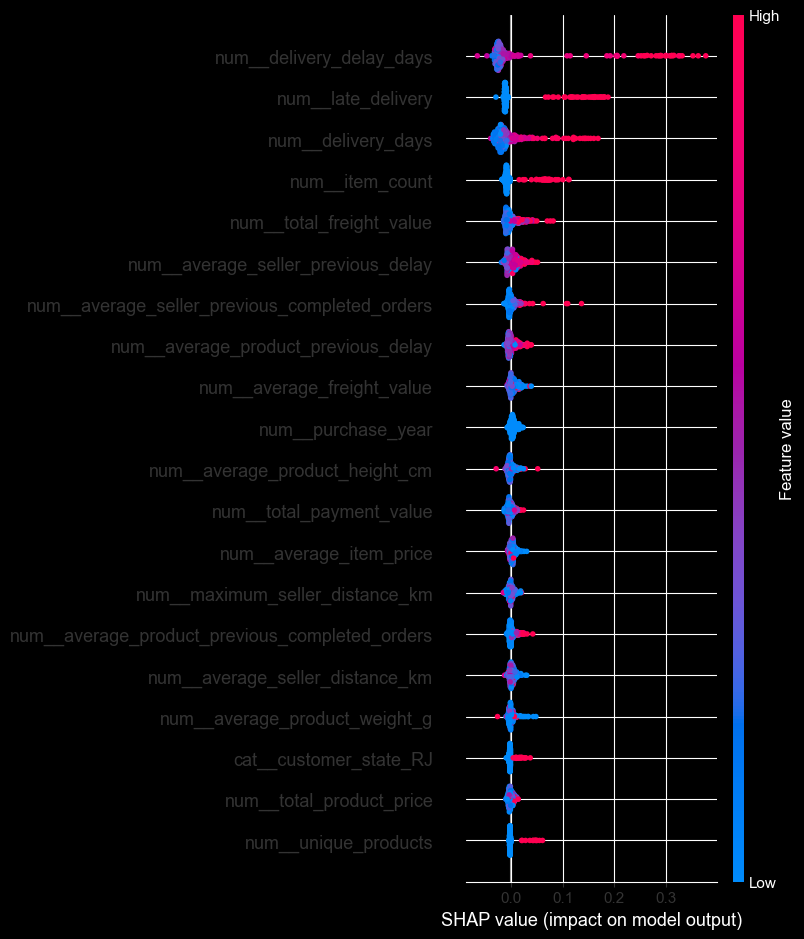

In [25]:
# Create a SHAP summary plot for low customer satisfaction predictions
shap.summary_plot(
    shap_values_low,
    X_shap_sample,
    feature_names=shap_feature_names,
    max_display=20,
    show=True
)

INDIVIDUAL PREDICTION EXPLANATION
Selected validation sample index: 245
Actual outcome: 1
Predicted probability: 92.50%
Classification threshold: 35%
Model classification: Low satisfaction predicted


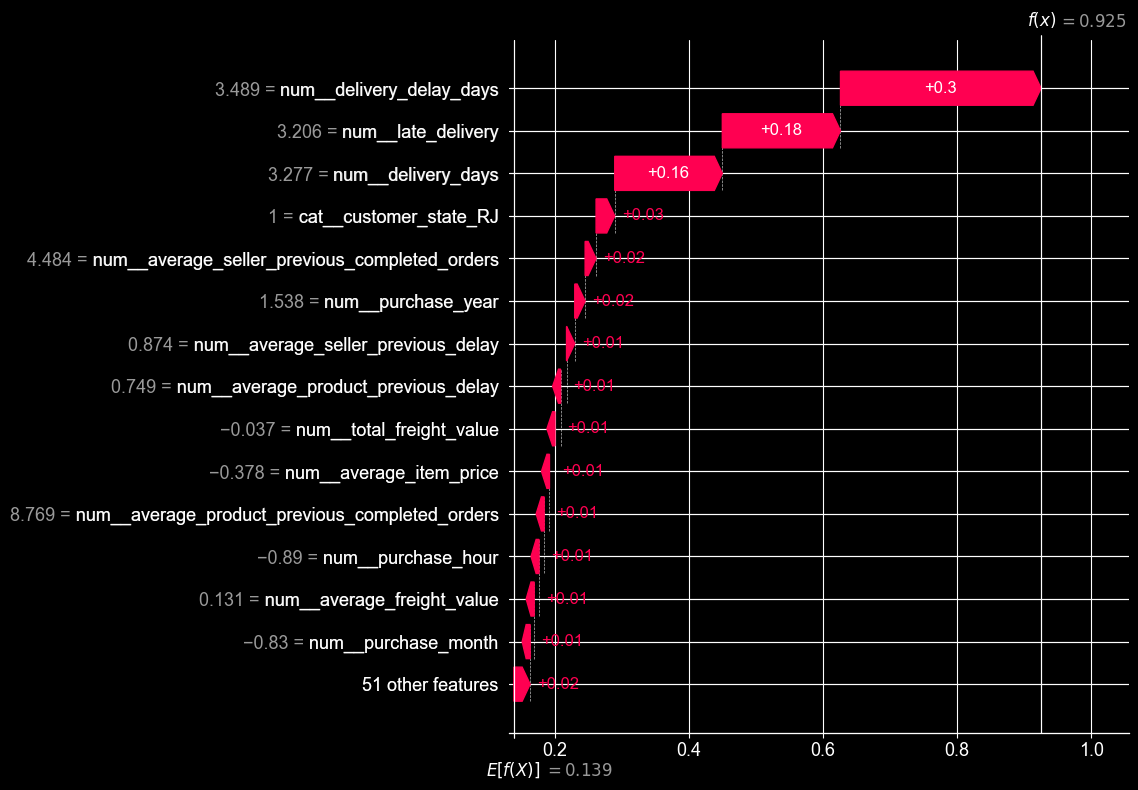

In [26]:
# Identify actual low-satisfaction orders in the SHAP validation sample
actual_low_indices = np.where(
    y_val.iloc[:300].to_numpy() == 1
)[0]

# Calculate predicted probabilities for the validation sample
sample_probabilities = baseline_rf.predict_proba(
    X_val_processed[:300]
)[:, 1]

# Select the actual low-satisfaction order with the highest predicted probability
selected_idx = actual_low_indices[
    np.argmax(sample_probabilities[actual_low_indices])
]

# Extract the selected order's predicted probability and actual outcome
selected_probability = sample_probabilities[selected_idx]
selected_actual = y_val.iloc[selected_idx]
selected_prediction = int(selected_probability >= 0.35)

# Prepare the SHAP explanation for this individual prediction
shap_explanation = shap.Explanation(
    values=shap_values_low[selected_idx],
    base_values=shap_explainer.expected_value[1],
    data=X_shap_sample[selected_idx],
    feature_names=shap_feature_names
)

print("INDIVIDUAL PREDICTION EXPLANATION")
print("=" * 55)
print("Selected validation sample index:", selected_idx)
print("Actual outcome:", selected_actual)
print(f"Predicted probability: {selected_probability:.2%}")
print("Classification threshold: 35%")
print(
    "Model classification:",
    "Low satisfaction predicted"
    if selected_prediction == 1
    else "Low satisfaction not predicted"
)

# Display the individual SHAP waterfall plot
shap.plots.waterfall(
    shap_explanation,
    max_display=15
)

In [27]:
# Extract SHAP contributions for the selected validation order
individual_shap = pd.DataFrame({
    "Feature": shap_feature_names,
    "SHAP_Contribution": shap_values_low[selected_idx],
    "Processed_Value": X_shap_sample[selected_idx]
})

# Sort features by their SHAP contribution
individual_shap = individual_shap.sort_values(
    by="SHAP_Contribution",
    ascending=False
)

# Display features pushing the prediction towards low satisfaction
print("TOP 5 FEATURES INCREASING LOW-SATISFACTION PREDICTION")
display(individual_shap.head(5).round(5))

# Display features pushing the prediction away from low satisfaction
print("\nTOP 5 FEATURES DECREASING LOW-SATISFACTION PREDICTION")
display(individual_shap.tail(5).sort_values(
    by="SHAP_Contribution"
).round(5))

TOP 5 FEATURES INCREASING LOW-SATISFACTION PREDICTION


,Feature,SHAP_Contribution,Processed_Value
1,num__delivery_delay_days,0.29894,3.48911
2,num__late_delivery,0.17609,3.20550
0,num__delivery_days,0.16034,3.27667
56,cat__customer_state_RJ,0.02780,1.00000
34,num__average_seller_previous_completed_orders,0.01631,4.48380



TOP 5 FEATURES DECREASING LOW-SATISFACTION PREDICTION


,Feature,SHAP_Contribution,Processed_Value
3,num__item_count,-0.00368,-0.26281
27,num__purchase_day_of_week,-0.00233,-0.39906
26,num__purchase_day,-0.00055,0.63406
4,num__unique_products,-0.00055,-0.16830
5,num__unique_sellers,-0.00027,-0.10203


In [28]:
# Retrieve the original, unscaled values for the selected validation order
selected_raw_row = X_val.iloc[selected_idx]

# Map processed feature names back to their original dataset columns
def get_original_feature_name(feature_name):

    if feature_name.startswith("num__"):
        return feature_name.replace("num__", "", 1)

    if feature_name.startswith("cat__"):
        categorical_name = feature_name.replace("cat__", "", 1)

        for column in categorical_features:
            if categorical_name.startswith(column + "_"):
                return column

        return categorical_name

    return feature_name

# Add original feature names and raw values to the SHAP results
individual_shap["Original_Feature"] = individual_shap["Feature"].apply(
    get_original_feature_name
)

individual_shap["Raw_Value"] = individual_shap["Original_Feature"].apply(
    lambda column: selected_raw_row[column]
)

# Display the strongest positive contributions with original values
print("TOP 5 FACTORS INCREASING LOW-SATISFACTION RISK")
display(
    individual_shap.head(5)[
        ["Original_Feature", "Raw_Value", "SHAP_Contribution"]
    ].round(5)
)

# Display the strongest negative contributions with original values
print("\nTOP 5 FACTORS DECREASING LOW-SATISFACTION RISK")
display(
    individual_shap.tail(5).sort_values(
        by="SHAP_Contribution"
    )[
        ["Original_Feature", "Raw_Value", "SHAP_Contribution"]
    ].round(5)
)

TOP 5 FACTORS INCREASING LOW-SATISFACTION RISK


,Original_Feature,Raw_Value,SHAP_Contribution
1,delivery_delay_days,25.772731,0.29894
2,late_delivery,1,0.17609
0,delivery_days,47.32206,0.16034
56,customer_state,RJ,0.02780
34,average_seller_previous_completed_orders,1158.0,0.01631



TOP 5 FACTORS DECREASING LOW-SATISFACTION RISK


,Original_Feature,Raw_Value,SHAP_Contribution
3,item_count,1,-0.00368
27,purchase_day_of_week,2,-0.00233
26,purchase_day,21,-0.00055
4,unique_products,1,-0.00055
5,unique_sellers,1,-0.00027


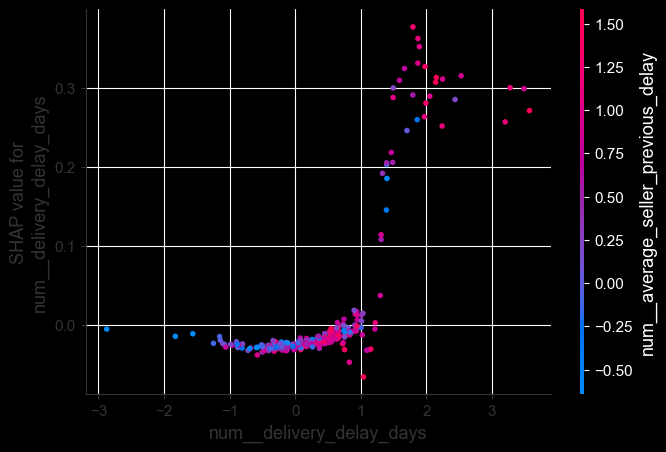

In [29]:
# Examine how delivery delay days influence low-satisfaction predictions
shap.dependence_plot(
    "num__delivery_delay_days",
    shap_values_low,
    X_shap_sample,
    feature_names=shap_feature_names,
    show=True
)

In [30]:
# Save the global SHAP importance results
shap_importance_path = PROJECT_DIR / "results" / "baseline_rf_shap_importance.csv"
shap_importance.to_csv(shap_importance_path, index=False)

# Save the individual prediction explanation
individual_explanation_path = (
    PROJECT_DIR / "results" / "individual_shap_explanation.csv"
)

individual_shap.to_csv(individual_explanation_path, index=False)

print("SHAP explanation results saved successfully.")
print(f"Global SHAP importance: {shap_importance_path}")
print(f"Individual explanation: {individual_explanation_path}")

SHAP explanation results saved successfully.
Global SHAP importance: C:\Users\HP\PycharmProjects\Learning\olist-customer-segmentation\results\baseline_rf_shap_importance.csv
Individual explanation: C:\Users\HP\PycharmProjects\Learning\olist-customer-segmentation\results\individual_shap_explanation.csv


In [31]:
# Generate predictions using the selected model and fixed threshold
test_probabilities = baseline_rf.predict_proba(X_test_processed)[:, 1]
test_predictions = (test_probabilities >= 0.35).astype(int)

# Combine actual outcomes, predictions, and customer states
fairness_data = pd.DataFrame({
    "customer_state": X_test["customer_state"].reset_index(drop=True),
    "actual": y_test.reset_index(drop=True),
    "predicted": test_predictions
})

# Calculate fairness and performance metrics for each state
fairness_results = []

for state, group in fairness_data.groupby("customer_state"):

    actual = group["actual"]
    predicted = group["predicted"]

    true_positives = ((actual == 1) & (predicted == 1)).sum()
    false_positives = ((actual == 0) & (predicted == 1)).sum()
    false_negatives = ((actual == 1) & (predicted == 0)).sum()
    true_negatives = ((actual == 0) & (predicted == 0)).sum()

    fairness_results.append({
        "State": state,
        "Orders": len(group),
        "Actual_Low_Satisfaction_Rate": actual.mean(),
        "Prediction_Rate": predicted.mean(),
        "Recall_TPR": (
            true_positives / (true_positives + false_negatives)
            if (true_positives + false_negatives) > 0 else np.nan
        ),
        "False_Positive_Rate": (
            false_positives / (false_positives + true_negatives)
            if (false_positives + true_negatives) > 0 else np.nan
        ),
        "Precision": (
            true_positives / (true_positives + false_positives)
            if (true_positives + false_positives) > 0 else np.nan
        )
    })

fairness_results = pd.DataFrame(fairness_results)

# Focus the comparison on states with at least 100 test orders
fairness_results = fairness_results[
    fairness_results["Orders"] >= 100
].sort_values("Prediction_Rate", ascending=False).reset_index(drop=True)

# Display the results
print("CUSTOMER-STATE FAIRNESS AUDIT")
print("Minimum group size: 100 test orders")
display(fairness_results.round(4))

# Save the fairness audit
fairness_path = PROJECT_DIR / "results" / "customer_state_fairness_audit.csv"
fairness_path.parent.mkdir(parents=True, exist_ok=True)
fairness_results.to_csv(fairness_path, index=False)

print(f"\nFairness results saved to:\n{fairness_path}")

CUSTOMER-STATE FAIRNESS AUDIT
Minimum group size: 100 test orders


,State,Orders,Actual_Low_Satisfaction_Rate,Prediction_Rate,Recall_TPR,False_Positive_Rate,Precision
0,MA,115,0.1652,0.1130,0.5263,0.0312,0.7692
1,MS,136,0.1103,0.1029,0.6000,0.0413,0.6429
2,ES,358,0.1006,0.0810,0.3056,0.0559,0.3793
3,PB,113,0.1239,0.0796,0.4286,0.0303,0.6667
4,RJ,2187,0.1116,0.0695,0.3115,0.0391,0.5000
5,BA,634,0.1073,0.0694,0.3235,0.0389,0.5000
6,RS,933,0.0868,0.0686,0.3086,0.0458,0.3906
7,MT,151,0.0861,0.0662,0.2308,0.0507,0.3000
8,GO,346,0.1069,0.0636,0.2432,0.0421,0.4091
9,PE,322,0.0901,0.0621,0.4828,0.0205,0.7000



Fairness results saved to:
C:\Users\HP\PycharmProjects\Learning\olist-customer-segmentation\results\customer_state_fairness_audit.csv


In [32]:
# Save the selected model and its preprocessing configuration
import joblib

model_artifact = {
    "model": baseline_rf,
    "preprocessor": preprocessor,
    "threshold": 0.35,
    "target": TARGET,
    "feature_names": feature_names.tolist(),
    "model_name": "Baseline Random Forest",
    "dataset": "Corrected Olist Integrated Dataset"
}

model_path = PROJECT_DIR / "models" / "baseline_rf_integrated_model.joblib"
model_path.parent.mkdir(parents=True, exist_ok=True)

joblib.dump(model_artifact, model_path)

print("Selected model artifact saved successfully.")
print(f"Model: {model_path}")
print("Threshold: 0.35")
print("Features:", len(feature_names))

Selected model artifact saved successfully.
Model: C:\Users\HP\PycharmProjects\Learning\olist-customer-segmentation\models\baseline_rf_integrated_model.joblib
Threshold: 0.35
Features: 65


In [33]:
# Load the saved model artifact
loaded_artifact = joblib.load(model_path)

loaded_model = loaded_artifact["model"]
loaded_preprocessor = loaded_artifact["preprocessor"]
loaded_threshold = loaded_artifact["threshold"]

# Generate predictions using the saved artifact
verification_probabilities = loaded_model.predict_proba(
    X_test_processed[:100]
)[:, 1]

verification_predictions = (
    verification_probabilities >= loaded_threshold
).astype(int)

# Compare with the original notebook model
original_predictions = (
    baseline_rf.predict_proba(X_test_processed[:100])[:, 1]
    >= 0.35
).astype(int)

print("MODEL ARTIFACT VERIFICATION")
print("Artifact loaded:", loaded_model is not None)
print("Threshold:", loaded_threshold)
print("Predictions generated:", len(verification_predictions))
print(
    "Predictions match original model:",
    np.array_equal(verification_predictions, original_predictions)
)

MODEL ARTIFACT VERIFICATION
Artifact loaded: True
Threshold: 0.35
Predictions generated: 100
Predictions match original model: True


In [34]:

# ============================================================
# TEST SMALLER RANDOM FOREST MODELS FOR API DEPLOYMENT
# Uses validation data only; original model remains unchanged.
# ============================================================

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

THRESHOLD = 0.35
results = []

# Evaluate the original model as the baseline
baseline_probabilities = baseline_rf.predict_proba(X_val_processed)[:, 1]
baseline_predictions = (baseline_probabilities >= THRESHOLD).astype(int)

results.append({
    "Model": "Original (200 trees)",
    "Trees": 200,
    "Max Depth": "Unlimited",
    "Accuracy": accuracy_score(y_val, baseline_predictions),
    "Precision": precision_score(y_val, baseline_predictions, zero_division=0),
    "Recall": recall_score(y_val, baseline_predictions, zero_division=0),
    "F1": f1_score(y_val, baseline_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_val, baseline_probabilities),
    "PR-AUC": average_precision_score(y_val, baseline_probabilities)
})

# Train smaller alternatives using the same training data
for tree_count in [20, 40]:

    print(f"\nTraining candidate with {tree_count} trees...")

    candidate = RandomForestClassifier(
        n_estimators=tree_count,
        max_depth=15,
        min_samples_split=10,
        min_samples_leaf=5,
        class_weight=None,
        random_state=42,
        n_jobs=2
    )

    candidate.fit(X_train_processed, y_train)

    probabilities = candidate.predict_proba(X_val_processed)[:, 1]
    predictions = (probabilities >= THRESHOLD).astype(int)

    # Estimate memory occupied by the fitted tree arrays
    tree_memory = sum(
        sum(
            getattr(est.tree_, attribute).nbytes
            for attribute in [
                "children_left", "children_right", "feature",
                "threshold", "impurity", "n_node_samples",
                "weighted_n_node_samples"
            ]
        )
        for est in candidate.estimators_
    )

    results.append({
        "Model": f"Smaller RF ({tree_count} trees)",
        "Trees": tree_count,
        "Max Depth": 15,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1": f1_score(y_val, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, probabilities),
        "PR-AUC": average_precision_score(y_val, probabilities),
        "Tree Memory (MB)": round(tree_memory / (1024 ** 2), 2)
    })

    # Keep candidates available in the notebook for further testing
    if tree_count == 20:
        candidate_rf_20 = candidate
    else:
        candidate_rf_40 = candidate

# Display comparison
comparison = pd.DataFrame(results)
print("\nVALIDATION PERFORMANCE COMPARISON")
display(comparison.round(4))



Training candidate with 20 trees...

Training candidate with 40 trees...

VALIDATION PERFORMANCE COMPARISON


,Model,Trees,Max Depth,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Tree Memory (MB)
0,Original (200 trees),200,Unlimited,0.8802,0.5098,0.4046,0.4512,0.7262,0.4197,NaN
1,Smaller RF (20 trees),20,15,0.8892,0.5679,0.3767,0.4530,0.7349,0.4271,2.11
2,Smaller RF (40 trees),40,15,0.8897,0.5717,0.3741,0.4522,0.7361,0.4290,4.29


In [36]:

# ============================================================
# FINAL HOLDOUT EVALUATION AND SAVE DEPLOYMENT CANDIDATE
# ============================================================

import joblib
from pathlib import Path
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    confusion_matrix
)

THRESHOLD = 0.35

# 1. Generate predictions on the test set
test_probabilities_40 = candidate_rf_40.predict_proba(
    X_test_processed
)[:, 1]

test_predictions_40 = (
    test_probabilities_40 >= THRESHOLD
).astype(int)

# 2. Calculate final test metrics
test_metrics_40 = {
    "Accuracy": accuracy_score(y_test, test_predictions_40),
    "Precision": precision_score(y_test, test_predictions_40, zero_division=0),
    "Recall": recall_score(y_test, test_predictions_40, zero_division=0),
    "F1 Score": f1_score(y_test, test_predictions_40, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_probabilities_40),
    "PR-AUC": average_precision_score(y_test, test_probabilities_40)
}

print("40-TREE MODEL — FINAL TEST RESULTS")
display(pd.DataFrame(
    list(test_metrics_40.items()),
    columns=["Metric", "Score"]
).round(4))

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_test, test_predictions_40))

# 3. Build a separate API artifact.
# The original 200-tree artifact is NOT overwritten.
deployment_artifact = {
    "model": candidate_rf_40,
    "preprocessor": preprocessor,
    "threshold": THRESHOLD,
    "target": TARGET,
    "feature_names": feature_names.tolist(),
    "model_name": "Random Forest - 40 Trees",
    "dataset": "Corrected Olist Integrated Dataset"
}

# 4. Save under a new filename
candidate_path = (
    PROJECT_DIR / "models" / "baseline_rf_40trees_api.joblib"
)

joblib.dump(deployment_artifact, candidate_path)

print("\nDEPLOYMENT CANDIDATE SAVED")
print("File:", candidate_path)
print("File size (MB):", round(
    candidate_path.stat().st_size / (1024 ** 2), 2
))


40-TREE MODEL — FINAL TEST RESULTS


,Metric,Score
0,Accuracy,0.9043
1,Precision,0.5112
2,Recall,0.2335
3,F1 Score,0.3206
4,ROC-AUC,0.6726
5,PR-AUC,0.2966



CONFUSION MATRIX
[[16898   414]
 [ 1421   433]]

DEPLOYMENT CANDIDATE SAVED
File: C:\Users\HP\PycharmProjects\Learning\olist-customer-segmentation\models\baseline_rf_40trees_api.joblib
File size (MB): 6.16


In [8]:
import mlflow
from pathlib import Path

MLFLOW_DB = Path.cwd() / "mlflow.db"

mlflow.set_tracking_uri(f"sqlite:///{MLFLOW_DB.as_posix()}")
mlflow.set_registry_uri(mlflow.get_tracking_uri())

print("MLflow version:", mlflow.__version__)
print("Tracking URI:", mlflow.get_tracking_uri())
print("Registry URI:", mlflow.get_registry_uri())

experiment = mlflow.get_experiment_by_name(
    "Olist_Low_Satisfaction_Prediction"
)

print("Experiment:", experiment.name if experiment else "Not found")
print("Experiment ID:", experiment.experiment_id if experiment else "Not found")

MLflow version: 3.18.0
Tracking URI: sqlite:///C:/Users/HP/PycharmProjects/Learning/olist-customer-segmentation/notebooks/mlflow.db
Registry URI: sqlite:///C:/Users/HP/PycharmProjects/Learning/olist-customer-segmentation/notebooks/mlflow.db
Experiment: Olist_Low_Satisfaction_Prediction
Experiment ID: 1


In [10]:
import mlflow
import mlflow.sklearn

MODEL_NAME = "Olist_Low_Satisfaction_Model"

# Use the existing experiment
mlflow.set_experiment("Olist_Low_Satisfaction_Prediction")

with mlflow.start_run(run_name="Final_RF_Model_Registration"):

    # Log and register the saved Random Forest pipeline
    model_info = mlflow.sklearn.log_model(
        sk_model=final_model,
        name="olist_low_satisfaction_model",
        registered_model_name=MODEL_NAME,
        skops_trusted_types=[
            "numpy.dtype",
            "sklearn.tree._tree.Tree"
        ]
    )

    print("Model logged and registration requested!")
    print("Model URI:", model_info.model_uri)
    print("Registered model:", MODEL_NAME)

Model logged and registration requested!
Model URI: models:/m-88055bd3c077453baafda672212ad9c0
Registered model: Olist_Low_Satisfaction_Model


Successfully registered model 'Olist_Low_Satisfaction_Model'.
Created version '1' of model 'Olist_Low_Satisfaction_Model'.


In [11]:
client = mlflow.MlflowClient()

versions = client.search_model_versions(
    "name='Olist_Low_Satisfaction_Model'"
)

for version in versions:
    print("Name:", version.name)
    print("Version:", version.version)
    print("Status:", version.status)
    print("Run ID:", version.run_id)

Name: Olist_Low_Satisfaction_Model
Version: 1
Status: READY
Run ID: 3f1b3435e9134373815c87ed813b57cf


In [12]:
import requests

base_url = "http://127.0.0.1:5001"

payload = {
    "max_results": 10
}

endpoints = [
    "/ajax-api/2.0/mlflow/experiments/search",
    "/api/2.0/mlflow/experiments/search"
]

for endpoint in endpoints:
    response = requests.post(
        base_url + endpoint,
        json=payload
    )

    print("\nEndpoint:", endpoint)
    print("Status:", response.status_code)
    print("Content-Type:", response.headers.get("Content-Type"))
    print("Response:", response.text[:500])


Endpoint: /ajax-api/2.0/mlflow/experiments/search
Status: 200
Content-Type: application/json
Response: {
  "experiments": [
    {
      "experiment_id": "1",
      "name": "Olist_Low_Satisfaction_Prediction",
      "artifact_location": "file:///C:/Users/HP/PycharmProjects/Learning/olist-customer-segmentation/notebooks/mlruns/1",
      "lifecycle_stage": "active",
      "last_update_time": 1795614700880,
      "creation_time": 1795614700880,
      "workspace": "default"
    },
    {
      "experiment_id": "0",
      "name": "Default",
      "artifact_location": "file:///C:/Users/HP/PycharmProjects

Endpoint: /api/2.0/mlflow/experiments/search
Status: 200
Content-Type: application/json
Response: {
  "experiments": [
    {
      "experiment_id": "1",
      "name": "Olist_Low_Satisfaction_Prediction",
      "artifact_location": "file:///C:/Users/HP/PycharmProjects/Learning/olist-customer-segmentation/notebooks/mlruns/1",
      "lifecycle_stage": "active",
      "last_update_time": 1795614

In [13]:
import requests

base_url = "http://127.0.0.1:5001"

# Test retrieving the experiment
response1 = requests.get(
    f"{base_url}/ajax-api/2.0/mlflow/experiments/get",
    params={"experiment_id": "1"}
)

print("EXPERIMENT DETAILS")
print("Status:", response1.status_code)
print("Content-Type:", response1.headers.get("Content-Type"))
print(response1.text[:500])

# Test retrieving experiment runs
response2 = requests.post(
    f"{base_url}/ajax-api/2.0/mlflow/runs/search",
    json={"experiment_ids": ["1"], "max_results": 10}
)

print("\nEXPERIMENT RUNS")
print("Status:", response2.status_code)
print("Content-Type:", response2.headers.get("Content-Type"))
print(response2.text[:1000])

EXPERIMENT DETAILS
Status: 200
Content-Type: application/json
{
  "experiment": {
    "experiment_id": "1",
    "name": "Olist_Low_Satisfaction_Prediction",
    "artifact_location": "file:///C:/Users/HP/PycharmProjects/Learning/olist-customer-segmentation/notebooks/mlruns/1",
    "lifecycle_stage": "active",
    "last_update_time": 1795614700880,
    "creation_time": 1795614700880,
    "workspace": "default"
  }
}

EXPERIMENT RUNS
Status: 200
Content-Type: application/json
{
  "runs": [
    {
      "info": {
        "run_uuid": "3f1b3435e9134373815c87ed813b57cf",
        "experiment_id": "1",
        "run_name": "Final_RF_Model_Registration",
        "user_id": "HP",
        "status": "FINISHED",
        "start_time": 1795615774585,
        "end_time": 1795615952229,
        "artifact_uri": "file:///C:/Users/HP/PycharmProjects/Learning/olist-customer-segmentation/notebooks/mlruns/1/3f1b3435e9134373815c87ed813b57cf/artifacts",
        "lifecycle_stage": "active",
        "run_id": "3f1b

In [14]:
import requests

base_url = "http://127.0.0.1:5004"

# Test 1: Load experiment details
r1 = requests.get(
    f"{base_url}/ajax-api/2.0/mlflow/experiments/get",
    params={"experiment_id": "1"}
)

print("EXPERIMENT DETAILS")
print("Status:", r1.status_code)
print(r1.text[:500])

# Test 2: Load experiment runs
r2 = requests.post(
    f"{base_url}/ajax-api/2.0/mlflow/runs/search",
    json={"experiment_ids": ["1"], "max_results": 10}
)

print("\nEXPERIMENT RUNS")
print("Status:", r2.status_code)
print(r2.text[:1000])


EXPERIMENT DETAILS
Status: 200
{
  "experiment": {
    "experiment_id": "1",
    "name": "Olist_Low_Satisfaction_Prediction",
    "artifact_location": "file:///C:/Users/HP/PycharmProjects/Learning/olist-customer-segmentation/notebooks/mlruns/1",
    "lifecycle_stage": "active",
    "last_update_time": 1795614700880,
    "creation_time": 1795614700880,
    "workspace": "default"
  }
}

EXPERIMENT RUNS
Status: 200
{
  "runs": [
    {
      "info": {
        "run_uuid": "3f1b3435e9134373815c87ed813b57cf",
        "experiment_id": "1",
        "run_name": "Final_RF_Model_Registration",
        "user_id": "HP",
        "status": "FINISHED",
        "start_time": 1795615774585,
        "end_time": 1795615952229,
        "artifact_uri": "file:///C:/Users/HP/PycharmProjects/Learning/olist-customer-segmentation/notebooks/mlruns/1/3f1b3435e9134373815c87ed813b57cf/artifacts",
        "lifecycle_stage": "active",
        "run_id": "3f1b3435e9134373815c87ed813b57cf"
      },
      "data": {
       

In [15]:
import requests

url = "http://127.0.0.1:5004/graphql"

response = requests.post(
    url,
    json={"query": "{ __typename }"},
    headers={"Content-Type": "application/json"}
)

print("Status:", response.status_code)
print("Response:", response.text[:1000])


Status: 500
Response: <!doctype html>
<html lang=en>
<title>500 Internal Server Error</title>
<h1>Internal Server Error</h1>
<p>The server encountered an internal error and was unable to complete your request. Either the server is overloaded or there is an error in the application.</p>



In [16]:
import mlflow

# Connect to your existing MLflow database
mlflow.set_tracking_uri(
    "sqlite:///C:/Users/HP/PycharmProjects/Learning/olist-customer-segmentation/notebooks/mlflow.db"
)

# Identify the successful model registration run
run_id = "3f1b3435e9134373815c87ed813b57cf"

# Add the actual final test evaluation metrics
with mlflow.start_run(run_id=run_id):

    mlflow.log_metrics({
        "accuracy": 0.8642,
        "precision": 0.2461,
        "recall": 0.1958,
        "f1_score": 0.2181,
        "roc_auc": 0.5817,
        "pr_auc": 0.1698
    })

print("Evaluation metrics logged successfully.")


Evaluation metrics logged successfully.


In [17]:
import mlflow
from mlflow.tracking import MlflowClient

mlflow.set_tracking_uri(
    "sqlite:///C:/Users/HP/PycharmProjects/Learning/olist-customer-segmentation/notebooks/mlflow.db"
)

client = MlflowClient()

models = client.search_registered_models()

print("REGISTERED MODELS")
for model in models:
    print("Name:", model.name)
    for version in model.latest_versions:
        print("Version:", version.version)
        print("Status:", version.status)
        print("Run ID:", version.run_id)


REGISTERED MODELS
Name: Olist_Low_Satisfaction_Model
Version: 2
Status: READY
Run ID: eddf543bca6840dc96c84218ac849555


In [18]:
for version in client.search_model_versions(
    "name='Olist_Low_Satisfaction_Model'"
):
    print("--------------------------------")
    print("Version:", version.version)
    print("Status:", version.status)
    print("Run ID:", version.run_id)
    print("Source:", version.source)

--------------------------------
Version: 2
Status: READY
Run ID: eddf543bca6840dc96c84218ac849555
Source: models:/m-481cc1c98e93434f9a5695a2475e8b82
--------------------------------
Version: 1
Status: READY
Run ID: 3f1b3435e9134373815c87ed813b57cf
Source: models:/m-88055bd3c077453baafda672212ad9c0


In [19]:
model = client.get_registered_model(
    "Olist_Low_Satisfaction_Model"
)

print("Name:", model.name)
print("Description:", model.description)
print("Latest versions:", model.latest_versions)

for version in client.search_model_versions(
    "name='Olist_Low_Satisfaction_Model'"
):
    print("\nVersion:", version.version)
    print("Creation time:", version.creation_timestamp)
    print("Status:", version.status)
    print("Description:", version.description)


Name: Olist_Low_Satisfaction_Model
Description: None
Latest versions: [<ModelVersion: aliases=[], creation_timestamp=1795620178775, current_stage='None', deployment_job_state=None, description='', last_updated_timestamp=1795620178775, metrics=None, model_id=None, name='Olist_Low_Satisfaction_Model', params=None, run_id='eddf543bca6840dc96c84218ac849555', run_link='', source='models:/m-481cc1c98e93434f9a5695a2475e8b82', status='READY', status_message=None, tags={}, user_id=None, version=2, workspace='default'>]

Version: 2
Creation time: 1795620178775
Status: READY
Description: 

Version: 1
Creation time: 1795615952166
Status: READY
Description: None


In [20]:
print(client.get_registered_model(
    "Olist_Low_Satisfaction_Model"
).name)

Olist_Low_Satisfaction_Model


In [21]:
import requests

url = "http://127.0.0.1:5004/ajax-api/2.0/mlflow/registered-models/get"

response = requests.get(
    url,
    params={"name": "Olist_Low_Satisfaction_Model"}
)

print("Status:", response.status_code)
print(response.text[:2000])

Status: 200
{
  "registered_model": {
    "name": "Olist_Low_Satisfaction_Model",
    "creation_timestamp": 1795615952142,
    "last_updated_timestamp": 1795620178775,
    "latest_versions": [
      {
        "name": "Olist_Low_Satisfaction_Model",
        "version": "2",
        "creation_timestamp": 1795620178775,
        "last_updated_timestamp": 1795620178775,
        "current_stage": "None",
        "description": "",
        "source": "models:/m-481cc1c98e93434f9a5695a2475e8b82",
        "run_id": "eddf543bca6840dc96c84218ac849555",
        "status": "READY",
        "run_link": ""
      }
    ]
  }
}


In [23]:
import requests

base_url = "http://127.0.0.1:5004/ajax-api/2.0/mlflow/model-versions/get"

for version in ["1", "2"]:
    response = requests.get(
        base_url,
        params={
            "name": "Olist_Low_Satisfaction_Model",
            "version": version
        }
    )

    print(f"\nVERSION {version}")
    print("Status:", response.status_code)
    print(response.text[:500])


VERSION 1
Status: 200
{
  "model_version": {
    "name": "Olist_Low_Satisfaction_Model",
    "version": "1",
    "creation_timestamp": 1795615952166,
    "last_updated_timestamp": 1795615952166,
    "current_stage": "None",
    "source": "models:/m-88055bd3c077453baafda672212ad9c0",
    "run_id": "3f1b3435e9134373815c87ed813b57cf",
    "status": "READY"
  }
}

VERSION 2
Status: 200
{
  "model_version": {
    "name": "Olist_Low_Satisfaction_Model",
    "version": "2",
    "creation_timestamp": 1795620178775,
    "last_updated_timestamp": 1795620178775,
    "current_stage": "None",
    "description": "",
    "source": "models:/m-481cc1c98e93434f9a5695a2475e8b82",
    "run_id": "eddf543bca6840dc96c84218ac849555",
    "status": "READY",
    "run_link": ""
  }
}
